In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [2]:
# Đọc dữ liệu
df_uni = pd.read_csv("../data/raw/dataset_uni.csv")
df_multi = pd.read_csv("../data/raw/dataset_multi.csv")

# Chuyển Date thành kiểu ngày tháng
df_uni["Date"] = pd.to_datetime(df_uni["Date"])
df_multi["Date"] = pd.to_datetime(df_multi["Date"])

# Sắp xếp dữ liệu theo thời gian
df_uni = df_uni.sort_values("Date").reset_index(drop=True)
df_multi = df_multi.sort_values("Date").reset_index(drop=True)

# Kiểm tra dữ liệu
print("Univariate:", df_uni.shape)
print("Multivariate:", df_multi.shape)

display(df_uni.head())
display(df_multi.head())

Univariate: (4215, 2)
Multivariate: (4215, 8)


,Date,wti
0,2006-10-16,59.91
1,2006-10-17,58.91
2,2006-10-18,57.66
3,2006-10-19,58.55
4,2006-10-20,57.35


,Date,wti,GP,coal,TB,LTY,EPI,SRV
0,2006-10-16,59.91,5.13,49.049999,4.96,4.6,42.85,0.000002
1,2006-10-17,58.91,6.26,49.250000,4.96,4.6,143.06,0.000002
2,2006-10-18,57.66,6.07,49.400002,4.96,4.6,28.55,0.000002
3,2006-10-19,58.55,6.77,48.750000,4.97,4.6,20.71,0.000002
4,2006-10-20,57.35,6.88,49.000000,4.96,4.6,88.78,0.000002


In [3]:
# Chuẩn bị dữ liệu Univariate
data_uni_model = df_uni[["Date", "wti"]].copy()

lags_uni = [1, 2, 3, 5, 10, 20]

for lag in lags_uni:
    data_uni_model[f"WTI_Lag{lag}"] = (
        data_uni_model["wti"].shift(lag)
    )

# Loại 20 dòng đầu do Lag lớn nhất là 20
data_uni_model = (
    data_uni_model.iloc[20:]
    .reset_index(drop=True)
)

# Danh sách biến đầu vào
features_uni = [
    col for col in data_uni_model.columns
    if col.startswith("WTI_Lag")
]

print("Univariate:", data_uni_model.shape)
print("Số Features:", len(features_uni))
print("Ngày bắt đầu:", data_uni_model["Date"].min())
print("Ngày kết thúc:", data_uni_model["Date"].max())

Univariate: (4195, 8)
Số Features: 6
Ngày bắt đầu: 2006-11-13 00:00:00
Ngày kết thúc: 2023-07-24 00:00:00


In [4]:

import pandas as pd
import numpy as np

# Đọc dữ liệu đa biến ban đầu
df_clean = pd.read_csv("../data/raw/dataset_multi.csv")

df_clean["Date"] = pd.to_datetime(df_clean["Date"])

df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Chỉ giữ những biến cần thiết
df_clean = df_clean[
    ["Date", "wti", "GP", "coal", "EPI"]
].copy()


# =====================================
# 1. XỬ LÝ TB TỪ DỮ LIỆU GỐC
# =====================================

tb_raw = pd.read_excel(
    "../data/raw/dataset.xlsx",
    sheet_name="Treasury bill rate "
)

tb_raw["date"] = pd.to_datetime(tb_raw["date"])

tb_raw = tb_raw.rename(columns={"date": "Date"})

df_clean = df_clean.merge(
    tb_raw[["Date", "TB"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Chỉ sử dụng giá trị đã quan sát trong quá khứ
df_clean["TB"] = df_clean["TB"].ffill()


# =====================================
# 2. XỬ LÝ SRV TỪ DỮ LIỆU GỐC
# =====================================

srv_raw = pd.read_excel(
    "../data/raw/dataset.xlsx",
    sheet_name="Stock return variance "
)

srv_raw["date"] = pd.to_datetime(srv_raw["date"])

srv_raw = srv_raw.rename(columns={"date": "Date"})

df_clean = df_clean.merge(
    srv_raw[["Date", "SRV"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Không bfill SRV.
# Chỉ điền bằng giá trị đã xuất hiện trước đó.
df_clean["SRV"] = df_clean["SRV"].ffill()


# =====================================
# 3. LOẠI GIAI ĐOẠN CHƯA CÓ SRV
# =====================================

first_srv_date = df_clean.loc[
    df_clean["SRV"].notna(), "Date"
].min()

df_clean = df_clean[
    df_clean["Date"] >= first_srv_date
].copy().reset_index(drop=True)


# =====================================
# 4. TẠO LAG FEATURES
# =====================================

features = ["wti", "GP", "coal", "TB", "EPI", "SRV"]

lags = [1, 2, 3, 5, 10, 20]

for feature in features:
    for lag in lags:
        df_clean[f"{feature}_Lag{lag}"] = (
            df_clean[feature].shift(lag)
        )

# Tạo mục tiêu
df_clean["WTI_Change"] = (
    df_clean["wti"] - df_clean["wti_Lag1"]
)

# Loại 20 dòng đầu do lag lớn nhất là 20
df_clean = (
    df_clean.iloc[20:]
    .reset_index(drop=True)
)


# =====================================
# 5. KIỂM TRA KẾT QUẢ
# =====================================

print("Kích thước dữ liệu:", df_clean.shape)

print("Ngày bắt đầu:", df_clean["Date"].min())
print("Ngày kết thúc:", df_clean["Date"].max())

print("Số giá trị thiếu TB:", df_clean["TB"].isna().sum())
print("Số giá trị thiếu SRV:", df_clean["SRV"].isna().sum())

print("\n20 dòng đầu:")
display(df_clean.head(20))


Kích thước dữ liệu: (2473, 44)
Ngày bắt đầu: 2013-09-16 00:00:00
Ngày kết thúc: 2023-07-24 00:00:00
Số giá trị thiếu TB: 0
Số giá trị thiếu SRV: 0

20 dòng đầu:


,Date,wti,GP,coal,EPI,TB,SRV,wti_Lag1,wti_Lag2,wti_Lag3,...,EPI_Lag5,EPI_Lag10,EPI_Lag20,SRV_Lag1,SRV_Lag2,SRV_Lag3,SRV_Lag5,SRV_Lag10,SRV_Lag20,WTI_Change
0,2013-09-16,106.54,3.64,76.900002,149.94,0.02,6.078676e-06,108.31,108.72,107.65,...,59.96,91.16,76.50,1.386240e-06,2.162643e-06,1.751830e-06,1.864801e-05,1.906504e-06,2.066540e-06,-1.77
1,2013-09-17,105.36,3.77,77.699997,127.79,0.01,3.341146e-06,106.54,108.31,108.72,...,53.00,168.05,136.62,6.078676e-06,1.386240e-06,2.162643e-06,1.010329e-05,1.906504e-06,6.605338e-06,-1.18
2,2013-09-18,108.23,3.72,78.150002,84.39,0.01,2.763343e-05,105.36,106.54,108.31,...,96.02,133.57,111.56,3.341146e-06,6.078676e-06,1.386240e-06,1.751830e-06,1.232666e-05,2.743606e-06,2.87
3,2013-09-19,106.26,3.73,78.000000,87.37,0.01,6.417766e-07,108.23,105.36,106.54,...,59.84,121.68,96.17,2.763343e-05,3.341146e-06,6.078676e-06,2.162643e-06,2.757501e-07,6.337054e-06,-1.97
4,2013-09-20,104.70,3.68,77.699997,160.51,0.01,9.895024e-06,106.26,108.23,105.36,...,39.94,174.48,89.29,6.417766e-07,2.763343e-05,3.341146e-06,1.386240e-06,5.576890e-10,1.389299e-05,-1.56
5,2013-09-23,103.62,3.66,78.300003,105.52,0.02,4.221073e-06,104.70,106.26,108.23,...,149.94,59.96,45.99,9.895024e-06,6.417766e-07,2.763343e-05,6.078676e-06,1.864801e-05,2.926771e-06,-1.08
6,2013-09-24,103.22,3.59,78.300003,127.69,0.02,1.275572e-06,103.62,104.70,106.26,...,127.79,53.00,124.03,4.221073e-06,9.895024e-06,6.417766e-07,3.341146e-06,1.010329e-05,3.090430e-06,-0.40
7,2013-09-25,102.68,3.52,78.449997,134.20,0.02,1.419342e-06,103.22,103.62,104.70,...,84.39,96.02,86.16,1.275572e-06,4.221073e-06,9.895024e-06,2.763343e-05,1.751830e-06,4.829371e-05,-0.54
8,2013-09-26,103.10,3.49,78.449997,83.62,0.00,2.283312e-06,102.68,103.22,103.62,...,87.37,59.84,64.04,1.419342e-06,1.275572e-06,4.221073e-06,6.417766e-07,2.162643e-06,1.420044e-06,0.42
9,2013-09-27,102.86,3.51,78.300003,91.83,0.02,3.142932e-06,103.10,102.68,103.22,...,160.51,39.94,87.64,2.283312e-06,1.419342e-06,1.275572e-06,9.895024e-06,1.386240e-06,7.256254e-07,-0.24


In [5]:
# Sử dụng dữ liệu đã xử lý sạch từ df_clean
data_multi = df_clean.copy()

print("Kích thước:", data_multi.shape)
print("Các cột:", data_multi.columns.tolist())

display(data_multi.head())

Kích thước: (2473, 44)
Các cột: ['Date', 'wti', 'GP', 'coal', 'EPI', 'TB', 'SRV', 'wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20', 'TB_Lag1', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20', 'WTI_Change']


,Date,wti,GP,coal,EPI,TB,SRV,wti_Lag1,wti_Lag2,wti_Lag3,...,EPI_Lag5,EPI_Lag10,EPI_Lag20,SRV_Lag1,SRV_Lag2,SRV_Lag3,SRV_Lag5,SRV_Lag10,SRV_Lag20,WTI_Change
0,2013-09-16,106.54,3.64,76.900002,149.94,0.02,6.078676e-06,108.31,108.72,107.65,...,59.96,91.16,76.50,1.386240e-06,0.000002,0.000002,0.000019,1.906504e-06,0.000002,-1.77
1,2013-09-17,105.36,3.77,77.699997,127.79,0.01,3.341146e-06,106.54,108.31,108.72,...,53.00,168.05,136.62,6.078676e-06,0.000001,0.000002,0.000010,1.906504e-06,0.000007,-1.18
2,2013-09-18,108.23,3.72,78.150002,84.39,0.01,2.763343e-05,105.36,106.54,108.31,...,96.02,133.57,111.56,3.341146e-06,0.000006,0.000001,0.000002,1.232666e-05,0.000003,2.87
3,2013-09-19,106.26,3.73,78.000000,87.37,0.01,6.417766e-07,108.23,105.36,106.54,...,59.84,121.68,96.17,2.763343e-05,0.000003,0.000006,0.000002,2.757501e-07,0.000006,-1.97
4,2013-09-20,104.70,3.68,77.699997,160.51,0.01,9.895024e-06,106.26,108.23,105.36,...,39.94,174.48,89.29,6.417766e-07,0.000028,0.000003,0.000001,5.576890e-10,0.000014,-1.56


In [6]:
# Danh sách các biến đầu vào
features_multi = [
    col for col in data_multi.columns
    if "_Lag" in col and col.strip() != "TB_Lag1"
]

target = "wti"

print("Số lượng biến đầu vào:", len(features_multi))
print(features_multi)

print(
    "TB_Lag1 còn trong Features:",
    "TB_Lag1" in features_multi
)

Số lượng biến đầu vào: 35
['wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20']
TB_Lag1 còn trong Features: False


In [7]:
# Bộ dữ liệu Multivariate cuối cùng
data_multi_model = data_multi.copy().reset_index(drop=True)

# Danh sách Features, loại bỏ TB_Lag1
features_multi = [
    col for col in data_multi_model.columns
    if "_Lag" in col and col.strip() != "TB_Lag1"
]

target = "wti"

# Kiểm tra dữ liệu
assert "WTI_Change" in data_multi_model.columns
assert "TB_Lag1" not in features_multi
assert len(features_multi) == 35
assert data_multi_model["SRV"].notna().all()
assert data_multi_model["TB"].notna().all()

print("Multivariate:", data_multi_model.shape)
print("Số Features:", len(features_multi))
print("TB_Lag1 còn trong Features:", "TB_Lag1" in features_multi)
print("Có WTI_Change:", "WTI_Change" in data_multi_model.columns)
print("Ngày bắt đầu:", data_multi_model["Date"].min())
print("Ngày kết thúc:", data_multi_model["Date"].max())

Multivariate: (2473, 44)
Số Features: 35
TB_Lag1 còn trong Features: False
Có WTI_Change: True
Ngày bắt đầu: 2013-09-16 00:00:00
Ngày kết thúc: 2023-07-24 00:00:00


In [8]:
# Kiểm tra giá trị thiếu của GP và Coal
for col in ["GP", "coal"]:
    print(f"\n===== {col} =====")
    print("Missing:", data_multi_model[col].isna().sum())

    display(
        data_multi_model.loc[
            data_multi_model[col].isna(),
            ["Date", col]
        ]
    )


===== GP =====
Missing: 4


,Date,GP
1084,2018-01-05,NaN
1706,2020-07-02,NaN
1831,2020-12-31,NaN
2276,2022-10-10,NaN



===== coal =====
Missing: 24


,Date,coal
1142,2018-04-02,NaN
1797,2020-11-10,NaN
1798,2020-11-11,NaN
1799,2020-11-12,NaN
1800,2020-11-13,NaN
1801,2020-11-16,NaN
1802,2020-11-17,NaN
1803,2020-11-18,NaN
1804,2020-11-19,NaN
1805,2020-11-20,NaN


In [9]:
print("===== UNIVARIATE =====")
print("Kích thước:", data_uni_model.shape)
print("Số biến đầu vào:", len(features_uni))

print("\n===== MULTIVARIATE =====")
print("Kích thước:", data_multi_model.shape)
print("Số biến đầu vào:", len(features_multi))

print("\n===== KIỂM TRA NGÀY =====")
print("Ngày bắt đầu Uni:", data_uni_model["Date"].min())
print("Ngày bắt đầu Multi:", data_multi_model["Date"].min())

print("Ngày kết thúc Uni:", data_uni_model["Date"].max())
print("Ngày kết thúc Multi:", data_multi_model["Date"].max())

print("\nCùng ngày theo từng dòng:",
      data_uni_model["Date"].equals(data_multi_model["Date"]))

print("\nMissing WTI Uni:",
      data_uni_model["wti"].isnull().sum())

print("Missing WTI Multi:",
      data_multi_model["wti"].isnull().sum())

===== UNIVARIATE =====
Kích thước: (4195, 8)
Số biến đầu vào: 6

===== MULTIVARIATE =====
Kích thước: (2473, 44)
Số biến đầu vào: 35

===== KIỂM TRA NGÀY =====
Ngày bắt đầu Uni: 2006-11-13 00:00:00
Ngày bắt đầu Multi: 2013-09-16 00:00:00
Ngày kết thúc Uni: 2023-07-24 00:00:00
Ngày kết thúc Multi: 2023-07-24 00:00:00

Cùng ngày theo từng dòng: False

Missing WTI Uni: 0
Missing WTI Multi: 0


In [10]:
# Tách biến đầu vào X và biến mục tiêu y
X_uni = data_uni_model[features_uni]
y_uni = data_uni_model["wti"]

# Chia theo thời gian: 80% đầu để Train, 20% cuối để Test
split_uni = int(len(data_uni_model) * 0.8)

X_train_uni = X_uni.iloc[:split_uni]
X_test_uni = X_uni.iloc[split_uni:]

y_train_uni = y_uni.iloc[:split_uni]
y_test_uni = y_uni.iloc[split_uni:]

# Kiểm tra
print("Train:", X_train_uni.shape)
print("Test:", X_test_uni.shape)

print("Ngày bắt đầu Test:",
      data_uni_model["Date"].iloc[split_uni])

Train: (3356, 6)
Test: (839, 6)
Ngày bắt đầu Test: 2020-03-20 00:00:00


In [11]:
# Tách X và các biến mục tiêu
X_multi = data_multi_model[features_multi]

y_multi = data_multi_model["wti"]

y_change_multi = data_multi_model["WTI_Change"]

# Giữ nguyên ngày bắt đầu Test
split_date = pd.Timestamp("2020-03-20")

train_mask = data_multi_model["Date"] < split_date
test_mask = data_multi_model["Date"] >= split_date

# Chia X
X_train_multi = X_multi.loc[train_mask].copy()
X_test_multi = X_multi.loc[test_mask].copy()

# Chia mục tiêu giá WTI
y_train_multi = y_multi.loc[train_mask].copy()
y_test_multi = y_multi.loc[test_mask].copy()

# Chia mục tiêu mức thay đổi WTI
y_train_change_multi = (
    y_change_multi.loc[train_mask].copy()
)

y_test_change_multi = (
    y_change_multi.loc[test_mask].copy()
)

# Số dòng Train, dùng cho các cell phía sau
split_multi = len(X_train_multi)

print("Train:", X_train_multi.shape)
print("Test:", X_test_multi.shape)

print("Số dòng Train:", len(X_train_multi))
print("Số dòng Test:", len(X_test_multi))

print(
    "Ngày bắt đầu Test:",
    data_multi_model.loc[test_mask, "Date"].min()
)

print(
    "Ngày kết thúc Test:",
    data_multi_model.loc[test_mask, "Date"].max()
)

Train: (1634, 35)
Test: (839, 35)
Số dòng Train: 1634
Số dòng Test: 839
Ngày bắt đầu Test: 2020-03-20 00:00:00
Ngày kết thúc Test: 2023-07-24 00:00:00


In [12]:
print("===== UNIVARIATE =====")
print("X_train:", X_train_uni.shape)
print("X_test:", X_test_uni.shape)
print("y_train:", y_train_uni.shape)
print("y_test:", y_test_uni.shape)

print("\n===== MULTIVARIATE =====")
print("X_train:", X_train_multi.shape)
print("X_test:", X_test_multi.shape)
print("y_train:", y_train_multi.shape)
print("y_test:", y_test_multi.shape)

===== UNIVARIATE =====
X_train: (3356, 6)
X_test: (839, 6)
y_train: (3356,)
y_test: (839,)

===== MULTIVARIATE =====
X_train: (1634, 35)
X_test: (839, 35)
y_train: (1634,)
y_test: (839,)


In [13]:
# Kiểm tra số lượng NaN trong tập Train và Test
print("===== UNIVARIATE =====")
print("Train:", X_train_uni.isnull().sum().sum())
print("Test:", X_test_uni.isnull().sum().sum())

print("\n===== MULTIVARIATE =====")
print("Train:", X_train_multi.isnull().sum().sum())
print("Test:", X_test_multi.isnull().sum().sum())

# Xác định những cột có NaN
print("\nCác cột Multivariate có NaN:")
print(X_train_multi.columns[X_train_multi.isnull().any()].tolist())

===== UNIVARIATE =====
Train: 0
Test: 0

===== MULTIVARIATE =====
Train: 12
Test: 156

Các cột Multivariate có NaN:
['GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'coal_Lag1', 'coal_Lag2', 'coal_Lag3', 'coal_Lag5', 'coal_Lag10', 'coal_Lag20']


In [14]:
# Cấu hình XGBoost
xgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

# Tạo mô hình Univariate
model_uni = XGBRegressor(**xgb_params)

# Tạo mô hình Multivariate
model_multi = XGBRegressor(**xgb_params)

print("Đã khởi tạo hai mô hình XGBoost!")

Đã khởi tạo hai mô hình XGBoost!


In [15]:
model_uni.fit(X_train_uni, y_train_uni)

print("Đã huấn luyện xong mô hình Univariate!")

Đã huấn luyện xong mô hình Univariate!


In [16]:
model_multi.fit(X_train_multi, y_train_multi)

print("Đã huấn luyện xong mô hình Multivariate!")

Đã huấn luyện xong mô hình Multivariate!


In [17]:
# Dự báo Univariate
y_pred_uni = model_uni.predict(X_test_uni)

# Dự báo Multivariate
y_pred_multi = model_multi.predict(X_test_multi)

print("Đã dự báo xong!")

print("5 giá trị thực tế:")
print(y_test_uni.head().values)

print("\n5 giá trị dự báo Univariate:")
print(y_pred_uni[:5])

print("\n5 giá trị dự báo Multivariate:")
print(y_pred_multi[:5])

Đã dự báo xong!
5 giá trị thực tế:
[19.48 23.33 21.03 20.75 16.6 ]

5 giá trị dự báo Univariate:
[25.52568  27.925764 28.555891 28.909693 29.188248]

5 giá trị dự báo Multivariate:
[27.153547 25.869902 25.335253 25.560917 28.858912]


In [18]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

def evaluate_model(y_true, y_pred, previous_price):

    # MAE
    mae = mean_absolute_error(y_true, y_pred)

    # RMSE
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # R-squared
    r2 = r2_score(y_true, y_pred)

    # Directional Accuracy
    actual_direction = np.sign(
        np.asarray(y_true) - np.asarray(previous_price)
    )

    predicted_direction = np.sign(
        np.asarray(y_pred) - np.asarray(previous_price)
    )

    da = np.mean(
        actual_direction == predicted_direction
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "DA (%)": da
    }

In [19]:
# Giá WTI của phiên trước tại thời điểm dự báo
previous_uni = X_test_uni["WTI_Lag1"]

previous_multi = X_test_multi["wti_Lag1"]

# Đánh giá hai mô hình
results_uni = evaluate_model(
    y_test_uni,
    y_pred_uni,
    previous_uni
)

results_multi = evaluate_model(
    y_test_multi,
    y_pred_multi,
    previous_multi
)

# Tạo bảng so sánh
results = pd.DataFrame(
    [results_uni, results_multi],
    index=["Univariate", "Multivariate"]
)

display(results.round(4))

,MAE,RMSE,R2,DA (%)
Univariate,1.9356,3.7773,0.9741,50.4172
Multivariate,3.0037,4.8294,0.9577,46.7223


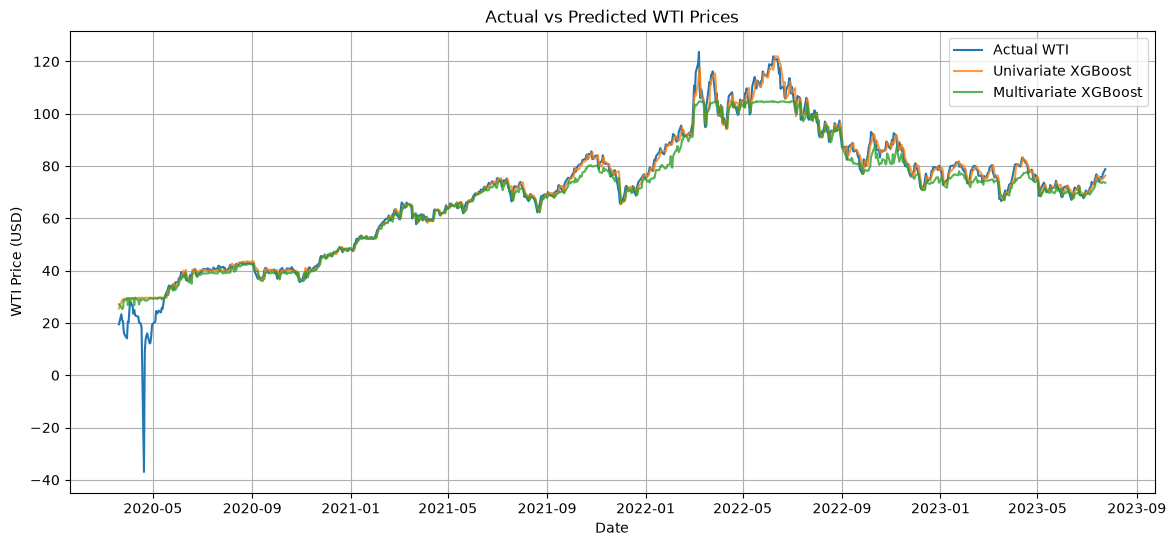

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    data_uni_model["Date"].iloc[split_uni:],
    y_test_uni.values,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    data_uni_model["Date"].iloc[split_uni:],
    y_pred_uni,
    label="Univariate XGBoost",
    alpha=0.8
)

plt.plot(
    data_multi_model["Date"].iloc[split_multi:],
    y_pred_multi,
    label="Multivariate XGBoost",
    alpha=0.8
)

plt.title("Actual vs Predicted WTI Prices")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Tính mức thay đổi giá thực tế
actual_change = (
    np.asarray(y_test_uni)
    - np.asarray(X_test_uni["WTI_Lag1"])
)

# Tính mức thay đổi giá dự báo
uni_change = (
    y_pred_uni
    - np.asarray(X_test_uni["WTI_Lag1"])
)

multi_change = (
    y_pred_multi
    - np.asarray(X_test_multi["wti_Lag1"])
)

# Tạo bảng so sánh
comparison = pd.DataFrame({
    "Actual Change": actual_change,
    "Uni Predicted Change": uni_change,
    "Multi Predicted Change": multi_change
})

display(comparison.head(15).round(3))

,Actual Change,Uni Predicted Change,Multi Predicted Change
0,-5.61,0.436,2.064
1,3.85,8.446,6.390
2,-2.30,5.226,2.005
3,-0.28,7.880,4.531
4,-4.15,8.438,8.109
5,-1.12,12.624,11.882
6,-1.38,13.804,13.986
7,6.41,15.142,12.728
8,-0.23,8.774,9.044
9,4.90,9.040,7.277


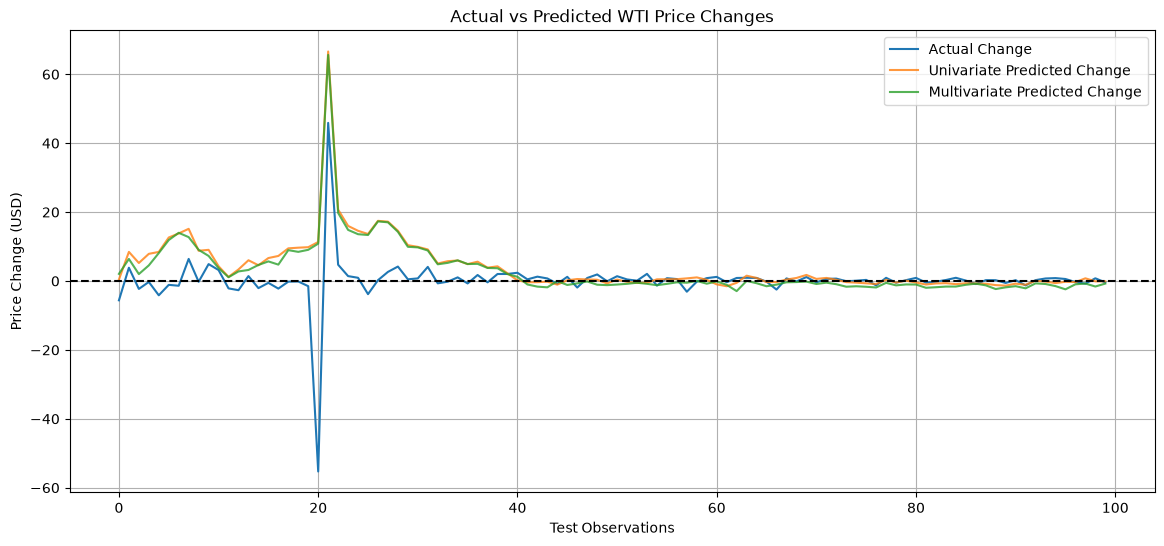

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_change[:100],
    label="Actual Change",
    linewidth=1.5
)

plt.plot(
    uni_change[:100],
    label="Univariate Predicted Change",
    alpha=0.8
)

plt.plot(
    multi_change[:100],
    label="Multivariate Predicted Change",
    alpha=0.8
)

plt.axhline(y=0, linestyle="--", color="black")

plt.title("Actual vs Predicted WTI Price Changes")
plt.xlabel("Test Observations")
plt.ylabel("Price Change (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# Tạo mục tiêu là mức thay đổi giá WTI
data_uni_model["WTI_Change"] = (
    data_uni_model["wti"] -
    data_uni_model["WTI_Lag1"]
)

data_multi_model["WTI_Change"] = (
    data_multi_model["wti"] -
    data_multi_model["wti_Lag1"]
)

# Kiểm tra
display(
    data_uni_model[
        ["Date", "wti", "WTI_Lag1", "WTI_Change"]
    ].head(10)
)

,Date,wti,WTI_Lag1,WTI_Change
0,2006-11-13,58.59,59.66,-1.07
1,2006-11-14,58.28,58.59,-0.31
2,2006-11-15,58.79,58.28,0.51
3,2006-11-16,56.23,58.79,-2.56
4,2006-11-17,55.90,56.23,-0.33
5,2006-11-20,56.42,55.90,0.52
6,2006-11-21,58.01,56.42,1.59
7,2006-11-22,57.28,58.01,-0.73
8,2006-11-27,60.30,57.28,3.02
9,2006-11-28,60.97,60.30,0.67


In [24]:
# Biến mục tiêu mới
y_change_uni = data_uni_model["WTI_Change"]
y_change_multi = data_multi_model["WTI_Change"]

# Chia Univariate
y_train_change_uni = y_change_uni.iloc[:split_uni]
y_test_change_uni = y_change_uni.iloc[split_uni:]

# Chia Multivariate
y_train_change_multi = y_change_multi.iloc[:split_multi]
y_test_change_multi = y_change_multi.iloc[split_multi:]

print("Univariate:", y_train_change_uni.shape,
      y_test_change_uni.shape)

print("Multivariate:", y_train_change_multi.shape,
      y_test_change_multi.shape)

Univariate: (3356,) (839,)
Multivariate: (1634,) (839,)


In [25]:
# Khởi tạo mô hình
model_change_uni = XGBRegressor(**xgb_params)
model_change_multi = XGBRegressor(**xgb_params)

# Huấn luyện Univariate
model_change_uni.fit(
    X_train_uni,
    y_train_change_uni
)

# Huấn luyện Multivariate
model_change_multi.fit(
    X_train_multi,
    y_train_change_multi
)

print("Đã huấn luyện xong hai mô hình dự báo mức thay đổi!")

Đã huấn luyện xong hai mô hình dự báo mức thay đổi!


In [26]:
# Dự báo mức thay đổi
pred_change_uni = model_change_uni.predict(X_test_uni)

pred_change_multi = model_change_multi.predict(X_test_multi)

# Lấy giá WTI của phiên trước
previous_price = X_test_uni["WTI_Lag1"].values

# Khôi phục giá WTI dự báo
pred_price_change_uni = previous_price + pred_change_uni

pred_price_change_multi = previous_price + pred_change_multi

print("5 mức thay đổi dự báo Univariate:")
print(pred_change_uni[:5])

print("\n5 mức thay đổi dự báo Multivariate:")
print(pred_change_multi[:5])

print("\n5 giá WTI dự báo Univariate:")
print(pred_price_change_uni[:5])

print("\n5 giá WTI dự báo Multivariate:")
print(pred_price_change_multi[:5])

5 mức thay đổi dự báo Univariate:
[1.1791618  0.39018205 0.7814448  0.5430044  0.63247204]

5 mức thay đổi dự báo Multivariate:
[2.3330708 1.4869547 1.2992542 2.3001955 1.6613878]

5 giá WTI dự báo Univariate:
[26.26916179 19.87018205 24.11144479 21.57300439 21.38247204]

5 giá WTI dự báo Multivariate:
[27.42307076 20.96695469 24.62925418 23.33019546 22.4113878 ]


In [27]:
# Đánh giá Univariate Change Model
results_change_uni = evaluate_model(
    y_test_uni,
    pred_price_change_uni,
    X_test_uni["WTI_Lag1"]
)

# Đánh giá Multivariate Change Model
results_change_multi = evaluate_model(
    y_test_multi,
    pred_price_change_multi,
    X_test_multi["wti_Lag1"]
)

# Tạo bảng kết quả
results_e3 = pd.DataFrame(
    [results_change_uni, results_change_multi],
    index=[
        "Univariate Change",
        "Multivariate Change"
    ]
)

display(results_e3.round(4))

,MAE,RMSE,R2,DA (%)
Univariate Change,1.5856,3.2267,0.9811,48.8677
Multivariate Change,1.8042,3.3839,0.9792,45.4112


In [28]:
all_results = pd.DataFrame(
    [
        results_uni,
        results_multi,
        results_change_uni,
        results_change_multi
    ],
    index=[
        "E1 - Univariate XGBoost",
        "E2 - Multivariate XGBoost",
        "E3 - Univariate Change",
        "E3 - Multivariate Change"
    ]
)

display(all_results.round(4))

,MAE,RMSE,R2,DA (%)
E1 - Univariate XGBoost,1.9356,3.7773,0.9741,50.4172
E2 - Multivariate XGBoost,3.0037,4.8294,0.9577,46.7223
E3 - Univariate Change,1.5856,3.2267,0.9811,48.8677
E3 - Multivariate Change,1.8042,3.3839,0.9792,45.4112


In [29]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [30]:
# Lấy tối đa 500 quan sát từ tập Test
X_shap = X_test_multi.sample(
    n=min(500, len(X_test_multi)),
    random_state=42
)

# Tạo SHAP Explainer
explainer = shap.TreeExplainer(model_change_multi)

# Tính SHAP values
shap_values = explainer(X_shap)

print("Đã tính SHAP values!")
print("Kích thước:", shap_values.values.shape)

Đã tính SHAP values!
Kích thước: (500, 35)


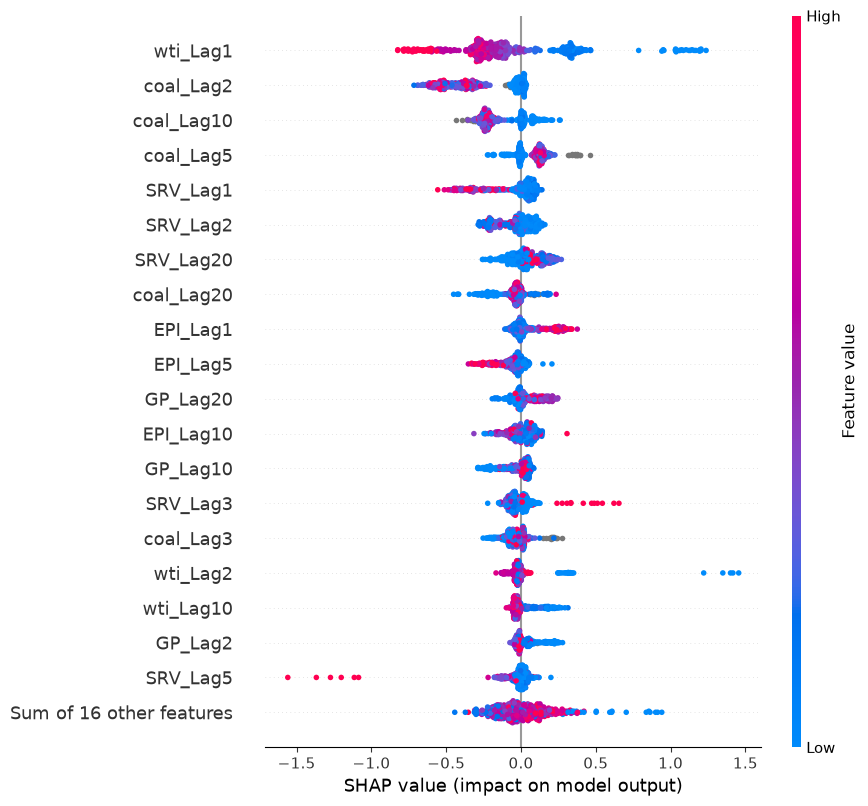

In [31]:
shap.plots.beeswarm(
    shap_values,
    max_display=20
)

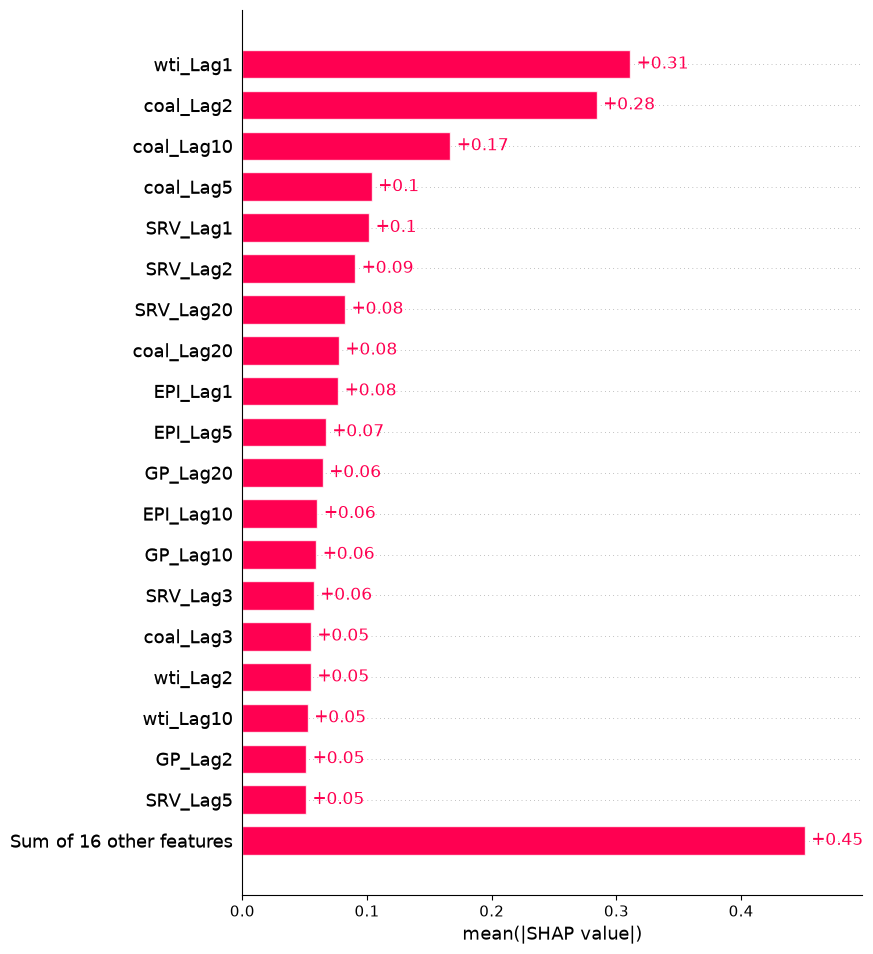

In [32]:
shap.plots.bar(
    shap_values,
    max_display=20
)

In [33]:
# Tạo bảng SHAP Importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Importance": np.abs(shap_values.values).mean(axis=0)
})

# Xác định nhóm biến
def get_feature_group(feature):
    return feature.split("_Lag")[0]

shap_importance["Group"] = (
    shap_importance["Feature"].apply(get_feature_group)
)

# Cộng importance của các Lag thuộc cùng nhóm
group_importance = (
    shap_importance.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("SHAP Importance theo nhóm biến:")
display(group_importance.to_frame())

SHAP Importance theo nhóm biến:


,Importance
Group,
coal,0.714585
wti,0.519876
SRV,0.421231
EPI,0.307287
GP,0.262787
TB,0.091013


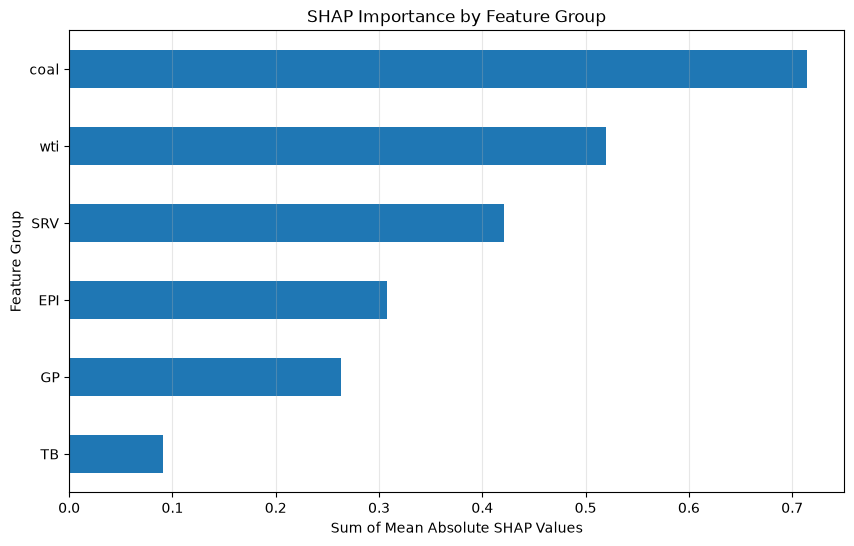

In [34]:
plt.figure(figsize=(10, 6))

group_importance.sort_values().plot(
    kind="barh"
)

plt.title("SHAP Importance by Feature Group")
plt.xlabel("Sum of Mean Absolute SHAP Values")
plt.ylabel("Feature Group")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [35]:
# Lấy danh sách biến không thuộc nhóm coal
features_no_coal = [
    col for col in features_multi
    if not col.startswith("coal_Lag")
]

print("Số biến ban đầu:", len(features_multi))
print("Số biến sau khi bỏ Coal:", len(features_no_coal))

print("\nCác biến còn lại:")
print(features_no_coal)

Số biến ban đầu: 35
Số biến sau khi bỏ Coal: 29

Các biến còn lại:
['wti_Lag1', 'wti_Lag2', 'wti_Lag3', 'wti_Lag5', 'wti_Lag10', 'wti_Lag20', 'GP_Lag1', 'GP_Lag2', 'GP_Lag3', 'GP_Lag5', 'GP_Lag10', 'GP_Lag20', 'TB_Lag2', 'TB_Lag3', 'TB_Lag5', 'TB_Lag10', 'TB_Lag20', 'EPI_Lag1', 'EPI_Lag2', 'EPI_Lag3', 'EPI_Lag5', 'EPI_Lag10', 'EPI_Lag20', 'SRV_Lag1', 'SRV_Lag2', 'SRV_Lag3', 'SRV_Lag5', 'SRV_Lag10', 'SRV_Lag20']


In [36]:
# Chỉ lấy 30 biến còn lại
X_train_no_coal = X_train_multi[features_no_coal]
X_test_no_coal = X_test_multi[features_no_coal]

print("Train:", X_train_no_coal.shape)
print("Test:", X_test_no_coal.shape)

Train: (1634, 29)
Test: (839, 29)


In [37]:
# Khởi tạo mô hình
model_no_coal = XGBRegressor(**xgb_params)

# Huấn luyện bằng mục tiêu WTI_Change
model_no_coal.fit(
    X_train_no_coal,
    y_train_change_multi
)

print("Đã huấn luyện xong E4!")

Đã huấn luyện xong E4!


In [38]:
# Dự báo mức thay đổi giá
pred_change_no_coal = model_no_coal.predict(
    X_test_no_coal
)

# Lấy giá WTI phiên trước
previous_price = X_test_multi["wti_Lag1"].values

# Khôi phục giá WTI
pred_price_no_coal = (
    previous_price + pred_change_no_coal
)

print("5 mức thay đổi dự báo:")
print(pred_change_no_coal[:5])

print("\n5 giá WTI dự báo:")
print(pred_price_no_coal[:5])

5 mức thay đổi dự báo:
[2.285114  1.2401975 1.4513232 2.8791263 1.8038595]

5 giá WTI dự báo:
[27.37511405 20.72019754 24.78132315 23.90912631 22.55385947]


In [39]:
results_no_coal = evaluate_model(
    y_test_multi,
    pred_price_no_coal,
    X_test_multi["wti_Lag1"]
)

display(
    pd.DataFrame(
        [results_no_coal],
        index=["E4 - Without Coal"]
    ).round(4)
)

,MAE,RMSE,R2,DA (%)
E4 - Without Coal,1.6931,3.3082,0.9801,46.8415


In [40]:
# Chọn 500 quan sát trong tập Test
X_shap_no_coal = X_test_no_coal.sample(
    n=min(500, len(X_test_no_coal)),
    random_state=42
)

# Tạo SHAP Explainer
explainer_no_coal = shap.TreeExplainer(model_no_coal)

# Tính SHAP values
shap_values_no_coal = explainer_no_coal(X_shap_no_coal)

print("SHAP shape:", shap_values_no_coal.values.shape)

SHAP shape: (500, 29)


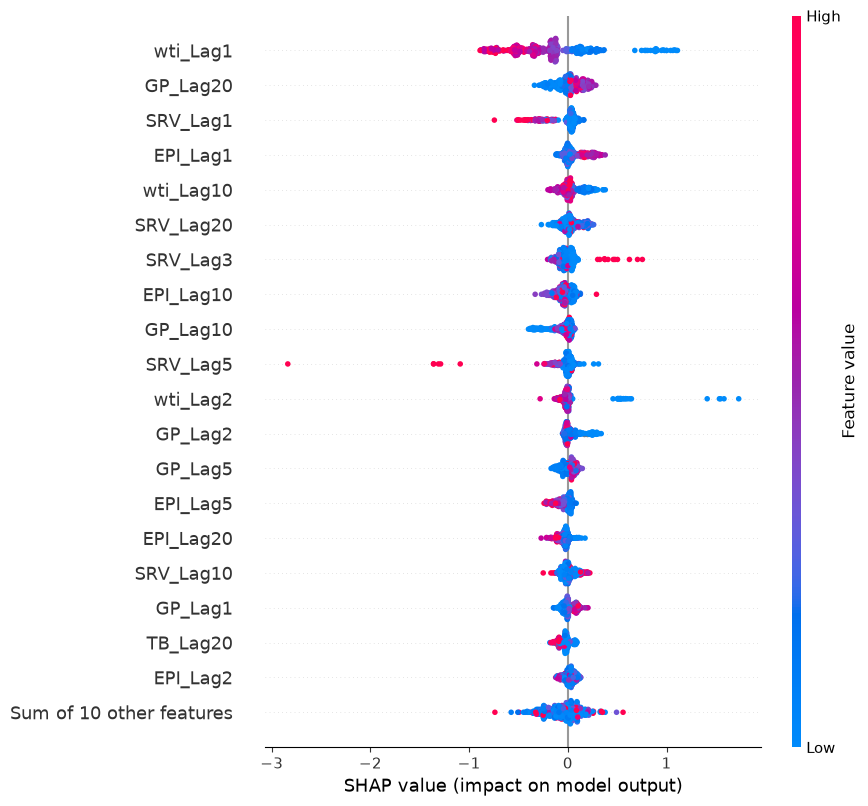

In [41]:
shap.plots.beeswarm(
    shap_values_no_coal,
    max_display=20
)

In [42]:
shap_importance_no_coal = pd.DataFrame({
    "Feature": X_shap_no_coal.columns,
    "Importance": np.abs(
        shap_values_no_coal.values
    ).mean(axis=0)
})

shap_importance_no_coal["Group"] = (
    shap_importance_no_coal["Feature"]
    .apply(lambda x: x.split("_Lag")[0])
)

group_importance_no_coal = (
    shap_importance_no_coal
    .groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

display(group_importance_no_coal.to_frame())

,Importance
Group,
wti,0.578559
SRV,0.376711
GP,0.341763
EPI,0.323895
TB,0.140926


In [43]:
# Các nhóm biến cần thử loại bỏ
groups_to_remove = ["GP", "EPI", "SRV", "TB"]

for group in groups_to_remove:
    remaining_features = [
        col for col in features_no_coal
        if not col.startswith(group + "_Lag")
    ]

    print(
        f"Bỏ {group}: còn {len(remaining_features)} biến"
    )

Bỏ GP: còn 23 biến
Bỏ EPI: còn 23 biến
Bỏ SRV: còn 23 biến
Bỏ TB: còn 24 biến


In [44]:
# Các nhóm biến cần loại bỏ
groups_to_remove = ["GP", "EPI", "SRV", "TB"]

# Lưu kết quả
ablation_results = []

# Lưu mô hình và dự báo
ablation_models = {}

for group in groups_to_remove:

    print(f"\nĐang thực hiện: Remove {group}")

    # Lấy các biến còn lại
    remaining_features = [
        col for col in features_no_coal
        if not col.startswith(group + "_Lag")
    ]

    # Tạo Train và Test
    X_train_abl = X_train_multi[remaining_features]
    X_test_abl = X_test_multi[remaining_features]

    # Khởi tạo và huấn luyện
    model_abl = XGBRegressor(**xgb_params)

    model_abl.fit(
        X_train_abl,
        y_train_change_multi
    )

    # Dự báo mức thay đổi
    pred_change = model_abl.predict(X_test_abl)

    # Khôi phục giá WTI
    previous_price = X_test_multi["wti_Lag1"].values
    pred_price = previous_price + pred_change

    # Đánh giá
    result = evaluate_model(
        y_test_multi,
        pred_price,
        previous_price
    )

    # Lưu kết quả
    ablation_results.append({
        "Experiment": f"Without {group}",
        "Features": len(remaining_features),
        **result
    })

    ablation_models[group] = {
        "model": model_abl,
        "features": remaining_features,
        "prediction": pred_price
    }

    print("Hoàn thành:", group)

print("\nĐã hoàn thành 4 thí nghiệm!")


Đang thực hiện: Remove GP
Hoàn thành: GP

Đang thực hiện: Remove EPI
Hoàn thành: EPI

Đang thực hiện: Remove SRV
Hoàn thành: SRV

Đang thực hiện: Remove TB
Hoàn thành: TB

Đã hoàn thành 4 thí nghiệm!


In [45]:
# Kết quả E4 đã có
baseline_no_coal = {
    "Experiment": "E4 - Without Coal",
    "Features": len(features_no_coal),
    **results_no_coal
}

# Tổng hợp kết quả
all_ablation_results = pd.DataFrame(
    [baseline_no_coal] + ablation_results
)

display(
    all_ablation_results.round(4)
)

,Experiment,Features,MAE,RMSE,R2,DA (%)
0,E4 - Without Coal,29,1.6931,3.3082,0.9801,46.8415
1,Without GP,23,1.7021,3.3197,0.9800,44.6961
2,Without EPI,23,1.7321,3.3595,0.9795,47.7950
3,Without SRV,23,1.8662,3.3941,0.9791,45.7688
4,Without TB,24,1.6737,3.3015,0.9802,47.6758


In [46]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=10, test_size=100)

print("Số Fold:", tscv.get_n_splits())

Số Fold: 10


In [47]:
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_multi), start=1
):
    print(f"\nFold {fold}")
    print("Train:", len(train_idx))
    print("Validation:", len(val_idx))

    print(
        "Train dates:",
        data_multi_model["Date"].iloc[train_idx[0]],
        "->",
        data_multi_model["Date"].iloc[train_idx[-1]]
    )

    print(
        "Validation dates:",
        data_multi_model["Date"].iloc[val_idx[0]],
        "->",
        data_multi_model["Date"].iloc[val_idx[-1]]
    )


Fold 1
Train: 634
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2016-03-22 00:00:00
Validation dates: 2016-03-23 00:00:00 -> 2016-08-12 00:00:00

Fold 2
Train: 734
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2016-08-12 00:00:00
Validation dates: 2016-08-15 00:00:00 -> 2017-01-05 00:00:00

Fold 3
Train: 834
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2017-01-05 00:00:00
Validation dates: 2017-01-06 00:00:00 -> 2017-05-31 00:00:00

Fold 4
Train: 934
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2017-05-31 00:00:00
Validation dates: 2017-06-01 00:00:00 -> 2017-10-23 00:00:00

Fold 5
Train: 1034
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2017-10-23 00:00:00
Validation dates: 2017-10-24 00:00:00 -> 2018-03-19 00:00:00

Fold 6
Train: 1134
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2018-03-19 00:00:00
Validation dates: 2018-03-20 00:00:00 -> 2018-08-09 00:00:00

Fold 7
Train: 1234
Validation: 100
Train dates: 2013-09-16 00:00:00 -> 2018-08-09 00:

In [48]:

# Hai bộ biến cần so sánh
features_e4 = features_no_coal

features_e5 = [
    col for col in features_no_coal
    if not col.startswith("GP_Lag")
]

# Chuẩn bị dữ liệu Train
y_train_change = (
    data_multi_model["WTI_Change"]
    .iloc[:split_multi]
)

# Giá WTI thực tế và giá phiên trước trong tập Train
actual_price_train = y_train_multi

previous_price_train = (
    data_multi_model["wti_Lag1"]
    .iloc[:split_multi]
)

# Kiểm tra số dòng có khớp không
assert len(X_train_multi) == len(y_train_change)
assert len(X_train_multi) == len(actual_price_train)
assert len(X_train_multi) == len(previous_price_train)

# Lưu kết quả từng Fold
cv_results = []

# TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=10, test_size=100)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_multi), start=1
):

    print(f"\nĐang chạy Fold {fold}...")

    # Chia dữ liệu theo Fold
    y_train_fold = y_train_change.iloc[train_idx]

    # Giá WTI thực tế và giá phiên trước
    actual_price = actual_price_train.iloc[val_idx].values

    previous_price = (
        previous_price_train.iloc[val_idx].values
    )

    # Hai mô hình
    models = {
        "E4 - Without Coal": features_e4,
        "E5 - Without Coal and GP": features_e5
    }

    for model_name, selected_features in models.items():

        # Lấy dữ liệu đầu vào theo Fold
        X_train_fold = (
            X_train_multi.iloc[train_idx][selected_features]
        )

        X_val_fold = (
            X_train_multi.iloc[val_idx][selected_features]
        )

        # Huấn luyện
        model = XGBRegressor(**xgb_params)

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # Dự báo mức thay đổi
        pred_change = model.predict(X_val_fold)

        # Khôi phục giá WTI
        pred_price = previous_price + pred_change

        # Đánh giá
        metrics = evaluate_model(
            actual_price,
            pred_price,
            previous_price
        )

        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            "Features": len(selected_features),
            **metrics
        })

    print(f"Hoàn thành Fold {fold}!")

print("\nĐã hoàn thành Cross Validation!")

cv_results_df = pd.DataFrame(cv_results)



Đang chạy Fold 1...
Hoàn thành Fold 1!

Đang chạy Fold 2...
Hoàn thành Fold 2!

Đang chạy Fold 3...
Hoàn thành Fold 3!

Đang chạy Fold 4...
Hoàn thành Fold 4!

Đang chạy Fold 5...
Hoàn thành Fold 5!

Đang chạy Fold 6...
Hoàn thành Fold 6!

Đang chạy Fold 7...
Hoàn thành Fold 7!

Đang chạy Fold 8...
Hoàn thành Fold 8!

Đang chạy Fold 9...
Hoàn thành Fold 9!

Đang chạy Fold 10...
Hoàn thành Fold 10!

Đã hoàn thành Cross Validation!


In [49]:
print(cv_results_df.columns.tolist())

['Fold', 'Model', 'Features', 'MAE', 'RMSE', 'R2', 'DA (%)']


In [50]:
display(cv_results_df.head())

,Fold,Model,Features,MAE,RMSE,R2,DA (%)
0,1,E4 - Without Coal,29,0.982044,1.252673,0.902459,48.0
1,1,E5 - Without Coal and GP,23,1.013247,1.291382,0.896338,48.0
2,2,E4 - Without Coal,29,0.897896,1.135301,0.859738,47.0
3,2,E5 - Without Coal and GP,23,0.856834,1.086418,0.871556,49.0
4,3,E4 - Without Coal,29,0.648899,0.877690,0.867337,45.0


In [51]:
cv_results_df = pd.DataFrame(cv_results)

cv_summary = cv_results_df.groupby("Model")[
    ["MAE", "RMSE", "R2", "DA (%)"]
].mean()

display(cv_summary)

,MAE,RMSE,R2,DA (%)
Model,,,,
E4 - Without Coal,0.920085,1.264046,0.860519,47.6
E5 - Without Coal and GP,0.929614,1.265512,0.860696,48.4


In [52]:

# Tổng hợp kết quả Cross Validation
cv_summary = cv_results_df.groupby("Model").agg({
    "MAE": ["mean", "std"],
    "RMSE": ["mean", "std"],
    "R2": ["mean", "std"],
    "DA (%)": ["mean", "std"]
})

# Làm tròn 4 chữ số
cv_summary = cv_summary.round(4)

display(cv_summary)


MAE            RMSE              R2          \
                            mean     std    mean     std    mean     std   
Model                                                                      
E4 - Without Coal         0.9201  0.1832  1.2640  0.3723  0.8605  0.1267   
E5 - Without Coal and GP  0.9296  0.1850  1.2655  0.3634  0.8607  0.1271   

                         DA (%)          
                           mean     std  
Model                                    
E4 - Without Coal          47.6  2.8363  
E5 - Without Coal and GP   48.4  3.7476

In [53]:

# Huấn luyện và đánh giá E4, E5 trên tập Test

test_results = []

models_features = {
    "E4 - Without Coal": features_e4,
    "E5 - Without Coal and GP": features_e5
}

# Giá WTI thực tế và giá phiên trước trên tập Test
actual_price_test = y_test_multi.values

previous_price_test = (
    data_multi_model["wti_Lag1"]
    .iloc[split_multi:]
    .values
)

for model_name, selected_features in models_features.items():

    # Lấy Features
    X_train_selected = X_train_multi[selected_features]
    X_test_selected = X_test_multi[selected_features]

    # Tạo và huấn luyện mô hình
    model = XGBRegressor(**xgb_params)

    model.fit(
        X_train_selected,
        y_train_change_multi
    )

    # Dự báo mức thay đổi
    pred_change = model.predict(X_test_selected)

    # Khôi phục giá WTI
    pred_price = previous_price_test + pred_change

    # Đánh giá
    metrics = evaluate_model(
        actual_price_test,
        pred_price,
        previous_price_test
    )

    test_results.append({
        "Model": model_name,
        **metrics
    })

# Hiển thị kết quả
test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))


,Model,MAE,RMSE,R2,DA (%)
0,E4 - Without Coal,1.6931,3.3082,0.9801,46.8415
1,E5 - Without Coal and GP,1.7021,3.3197,0.9800,44.6961


In [54]:
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"],
        "DA (%)": ["mean", "std"]
    })
)

display(cv_summary.round(4))

MAE            RMSE              R2          \
                            mean     std    mean     std    mean     std   
Model                                                                      
E4 - Without Coal         0.9201  0.1832  1.2640  0.3723  0.8605  0.1267   
E5 - Without Coal and GP  0.9296  0.1850  1.2655  0.3634  0.8607  0.1271   

                         DA (%)          
                           mean     std  
Model                                    
E4 - Without Coal          47.6  2.8363  
E5 - Without Coal and GP   48.4  3.7476

In [55]:
param_grid = {
    "n_estimators": [300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

In [56]:
from sklearn.model_selection import RandomizedSearchCV

xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(
    X_train_multi[features_e5],
    y_train_change_multi
)

print("Best parameters:")
print(random_search.best_params_)

print("Best CV MAE:", -random_search.best_score_)

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best parameters:
{'subsample': 1.0, 'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV MAE: 0.8594162148323621


In [57]:
best_params = random_search.best_params_

best_model_e5 = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

best_model_e5.fit(
    X_train_multi[features_e5],
    y_train_change_multi
)

print("Đã huấn luyện xong mô hình E5 tối ưu!")

Đã huấn luyện xong mô hình E5 tối ưu!


In [58]:
# Dự đoán mức thay đổi giá WTI
y_pred_change = best_model_e5.predict(
    X_test_multi[features_e5]
)

# Khôi phục giá WTI dự đoán
previous_price = data_multi_model["wti_Lag1"].iloc[len(X_train_multi):].values

y_pred_price = previous_price + y_pred_change

# Đánh giá mô hình
results_best_e5 = evaluate_model(
    y_test_change_multi + previous_price,
    y_pred_price,
    previous_price
)

print("Kết quả E5 sau tối ưu:")
print(results_best_e5)

Kết quả E5 sau tối ưu:
{'MAE': 1.5927475503188944, 'RMSE': np.float64(3.256628779300078), 'R2': 0.9807597161847933, 'DA (%)': np.float64(46.841477949940405)}


In [59]:
# ==========================================
# SPLIT CONFORMAL PREDICTION - 90%
# ==========================================

from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

# 1. Chuẩn bị dữ liệu E5
X_train_cp_all = X_train_multi[features_e5].copy()
y_train_cp_all = y_train_change_multi.copy()

X_test_cp = X_test_multi[features_e5].copy()

# 2. Chia Train thành Proper Train và Calibration
cp_split = int(len(X_train_cp_all) * 0.8)

X_proper = X_train_cp_all.iloc[:cp_split].copy()
y_proper = y_train_cp_all.iloc[:cp_split].copy()

X_cal = X_train_cp_all.iloc[cp_split:].copy()
y_cal = y_train_cp_all.iloc[cp_split:].copy()

print("Proper Train:", len(X_proper))
print("Calibration:", len(X_cal))
print("Test:", len(X_test_cp))

print("\nProper Train period:")
print(
    data_multi_model.loc[X_proper.index, "Date"].min(),
    "->",
    data_multi_model.loc[X_proper.index, "Date"].max()
)

print("\nCalibration period:")
print(
    data_multi_model.loc[X_cal.index, "Date"].min(),
    "->",
    data_multi_model.loc[X_cal.index, "Date"].max()
)

# 3. Tối ưu mô hình chỉ trên Proper Train
tscv_cp = TimeSeriesSplit(
    n_splits=10,
    test_size=60
)

xgb_cp = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

search_cp = RandomizedSearchCV(
    estimator=xgb_cp,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv_cp,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_cp.fit(X_proper, y_proper)

print("\nBest CP parameters:")
print(search_cp.best_params_)

print("Best CP CV MAE:", -search_cp.best_score_)

# 4. Huấn luyện mô hình cuối trên Proper Train
cp_model = XGBRegressor(
    **search_cp.best_params_,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

cp_model.fit(X_proper, y_proper)

# 5. Tính sai số trên Calibration
cal_predictions = cp_model.predict(X_cal)

cal_scores = np.abs(
    y_cal.to_numpy() - cal_predictions
)

# 6. Tính quantile cho mức tin cậy 90%
alpha = 0.10

n_cal = len(cal_scores)

quantile_level = min(
    1.0,
    np.ceil((n_cal + 1) * (1 - alpha)) / n_cal
)

q_hat = np.quantile(
    cal_scores,
    quantile_level,
    method="higher"
)

print("\n===== CONFORMAL CALIBRATION =====")
print("Calibration observations:", n_cal)
print("Confidence level:", 1 - alpha)
print("Quantile level:", quantile_level)
print("Conformal quantile:", q_hat)

Proper Train: 1307
Calibration: 327
Test: 839

Proper Train period:
2013-09-16 00:00:00 -> 2018-11-21 00:00:00

Calibration period:
2018-11-26 00:00:00 -> 2020-03-19 00:00:00
Fitting 10 folds for each of 20 candidates, totalling 200 fits

Best CP parameters:
{'subsample': 1.0, 'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CP CV MAE: 0.7751312045690953

===== CONFORMAL CALIBRATION =====
Calibration observations: 327
Confidence level: 0.9
Quantile level: 0.9051987767584098
Conformal quantile: 2.1905932378768966


In [60]:
# ==========================================
# ĐÁNH GIÁ SPLIT CONFORMAL PREDICTION
# ==========================================

# 1. Dự báo WTI Change trên Test
pred_change_cp = cp_model.predict(X_test_cp)

actual_change_cp = (
    y_test_change_multi.loc[X_test_cp.index].to_numpy()
)

# 2. Lấy giá WTI phiên trước
previous_price_cp = (
    X_test_cp["wti_Lag1"].to_numpy()
)

# 3. Khôi phục giá WTI dự báo
pred_price_cp = (
    previous_price_cp + pred_change_cp
)

actual_price_cp = (
    y_test_multi.loc[X_test_cp.index].to_numpy()
)

# 4. Xây dựng khoảng dự báo
lower_bound_cp = pred_price_cp - q_hat
upper_bound_cp = pred_price_cp + q_hat

# 5. Coverage
covered = (
    (actual_price_cp >= lower_bound_cp) &
    (actual_price_cp <= upper_bound_cp)
)

coverage = covered.mean()

# 6. Average Width
interval_width = (
    upper_bound_cp - lower_bound_cp
)

average_width = interval_width.mean()

# 7. Interval Score
interval_score = (
    interval_width
    + (2 / alpha)
    * (lower_bound_cp - actual_price_cp)
    * (actual_price_cp < lower_bound_cp)
    + (2 / alpha)
    * (actual_price_cp - upper_bound_cp)
    * (actual_price_cp > upper_bound_cp)
)

mean_interval_score = interval_score.mean()

# 8. Tổng hợp kết quả
cp_results = pd.DataFrame([{
    "Method": "Split Conformal",
    "Nominal Coverage (%)": (1 - alpha) * 100,
    "Actual Coverage (%)": coverage * 100,
    "Average Width": average_width,
    "Interval Score": mean_interval_score
}])

display(cp_results.round(4))

# 9. Lưu kết quả theo ngày
cp_predictions = pd.DataFrame({
    "Date": data_multi_model.loc[
        X_test_cp.index, "Date"
    ].values,
    "Actual": actual_price_cp,
    "Prediction": pred_price_cp,
    "Lower": lower_bound_cp,
    "Upper": upper_bound_cp,
    "Covered": covered
})

display(cp_predictions.head())

,Method,Nominal Coverage (%),Actual Coverage (%),Average Width,Interval Score
0,Split Conformal,90.0,76.4005,4.3812,13.2262


,Date,Actual,Prediction,Lower,Upper,Covered
0,2020-03-20,19.48,27.151649,24.961055,29.342242,False
1,2020-03-23,23.33,21.545984,19.355391,23.736578,True
2,2020-03-24,21.03,23.705476,21.514883,25.896069,False
3,2020-03-25,20.75,23.088736,20.898143,25.279330,False
4,2020-03-26,16.60,21.225238,19.034645,23.415831,False


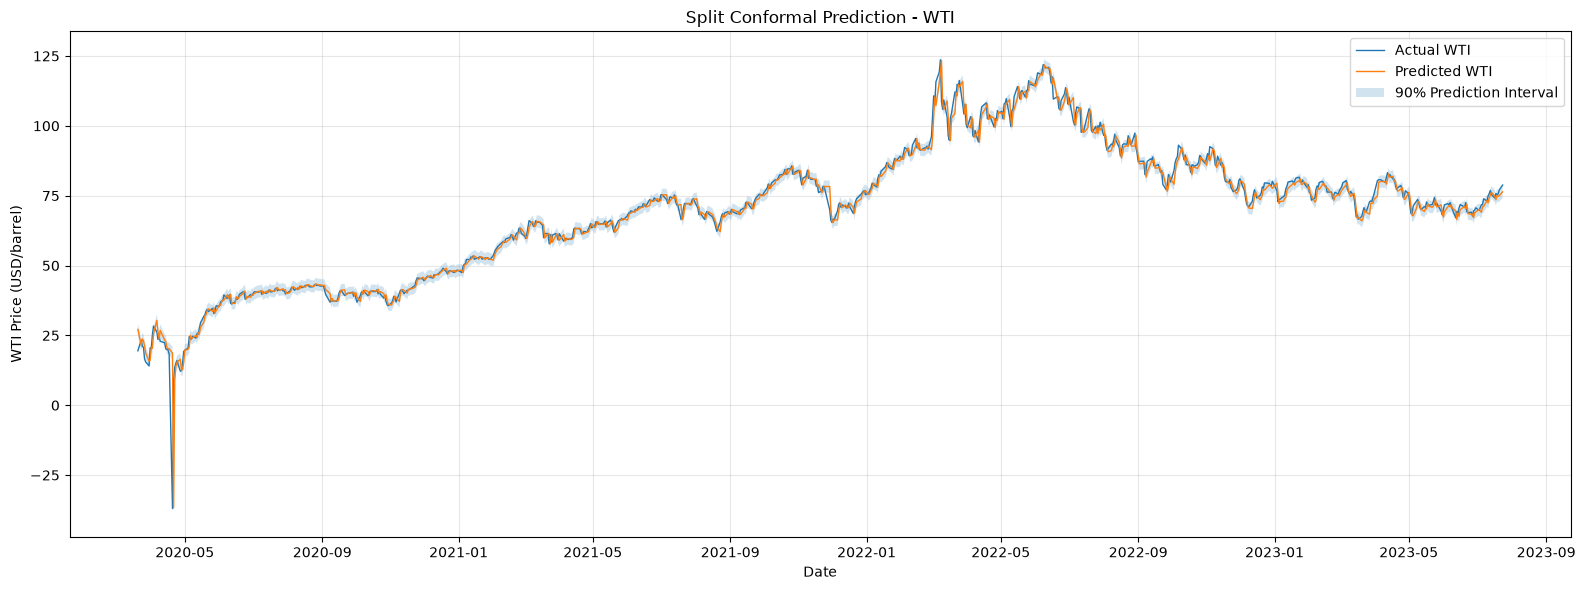

In [61]:
# ==========================================
# VISUALIZE CONFORMAL PREDICTION INTERVAL
# ==========================================

plt.figure(figsize=(16, 6))

plt.plot(
    cp_predictions["Date"],
    cp_predictions["Actual"],
    label="Actual WTI",
    linewidth=1
)

plt.plot(
    cp_predictions["Date"],
    cp_predictions["Prediction"],
    label="Predicted WTI",
    linewidth=1
)

plt.fill_between(
    cp_predictions["Date"],
    cp_predictions["Lower"],
    cp_predictions["Upper"],
    alpha=0.2,
    label="90% Prediction Interval"
)

plt.title("Split Conformal Prediction - WTI")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
# ==========================================
# ROLLING CONFORMAL PREDICTION - 90%
# ==========================================

# 1. Cấu hình
window_size = 126
alpha = 0.10

# 2. Khởi tạo bằng 126 sai số cuối Calibration
rolling_scores = list(
    np.asarray(cal_scores)[-window_size:]
)

# 3. Lấy ngày Test
test_dates = data_multi_model.loc[
    X_test_cp.index, "Date"
].reset_index(drop=True)

rolling_records = []

# 4. Dự báo tuần tự trên Test
for i in range(len(X_test_cp)):

    # Sắp xếp sai số đã quan sát
    scores_sorted = np.sort(
        np.asarray(rolling_scores)
    )

    n_window = len(scores_sorted)

    # Quantile hiệu chỉnh theo số lượng mẫu hữu hạn
    rank = min(
        n_window,
        int(np.ceil((n_window + 1) * (1 - alpha)))
    )

    q_t = scores_sorted[rank - 1]

    # Dự báo mức thay đổi giá
    pred_change = pred_change_cp[i]

    # Khôi phục giá WTI
    pred_price = (
        previous_price_cp[i] + pred_change
    )

    actual_price = actual_price_cp[i]
    actual_change = actual_change_cp[i]

    # Khoảng dự báo
    lower = pred_price - q_t
    upper = pred_price + q_t

    # Kiểm tra Coverage
    covered = (
        lower <= actual_price <= upper
    )

    rolling_records.append({
        "Date": test_dates.iloc[i],
        "Actual": actual_price,
        "Prediction": pred_price,
        "Lower": lower,
        "Upper": upper,
        "Quantile": q_t,
        "Covered": covered,
        "Absolute_Error": abs(
            actual_change - pred_change
        )
    })

    # Chỉ cập nhật sau khi đã quan sát giá thực tế
    rolling_scores.append(
        abs(actual_change - pred_change)
    )

    # Giữ lại 126 sai số gần nhất
    rolling_scores = rolling_scores[-window_size:]


# 5. Chuyển thành DataFrame
rolling_predictions = pd.DataFrame(
    rolling_records
)

print("Rolling CP observations:",
      len(rolling_predictions))

display(rolling_predictions.head())

Rolling CP observations: 839


,Date,Actual,Prediction,Lower,Upper,Quantile,Covered,Absolute_Error
0,2020-03-20,19.48,27.151649,25.082090,29.221207,2.069558,False,7.671649
1,2020-03-23,23.33,21.545984,19.409876,23.682093,2.136108,True,1.784016
2,2020-03-24,21.03,23.705476,21.569368,25.841584,2.136108,False,2.675476
3,2020-03-25,20.75,23.088736,20.777909,25.399564,2.310827,False,2.338736
4,2020-03-26,16.60,21.225238,18.886502,23.563975,2.338736,False,4.625238


In [63]:
# ==========================================
# EVALUATION - ROLLING CONFORMAL
# ==========================================

actual = rolling_predictions["Actual"].to_numpy()
lower = rolling_predictions["Lower"].to_numpy()
upper = rolling_predictions["Upper"].to_numpy()

covered = (
    (actual >= lower) &
    (actual <= upper)
)

coverage = covered.mean() * 100

width = upper - lower
average_width = width.mean()

interval_score = (
    width
    + (2 / alpha) * (lower - actual) * (actual < lower)
    + (2 / alpha) * (actual - upper) * (actual > upper)
)

rolling_cp_results = pd.DataFrame([{
    "Method": "Rolling Conformal 126",
    "Nominal Coverage (%)": 90.0,
    "Actual Coverage (%)": coverage,
    "Average Width": average_width,
    "Interval Score": interval_score.mean()
}])

print("===== ROLLING CONFORMAL RESULTS =====")
display(rolling_cp_results.round(4))

# So sánh với Split Conformal
cp_comparison = pd.concat(
    [cp_results, rolling_cp_results],
    ignore_index=True
)

print("===== SPLIT VS ROLLING CONFORMAL =====")
display(cp_comparison.round(4))

===== ROLLING CONFORMAL RESULTS =====


,Method,Nominal Coverage (%),Actual Coverage (%),Average Width,Interval Score
0,Rolling Conformal 126,90.0,90.584,6.8762,11.8989


===== SPLIT VS ROLLING CONFORMAL =====


,Method,Nominal Coverage (%),Actual Coverage (%),Average Width,Interval Score
0,Split Conformal,90.0,76.4005,4.3812,13.2262
1,Rolling Conformal 126,90.0,90.5840,6.8762,11.8989


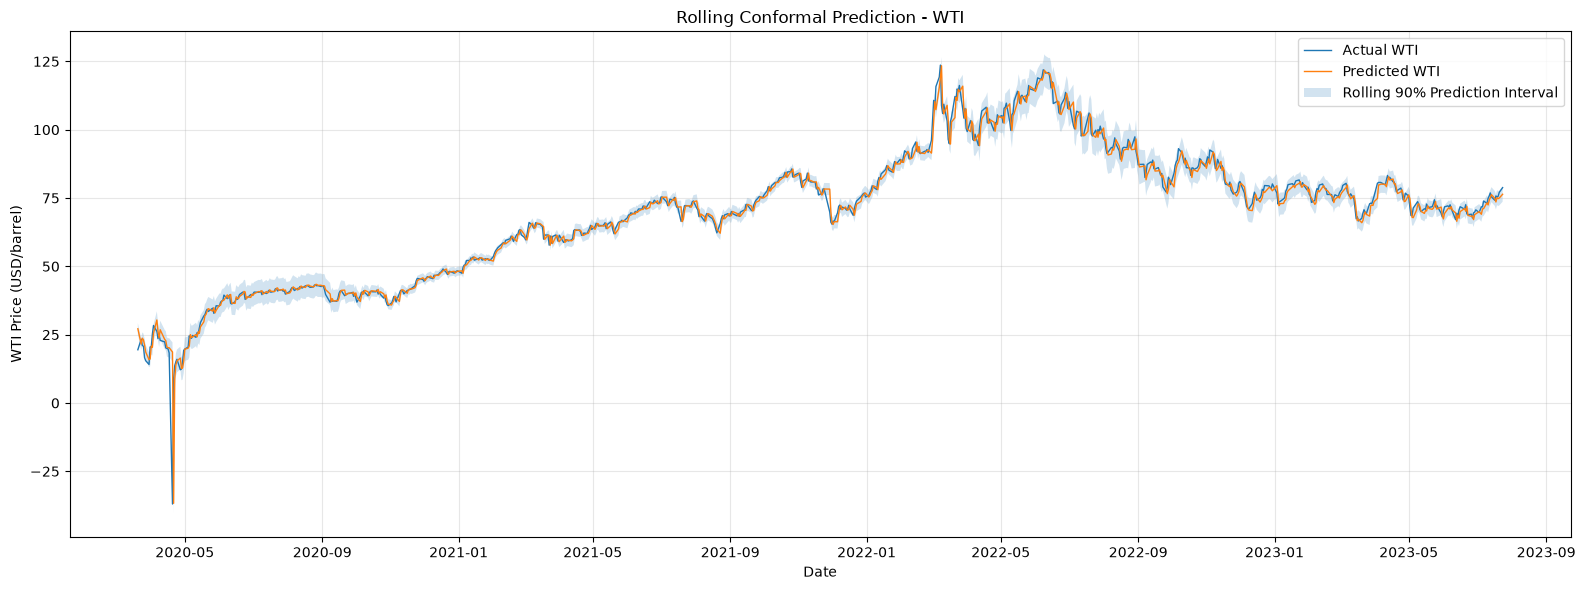

In [64]:
# ==========================================
# VISUALIZATION - ROLLING CONFORMAL
# ==========================================

plt.figure(figsize=(16, 6))

plt.plot(
    rolling_predictions["Date"],
    rolling_predictions["Actual"],
    label="Actual WTI",
    linewidth=1
)

plt.plot(
    rolling_predictions["Date"],
    rolling_predictions["Prediction"],
    label="Predicted WTI",
    linewidth=1
)

plt.fill_between(
    rolling_predictions["Date"],
    rolling_predictions["Lower"],
    rolling_predictions["Upper"],
    alpha=0.2,
    label="Rolling 90% Prediction Interval"
)

plt.title("Rolling Conformal Prediction - WTI")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# ==========================================
# VOLATILITY-ADAPTIVE CONFORMAL PREDICTION
# ==========================================

alpha = 0.10
vol_window = 20

# 1. Tính độ biến động WTI bằng độ lệch chuẩn
# Chỉ sử dụng 20 phiên trước ngày đang dự báo
volatility_series = (
    data_multi_model["WTI_Change"]
    .rolling(window=vol_window)
    .std()
    .shift(1)
)

# 2. Lấy độ biến động của Calibration và Test
sigma_cal = volatility_series.loc[
    X_cal.index
].to_numpy()

sigma_test = volatility_series.loc[
    X_test_cp.index
].to_numpy()

# Kiểm tra dữ liệu
assert np.isfinite(sigma_cal).all()
assert np.isfinite(sigma_test).all()
assert (sigma_cal > 0).all()
assert (sigma_test > 0).all()

# 3. Dự báo Calibration
cal_pred_vol = cp_model.predict(X_cal)

# 4. Tính sai số chuẩn hóa theo độ biến động
normalized_scores = (
    np.abs(y_cal.to_numpy() - cal_pred_vol)
    / sigma_cal
)

# 5. Tính quantile hữu hạn mẫu
sorted_scores = np.sort(normalized_scores)

n_cal_vol = len(sorted_scores)

rank_vol = min(
    n_cal_vol,
    int(np.ceil((n_cal_vol + 1) * (1 - alpha)))
)

q_vol = sorted_scores[rank_vol - 1]

print("===== VOLATILITY CALIBRATION =====")
print("Calibration observations:", n_cal_vol)
print("Volatility window:", vol_window)
print("Normalized quantile:", q_vol)

# 6. Dự báo mức thay đổi WTI trên Test
pred_change_vol = cp_model.predict(X_test_cp)

# 7. Khôi phục giá WTI
previous_price_vol = (
    X_test_cp["wti_Lag1"].to_numpy()
)

pred_price_vol = (
    previous_price_vol + pred_change_vol
)

actual_price_vol = (
    y_test_multi.loc[X_test_cp.index].to_numpy()
)

# 8. Tạo khoảng dự báo thích ứng
radius_vol = q_vol * sigma_test

lower_vol = pred_price_vol - radius_vol
upper_vol = pred_price_vol + radius_vol

# 9. Lưu kết quả
vol_adaptive_predictions = pd.DataFrame({
    "Date": data_multi_model.loc[
        X_test_cp.index, "Date"
    ].values,
    "Actual": actual_price_vol,
    "Prediction": pred_price_vol,
    "Lower": lower_vol,
    "Upper": upper_vol,
    "Volatility": sigma_test
})

vol_adaptive_predictions["Covered"] = (
    (vol_adaptive_predictions["Actual"] >= lower_vol)
    &
    (vol_adaptive_predictions["Actual"] <= upper_vol)
)

display(vol_adaptive_predictions.head())

===== VOLATILITY CALIBRATION =====
Calibration observations: 327
Volatility window: 20
Normalized quantile: 1.987539370227438


,Date,Actual,Prediction,Lower,Upper,Volatility,Covered
0,2020-03-20,19.48,27.151649,20.786613,33.516684,3.202470,False
1,2020-03-23,23.33,21.545984,14.939902,28.152067,3.323749,True
2,2020-03-24,21.03,23.705476,16.658814,30.752138,3.545420,True
3,2020-03-25,20.75,23.088736,16.031026,30.146447,3.550979,True
4,2020-03-26,16.60,21.225238,14.149902,28.300574,3.559847,True


In [66]:
# ==========================================
# EVALUATION - VOLATILITY-ADAPTIVE CP
# ==========================================

actual = vol_adaptive_predictions["Actual"].to_numpy()
lower = vol_adaptive_predictions["Lower"].to_numpy()
upper = vol_adaptive_predictions["Upper"].to_numpy()

covered = (
    (actual >= lower) &
    (actual <= upper)
)

coverage = covered.mean() * 100

width = upper - lower
average_width = width.mean()

interval_score = (
    width
    + (2 / alpha) * (lower - actual) * (actual < lower)
    + (2 / alpha) * (actual - upper) * (actual > upper)
)

vol_adaptive_results = pd.DataFrame([{
    "Method": "Volatility-Adaptive CP",
    "Nominal Coverage (%)": 90.0,
    "Actual Coverage (%)": coverage,
    "Average Width": average_width,
    "Interval Score": interval_score.mean()
}])

# So sánh ba phương pháp
cp_comparison_3 = pd.concat(
    [
        cp_results,
        rolling_cp_results,
        vol_adaptive_results
    ],
    ignore_index=True
)

print("===== COMPARISON OF CONFORMAL METHODS =====")
display(cp_comparison_3.round(4))

===== COMPARISON OF CONFORMAL METHODS =====


,Method,Nominal Coverage (%),Actual Coverage (%),Average Width,Interval Score
0,Split Conformal,90.0,76.4005,4.3812,13.2262
1,Rolling Conformal 126,90.0,90.5840,6.8762,11.8989
2,Volatility-Adaptive CP,90.0,93.5638,8.7476,11.8247


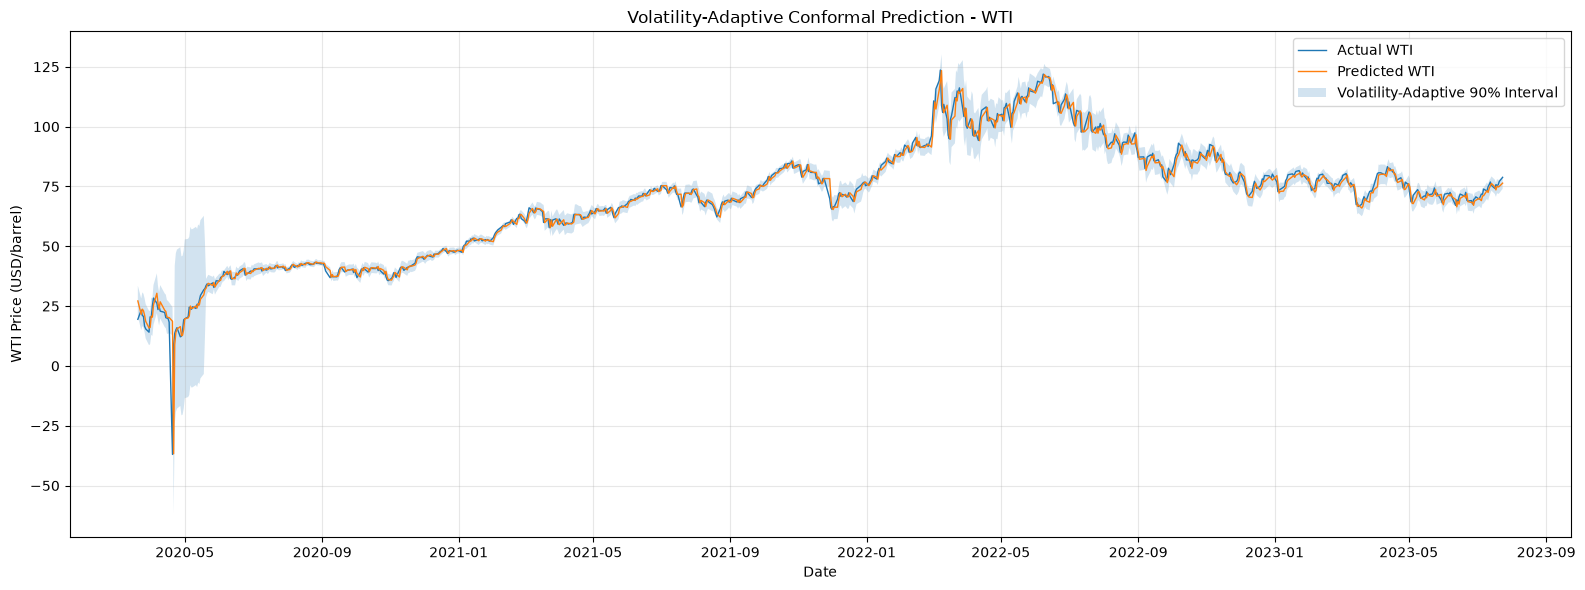

In [67]:
# ==========================================
# VISUALIZATION - VOLATILITY-ADAPTIVE CP
# ==========================================

plt.figure(figsize=(16, 6))

plt.plot(
    vol_adaptive_predictions["Date"],
    vol_adaptive_predictions["Actual"],
    label="Actual WTI",
    linewidth=1
)

plt.plot(
    vol_adaptive_predictions["Date"],
    vol_adaptive_predictions["Prediction"],
    label="Predicted WTI",
    linewidth=1
)

plt.fill_between(
    vol_adaptive_predictions["Date"],
    vol_adaptive_predictions["Lower"],
    vol_adaptive_predictions["Upper"],
    alpha=0.2,
    label="Volatility-Adaptive 90% Interval"
)

plt.title("Volatility-Adaptive Conformal Prediction - WTI")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [68]:
# ==========================================
# GARCH-ADAPTIVE CONFORMAL PREDICTION
# EGARCH(1,1), Student-t
# ==========================================

from arch import arch_model
import numpy as np
import pandas as pd

alpha = 0.10

# 1. Chuẩn bị chuỗi WTI Change
garch_cp_data = (
    data_multi_model[
        ["Date", "WTI_Change"]
    ]
    .copy()
    .reset_index(drop=True)
)

# Nhân 10 để phù hợp cách xây dựng GARCH trước đó
garch_cp_returns = (
    garch_cp_data["WTI_Change"] * 10
)

# 2. Ước lượng EGARCH chỉ trên Proper Train
egarch_cp_model = arch_model(
    garch_cp_returns,
    mean="AR",
    lags=1,
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_cp_result = egarch_cp_model.fit(
    last_obs=cp_split,
    update_freq=0,
    disp="off"
)

print(egarch_cp_result.summary())

# 3. Dự báo phương sai một bước cho Calibration và Test
egarch_cp_forecast = egarch_cp_result.forecast(
    start=cp_split - 1,
    horizon=1,
    align="target",
    reindex=True
)

# Chuyển phương sai từ thang nhân 10 về đơn vị gốc
egarch_cp_variance = (
    egarch_cp_forecast.variance["h.1"] / 100
)

# Độ lệch chuẩn có điều kiện
egarch_cp_volatility = np.sqrt(
    egarch_cp_variance
)

# 4. Lấy volatility theo đúng index Calibration và Test
sigma_cal_garch = (
    egarch_cp_volatility
    .iloc[X_cal.index]
    .to_numpy()
)

sigma_test_garch = (
    egarch_cp_volatility
    .iloc[X_test_cp.index]
    .to_numpy()
)

# 5. Kiểm tra
print("\n===== GARCH CALIBRATION CHECK =====")

print("Proper Train:", len(X_proper))
print("Calibration:", len(sigma_cal_garch))
print("Test:", len(sigma_test_garch))

print(
    "Calibration volatility hợp lệ:",
    np.isfinite(sigma_cal_garch).all()
)

print(
    "Test volatility hợp lệ:",
    np.isfinite(sigma_test_garch).all()
)

assert len(sigma_cal_garch) == len(X_cal)
assert len(sigma_test_garch) == len(X_test_cp)

assert np.isfinite(sigma_cal_garch).all()
assert np.isfinite(sigma_test_garch).all()

assert (sigma_cal_garch > 0).all()
assert (sigma_test_garch > 0).all()

                             AR - EGARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.002
Vol Model:                           EGARCH   Log-Likelihood:               -5024.23
Distribution:      Standardized Student's t   AIC:                           10062.5
Method:                  Maximum Likelihood   BIC:                           10098.7
                                              No. Observations:                 1306
Date:                      Sun, Nov 22 2026   Df Residuals:                     1304
Time:                              19:13:36   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [69]:
# ==========================================
# GARCH-ADAPTIVE CONFORMAL CALIBRATION
# ==========================================

# 1. Dự báo XGBoost trên Calibration
cal_pred_garch = cp_model.predict(X_cal)

# 2. Sai số tuyệt đối chuẩn hóa
garch_cal_scores = (
    np.abs(
        y_cal.to_numpy() - cal_pred_garch
    )
    / sigma_cal_garch
)

# 3. Quantile hữu hạn mẫu
sorted_garch_scores = np.sort(
    garch_cal_scores
)

n_garch_cal = len(sorted_garch_scores)

rank_garch = min(
    n_garch_cal,
    int(np.ceil(
        (n_garch_cal + 1) * (1 - alpha)
    ))
)

q_garch = sorted_garch_scores[
    rank_garch - 1
]

print("===== GARCH-ADAPTIVE CALIBRATION =====")
print("Calibration observations:", n_garch_cal)
print("Normalized quantile:", q_garch)

# 4. Dự báo XGBoost trên Test
pred_change_garch = cp_model.predict(X_test_cp)

actual_change_garch = (
    y_test_change_multi
    .loc[X_test_cp.index]
    .to_numpy()
)

# 5. Khôi phục giá WTI
previous_price_garch = (
    X_test_cp["wti_Lag1"].to_numpy()
)

pred_price_garch = (
    previous_price_garch + pred_change_garch
)

actual_price_garch = (
    y_test_multi
    .loc[X_test_cp.index]
    .to_numpy()
)

# 6. Bán kính khoảng dự báo
radius_garch = (
    q_garch * sigma_test_garch
)

lower_garch = (
    pred_price_garch - radius_garch
)

upper_garch = (
    pred_price_garch + radius_garch
)

# 7. Lưu kết quả
garch_adaptive_predictions = pd.DataFrame({
    "Date": data_multi_model.loc[
        X_test_cp.index, "Date"
    ].values,
    "Actual": actual_price_garch,
    "Prediction": pred_price_garch,
    "Lower": lower_garch,
    "Upper": upper_garch,
    "EGARCH_Volatility": sigma_test_garch,
    "Quantile": q_garch
})

garch_adaptive_predictions["Covered"] = (
    (
        garch_adaptive_predictions["Actual"]
        >= garch_adaptive_predictions["Lower"]
    )
    &
    (
        garch_adaptive_predictions["Actual"]
        <= garch_adaptive_predictions["Upper"]
    )
)

display(garch_adaptive_predictions.head())

===== GARCH-ADAPTIVE CALIBRATION =====
Calibration observations: 327
Normalized quantile: 1.7970104475856632


,Date,Actual,Prediction,Lower,Upper,EGARCH_Volatility,Quantile,Covered
0,2020-03-20,19.48,27.151649,23.153806,31.149491,2.224719,1.79701,False
1,2020-03-23,23.33,21.545984,17.231400,25.860569,2.400979,1.79701,True
2,2020-03-24,21.03,23.705476,19.414931,27.996021,2.387601,1.79701,True
3,2020-03-25,20.75,23.088736,18.759238,27.418234,2.409278,1.79701,True
4,2020-03-26,16.60,21.225238,16.996592,25.453885,2.353156,1.79701,False


In [70]:
# ==========================================
# EVALUATION - GARCH-ADAPTIVE CP
# ==========================================

actual = (
    garch_adaptive_predictions["Actual"].to_numpy()
)

lower = (
    garch_adaptive_predictions["Lower"].to_numpy()
)

upper = (
    garch_adaptive_predictions["Upper"].to_numpy()
)

covered = (
    (actual >= lower) &
    (actual <= upper)
)

coverage = covered.mean() * 100

width = upper - lower

average_width = width.mean()

interval_score = (
    width
    + (2 / alpha) * (lower - actual) * (actual < lower)
    + (2 / alpha) * (actual - upper) * (actual > upper)
)

garch_adaptive_results = pd.DataFrame([{
    "Method": "GARCH-Adaptive CP",
    "Nominal Coverage (%)": 90.0,
    "Actual Coverage (%)": coverage,
    "Average Width": average_width,
    "Interval Score": interval_score.mean()
}])

# Tổng hợp bốn phương pháp
cp_comparison_4 = pd.concat(
    [
        cp_results,
        rolling_cp_results,
        vol_adaptive_results,
        garch_adaptive_results
    ],
    ignore_index=True
)

print("===== FINAL CONFORMAL COMPARISON =====")
display(cp_comparison_4.round(4))

===== FINAL CONFORMAL COMPARISON =====


,Method,Nominal Coverage (%),Actual Coverage (%),Average Width,Interval Score
0,Split Conformal,90.0,76.4005,4.3812,13.2262
1,Rolling Conformal 126,90.0,90.5840,6.8762,11.8989
2,Volatility-Adaptive CP,90.0,93.5638,8.7476,11.8247
3,GARCH-Adaptive CP,90.0,90.1073,6.3939,10.9748


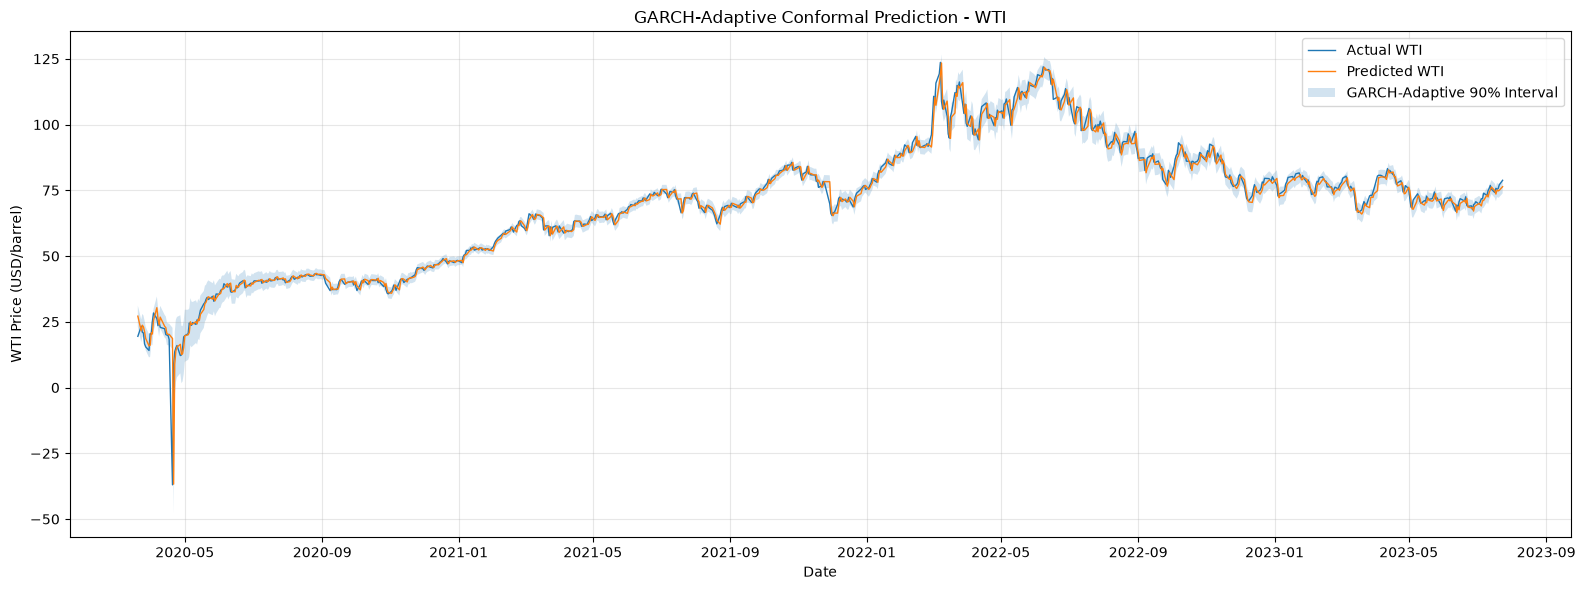

In [71]:
# ==========================================
# VISUALIZATION - GARCH-ADAPTIVE CP
# ==========================================

plt.figure(figsize=(16, 6))

plt.plot(
    garch_adaptive_predictions["Date"],
    garch_adaptive_predictions["Actual"],
    label="Actual WTI",
    linewidth=1
)

plt.plot(
    garch_adaptive_predictions["Date"],
    garch_adaptive_predictions["Prediction"],
    label="Predicted WTI",
    linewidth=1
)

plt.fill_between(
    garch_adaptive_predictions["Date"],
    garch_adaptive_predictions["Lower"],
    garch_adaptive_predictions["Upper"],
    alpha=0.2,
    label="GARCH-Adaptive 90% Interval"
)

plt.title("GARCH-Adaptive Conformal Prediction - WTI")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [72]:
# ==========================================
# CONDITIONAL COVERAGE BY VOLATILITY REGIME
# ==========================================

# 1. Lấy volatility trong 20 phiên trước mỗi ngày Test
vol_test_regime = volatility_series.loc[
    X_test_cp.index
].reset_index(drop=True)

# 2. Xác định ngưỡng Low / Medium / High
q_low = vol_test_regime.quantile(1/3)
q_high = vol_test_regime.quantile(2/3)

regimes = pd.cut(
    vol_test_regime,
    bins=[-np.inf, q_low, q_high, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Volatility threshold:")
print("Low / Medium:", q_low)
print("Medium / High:", q_high)

# 3. Các phương pháp cần so sánh
method_frames = {
    "Split CP": cp_predictions,
    "Rolling CP 126": rolling_predictions,
    "Volatility-Adaptive CP": vol_adaptive_predictions,
    "GARCH-Adaptive CP": garch_adaptive_predictions
}

# 4. Kiểm tra sự khớp ngày giữa các phương pháp
reference_dates = pd.to_datetime(
    cp_predictions["Date"]
).reset_index(drop=True)

regime_results = []

for method, frame in method_frames.items():

    df = frame.copy().reset_index(drop=True)

    assert len(df) == 839
    assert pd.to_datetime(df["Date"]).reset_index(
        drop=True
    ).equals(reference_dates), (
        f"Ngày không khớp ở {method}"
    )

    df["Regime"] = regimes

    # Tính Coverage, Width, Interval Score từng nhóm
    for regime in ["Low", "Medium", "High"]:

        subset = df[df["Regime"] == regime]

        actual = subset["Actual"].to_numpy()
        lower = subset["Lower"].to_numpy()
        upper = subset["Upper"].to_numpy()

        covered = (
            (actual >= lower) &
            (actual <= upper)
        )

        width = upper - lower

        score = (
            width
            + (2 / 0.10) * (lower - actual)
            * (actual < lower)
            + (2 / 0.10) * (actual - upper)
            * (actual > upper)
        )

        regime_results.append({
            "Method": method,
            "Regime": regime,
            "N": len(subset),
            "Coverage (%)": covered.mean() * 100,
            "Average Width": width.mean(),
            "Interval Score": score.mean()
        })

# 5. Hiển thị kết quả
regime_results_df = pd.DataFrame(regime_results)

print("\n===== CONDITIONAL CONFORMAL RESULTS =====")

display(
    regime_results_df.round(4)
)

Volatility threshold:
Low / Medium: 1.2722417785534463
Medium / High: 1.9259454957582967

===== CONDITIONAL CONFORMAL RESULTS =====


,Method,Regime,N,Coverage (%),Average Width,Interval Score
0,Split CP,Low,280,93.9286,4.3812,5.2356
1,Split CP,Medium,280,79.6429,4.3812,8.0304
2,Split CP,High,279,55.5556,4.3812,26.4600
3,Rolling CP 126,Low,280,95.3571,5.1519,5.9835
4,Rolling CP 126,Medium,280,91.4286,6.0397,7.9348
5,Rolling CP 126,High,279,84.9462,9.4462,21.8137
6,Volatility-Adaptive CP,Low,280,90.3571,3.8371,5.0016
7,Volatility-Adaptive CP,Medium,280,95.7143,6.3523,7.6611
8,Volatility-Adaptive CP,High,279,94.6237,16.0794,22.8508
9,GARCH-Adaptive CP,Low,280,93.2143,4.3111,5.2216


In [73]:
# ==========================================
# MOVING BLOCK BOOTSTRAP
# GARCH-ADAPTIVE VS OTHER CP METHODS
# ==========================================

alpha_cp = 0.10
B = 5000
block_lengths = [5, 10, 20]

# 1. Chuẩn bị kết quả của bốn phương pháp
method_frames = {
    "Split CP": cp_predictions,
    "Rolling CP 126": rolling_predictions,
    "Volatility-Adaptive CP": vol_adaptive_predictions,
    "GARCH-Adaptive CP": garch_adaptive_predictions
}

# Tính Interval Score từng ngày
def get_interval_metrics(df):
    df = df.copy().sort_values("Date").reset_index(drop=True)

    actual = df["Actual"].to_numpy()
    lower = df["Lower"].to_numpy()
    upper = df["Upper"].to_numpy()

    width = upper - lower

    score = (
        width
        + (2 / alpha_cp) * (lower - actual) * (actual < lower)
        + (2 / alpha_cp) * (actual - upper) * (actual > upper)
    )

    covered = (
        (actual >= lower) &
        (actual <= upper)
    )

    return pd.DataFrame({
        "Date": pd.to_datetime(df["Date"]),
        "Interval_Score": score,
        "Covered": covered.astype(float)
    })


method_metrics = {
    name: get_interval_metrics(df)
    for name, df in method_frames.items()
}

# Kiểm tra ngày có khớp hoàn toàn không
reference_dates = method_metrics[
    "GARCH-Adaptive CP"
]["Date"]

for name, df in method_metrics.items():
    assert df["Date"].equals(reference_dates), (
        f"Ngày Test không khớp: {name}"
    )

print("Số ngày Test:", len(reference_dates))
print("Tất cả phương pháp có ngày khớp: True")


# 2. Hàm lấy mẫu Moving Block Bootstrap
def moving_block_indices(n, block_length, rng):

    number_blocks = int(np.ceil(n / block_length))

    starts = rng.integers(
        0,
        n - block_length + 1,
        size=number_blocks
    )

    indices = np.concatenate([
        np.arange(start, start + block_length)
        for start in starts
    ])

    return indices[:n]


# 3. Bootstrap chênh lệch từng cặp
rng = np.random.default_rng(42)

comparators = [
    "Split CP",
    "Rolling CP 126",
    "Volatility-Adaptive CP"
]

mbb_results = []

garch_score = method_metrics[
    "GARCH-Adaptive CP"
]["Interval_Score"].to_numpy()

garch_covered = method_metrics[
    "GARCH-Adaptive CP"
]["Covered"].to_numpy()

n = len(garch_score)

for comparator in comparators:

    other_score = method_metrics[
        comparator
    ]["Interval_Score"].to_numpy()

    other_covered = method_metrics[
        comparator
    ]["Covered"].to_numpy()

    # Hiệu số: GARCH - Comparator
    score_diff = garch_score - other_score

    coverage_diff = (
        garch_covered - other_covered
    ) * 100

    observed_score_diff = score_diff.mean()
    observed_coverage_diff = coverage_diff.mean()

    for L in block_lengths:

        boot_score = []
        boot_coverage = []

        for b in range(B):

            idx = moving_block_indices(
                n, L, rng
            )

            boot_score.append(
                score_diff[idx].mean()
            )

            boot_coverage.append(
                coverage_diff[idx].mean()
            )

        # Khoảng tin cậy 95%
        score_ci = np.percentile(
            boot_score, [2.5, 97.5]
        )

        coverage_ci = np.percentile(
            boot_coverage, [2.5, 97.5]
        )

        mbb_results.append({
            "Comparator": comparator,
            "Block_Length": L,

            "Mean_Score_Difference": observed_score_diff,
            "Score_CI_Lower": score_ci[0],
            "Score_CI_Upper": score_ci[1],

            "Coverage_Difference_pp": observed_coverage_diff,
            "Coverage_CI_Lower": coverage_ci[0],
            "Coverage_CI_Upper": coverage_ci[1],

            "GARCH_Score_Better": score_ci[1] < 0
        })


# 4. Hiển thị kết quả
mbb_results_df = pd.DataFrame(mbb_results)

print("\n===== MOVING BLOCK BOOTSTRAP RESULTS =====")

display(
    mbb_results_df.round(4)
)

Số ngày Test: 839
Tất cả phương pháp có ngày khớp: True

===== MOVING BLOCK BOOTSTRAP RESULTS =====


,Comparator,Block_Length,Mean_Score_Difference,Score_CI_Lower,Score_CI_Upper,Coverage_Difference_pp,Coverage_CI_Lower,Coverage_CI_Upper,GARCH_Score_Better
0,Split CP,5,-2.2514,-3.2963,-1.2720,13.7068,10.6079,16.8057,True
1,Split CP,10,-2.2514,-3.4590,-1.0115,13.7068,9.7735,17.1633,True
2,Split CP,20,-2.2514,-3.6914,-0.7167,13.7068,8.4625,18.1168,True
3,Rolling CP 126,5,-0.9240,-1.4264,-0.4128,-0.4768,-2.0262,1.0727,True
4,Rolling CP 126,10,-0.9240,-1.4208,-0.3117,-0.4768,-2.3838,0.9535,True
5,Rolling CP 126,20,-0.9240,-1.4446,-0.2244,-0.4768,-2.7414,1.0727,True
6,Volatility-Adaptive CP,5,-0.8499,-2.1448,0.2716,-3.4565,-5.4827,-1.6687,False
7,Volatility-Adaptive CP,10,-0.8499,-2.4633,0.3615,-3.4565,-5.8403,-1.3111,False
8,Volatility-Adaptive CP,20,-0.8499,-2.6532,0.4406,-3.4565,-6.0787,-0.8343,False


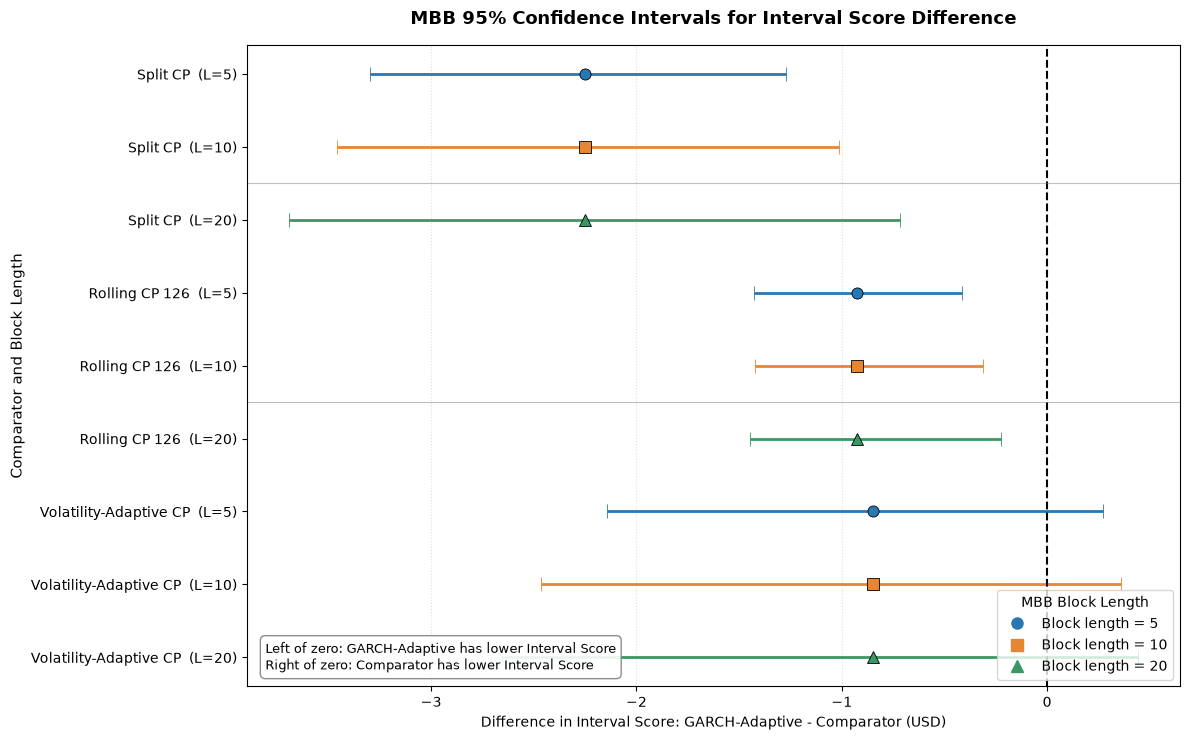

In [178]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# 1. Lấy kết quả MBB đã tính trong notebook
plot_df = mbb_results_df.copy()

required_columns = [
    "Comparator",
    "Block_Length",
    "Mean_Score_Difference",
    "Score_CI_Lower",
    "Score_CI_Upper"
]

missing_columns = [
    col for col in required_columns
    if col not in plot_df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột: {missing_columns}"
    )

# 2. Chuẩn hóa dữ liệu
plot_df["Block_Length"] = pd.to_numeric(
    plot_df["Block_Length"]
)

comparator_order = [
    "Split CP",
    "Rolling CP 126",
    "Volatility-Adaptive CP"
]

block_order = [5, 10, 20]

plot_df = plot_df[
    plot_df["Comparator"].isin(comparator_order)
    & plot_df["Block_Length"].isin(block_order)
].copy()

plot_df["Comparator"] = pd.Categorical(
    plot_df["Comparator"],
    categories=comparator_order,
    ordered=True
)

plot_df = plot_df.sort_values(
    ["Comparator", "Block_Length"]
).reset_index(drop=True)

# Kiểm tra đủ 9 kết quả
assert len(plot_df) == 9, (
    f"Cần 9 kết quả MBB, hiện có {len(plot_df)}"
)

# 3. Thiết lập kiểu hiển thị theo Block Length
colors = {
    5: "#2878B5",
    10: "#E68632",
    20: "#399764"
}

markers = {
    5: "o",
    10: "s",
    20: "^"
}

# 4. Tạo vị trí các dòng
y_positions = np.arange(len(plot_df))[::-1]

fig, ax = plt.subplots(figsize=(12, 7.5))

# 5. Vẽ từng khoảng tin cậy 95%
for i, row in plot_df.iterrows():

    mean = row["Mean_Score_Difference"]
    lower = row["Score_CI_Lower"]
    upper = row["Score_CI_Upper"]
    block = int(row["Block_Length"])

    # Kiểm tra khoảng tin cậy hợp lệ
    if not (lower <= mean <= upper):
        raise ValueError(
            f"CI không hợp lệ tại {row['Comparator']}, "
            f"Block Length {block}"
        )

    ax.errorbar(
        x=mean,
        y=y_positions[i],
        xerr=np.array([
            [mean - lower],
            [upper - mean]
        ]),
        fmt=markers[block],
        color=colors[block],
        ecolor=colors[block],
        markersize=8,
        capsize=5,
        elinewidth=2,
        markeredgecolor="black",
        markeredgewidth=0.6
    )

# 6. Đường tham chiếu tại 0
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Zero difference"
)

# 7. Nhãn trục Y
labels = [
    f"{row['Comparator']}  (L={int(row['Block_Length'])})"
    for _, row in plot_df.iterrows()
]

ax.set_yticks(y_positions)
ax.set_yticklabels(labels, fontsize=10)

# Phân tách 3 nhóm đối chứng
ax.axhline(6.5, color="gray", linewidth=0.8, alpha=0.5)
ax.axhline(3.5, color="gray", linewidth=0.8, alpha=0.5)

# 8. Chú thích block length
legend_handles = [
    Line2D(
        [0], [0],
        color=colors[L],
        marker=markers[L],
        linestyle="none",
        markersize=8,
        label=f"Block length = {L}"
    )
    for L in block_order
]

ax.legend(
    handles=legend_handles,
    title="MBB Block Length",
    loc="lower right"
)

# 9. Nhãn và tiêu đề
ax.set_title(
    "MBB 95% Confidence Intervals for Interval Score Difference",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Difference in Interval Score: GARCH-Adaptive - Comparator (USD)",
    fontsize=10
)

ax.set_ylabel("Comparator and Block Length", fontsize=11)

ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.4
)

# 10. Giải thích chiều chênh lệch
ax.text(
    0.02, 0.02,
    "Left of zero: GARCH-Adaptive has lower Interval Score\n"
    "Right of zero: Comparator has lower Interval Score",
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

fig.tight_layout()

# 11. Lưu hình
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/mbb_confidence_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


===== ROLLING COVERAGE SUMMARY =====


,Method,Mean_Rolling_Coverage,Median_Rolling_Coverage,Min_Rolling_Coverage,Max_Rolling_Coverage,Last_Rolling_Coverage
0,Split CP,77.2798,84.9206,45.2381,97.6190,76.1905
1,Rolling CP 126,91.2020,93.6508,75.3968,100.0000,93.6508
2,Volatility-Adaptive CP,93.3874,93.6508,89.6825,96.8254,95.2381
3,GARCH-Adaptive CP,89.6225,90.4762,76.9841,98.4127,94.4444


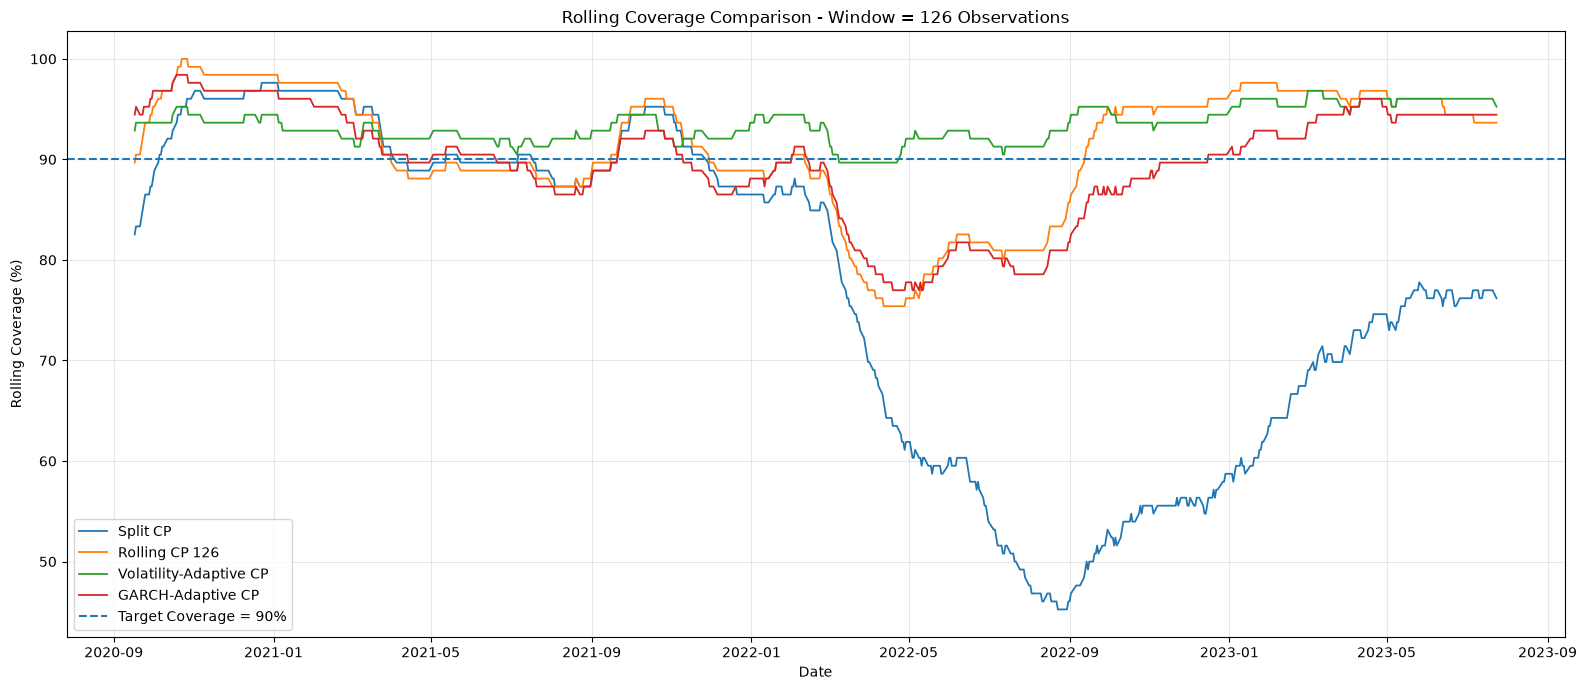

In [74]:
# ==========================================
# ROLLING COVERAGE - 126 OBSERVATIONS
# ==========================================

window_size = 126
target_coverage = 90.0

# 1. Chuẩn bị dữ liệu bốn phương pháp
method_frames = {
    "Split CP": cp_predictions,
    "Rolling CP 126": rolling_predictions,
    "Volatility-Adaptive CP": vol_adaptive_predictions,
    "GARCH-Adaptive CP": garch_adaptive_predictions
}

rolling_coverage_results = {}
rolling_coverage_summary = []

# 2. Kiểm tra ngày và tính Rolling Coverage
reference_dates = pd.to_datetime(
    cp_predictions["Date"]
).reset_index(drop=True)

for method, frame in method_frames.items():

    df = frame.copy().sort_values("Date").reset_index(drop=True)

    # Đảm bảo cùng 839 ngày Test
    assert len(df) == 839
    assert pd.to_datetime(df["Date"]).equals(reference_dates), (
        f"Ngày không khớp: {method}"
    )

    # Rolling Coverage trên 126 quan sát
    rolling_coverage = (
        df["Covered"]
        .astype(float)
        .rolling(
            window=window_size,
            min_periods=window_size
        )
        .mean() * 100
    )

    rolling_coverage_results[method] = rolling_coverage

    # Tổng hợp độ ổn định
    valid_coverage = rolling_coverage.dropna()

    rolling_coverage_summary.append({
        "Method": method,
        "Mean_Rolling_Coverage": valid_coverage.mean(),
        "Median_Rolling_Coverage": valid_coverage.median(),
        "Min_Rolling_Coverage": valid_coverage.min(),
        "Max_Rolling_Coverage": valid_coverage.max(),
        "Last_Rolling_Coverage": valid_coverage.iloc[-1]
    })


# 3. Hiển thị bảng tổng hợp
rolling_coverage_summary_df = pd.DataFrame(
    rolling_coverage_summary
)

print("===== ROLLING COVERAGE SUMMARY =====")
display(rolling_coverage_summary_df.round(4))


# 4. Vẽ biểu đồ
plt.figure(figsize=(16, 7))

for method, coverage in rolling_coverage_results.items():

    plt.plot(
        reference_dates,
        coverage,
        label=method,
        linewidth=1.3
    )

plt.axhline(
    y=target_coverage,
    linestyle="--",
    linewidth=1.5,
    label="Target Coverage = 90%"
)

plt.title(
    "Rolling Coverage Comparison - Window = 126 Observations"
)

plt.xlabel("Date")
plt.ylabel("Rolling Coverage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [75]:
# ==========================================
# COVERAGE STABILITY ANALYSIS
# ==========================================

stability_results = []

for method, coverage in rolling_coverage_results.items():

    valid = coverage.dropna()

    stability_results.append({
        "Method": method,
        "Mean_Coverage": valid.mean(),
        "Std_Coverage": valid.std(),
        "MAE_From_Target_90": (
            valid - 90
        ).abs().mean(),
        "Range": valid.max() - valid.min()
    })

coverage_stability_df = pd.DataFrame(stability_results)

print("===== COVERAGE STABILITY =====")
display(coverage_stability_df.round(4))

===== COVERAGE STABILITY =====


,Method,Mean_Coverage,Std_Coverage,MAE_From_Target_90,Range
0,Split CP,77.2798,16.2059,15.0909,52.3810
1,Rolling CP 126,91.2020,6.2530,5.3490,24.6032
2,Volatility-Adaptive CP,93.3874,1.7240,3.4158,7.1429
3,GARCH-Adaptive CP,89.6225,5.5550,4.3391,21.4286


In [76]:
# ==========================================
# FINAL CONFORMAL PREDICTION SUMMARY
# ==========================================

# 1. Đồng nhất tên phương pháp
stability_df_fixed = coverage_stability_df.copy()

stability_df_fixed["Method"] = (
    stability_df_fixed["Method"].replace({
        "Split CP": "Split Conformal",
        "Rolling CP 126": "Rolling Conformal 126"
    })
)

# 2. Ghép hai bảng
final_conformal_table = cp_comparison_4.merge(
    stability_df_fixed,
    on="Method",
    how="left",
    validate="one_to_one"
)

# 3. Đổi tên cột
final_conformal_table = final_conformal_table.rename(
    columns={
        "Actual Coverage (%)": "Overall Coverage (%)",
        "Average Width": "Average Width (USD)",
        "Interval Score": "Interval Score (USD)",
        "Mean_Coverage": "Mean Rolling Coverage (%)",
        "Std_Coverage": "Rolling Coverage Std",
        "MAE_From_Target_90": "MAE from 90% Target",
        "Range": "Rolling Coverage Range"
    }
)

# 4. Kiểm tra không còn NaN
stability_columns = [
    "Mean Rolling Coverage (%)",
    "Rolling Coverage Std",
    "MAE from 90% Target",
    "Rolling Coverage Range"
]

assert not final_conformal_table[
    stability_columns
].isna().any().any(), "Vẫn còn giá trị thiếu!"

# 5. Hiển thị
print("===== FINAL CONFORMAL PREDICTION SUMMARY =====")
display(final_conformal_table.round(4))

# 6. Lưu kết quả
final_conformal_table.to_csv(
    "final_conformal_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu final_conformal_results.csv")

===== FINAL CONFORMAL PREDICTION SUMMARY =====


,Method,Nominal Coverage (%),Overall Coverage (%),Average Width (USD),Interval Score (USD),Mean Rolling Coverage (%),Rolling Coverage Std,MAE from 90% Target,Rolling Coverage Range
0,Split Conformal,90.0,76.4005,4.3812,13.2262,77.2798,16.2059,15.0909,52.3810
1,Rolling Conformal 126,90.0,90.5840,6.8762,11.8989,91.2020,6.2530,5.3490,24.6032
2,Volatility-Adaptive CP,90.0,93.5638,8.7476,11.8247,93.3874,1.7240,3.4158,7.1429
3,GARCH-Adaptive CP,90.0,90.1073,6.3939,10.9748,89.6225,5.5550,4.3391,21.4286


Đã lưu final_conformal_results.csv


In [77]:
import shap

explainer_e5 = shap.TreeExplainer(best_model_e5)

X_test_sample = X_test_multi[features_e5].sample(
    n=500,
    random_state=42
)

shap_values_e5 = explainer_e5.shap_values(X_test_sample)

print("SHAP shape:", shap_values_e5.shape)

SHAP shape: (500, 23)


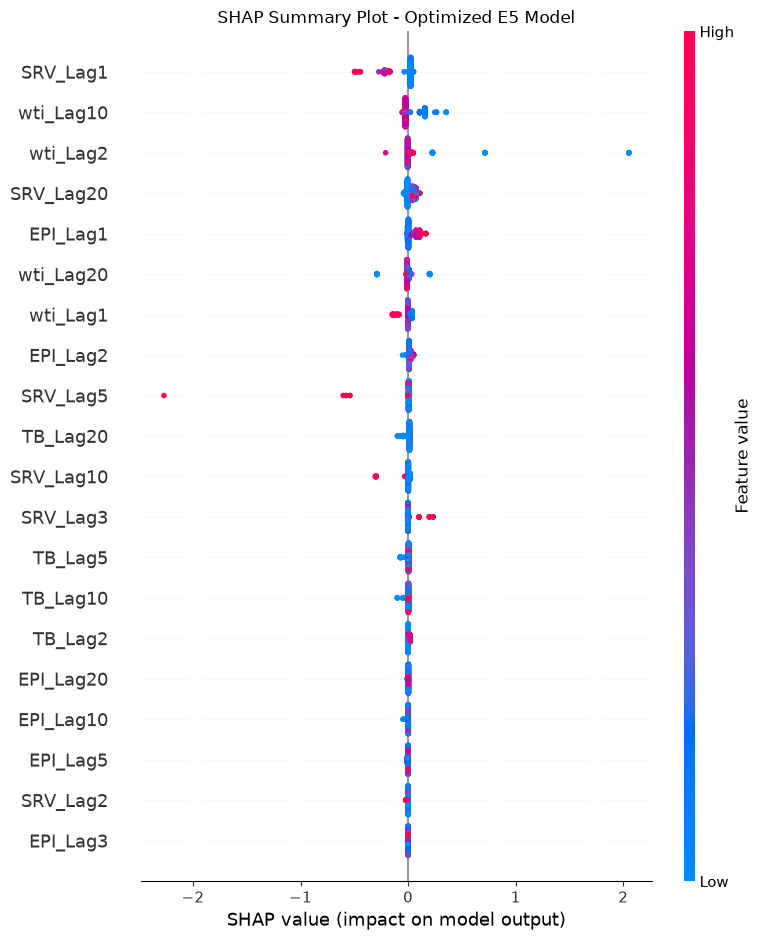

In [78]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values_e5,
    X_test_sample,
    show=False
)

plt.title("SHAP Summary Plot - Optimized E5 Model")
plt.tight_layout()
plt.show()

In [79]:
import pandas as pd
import numpy as np

# Tính giá trị SHAP tuyệt đối trung bình của từng đặc trưng
shap_importance = np.abs(shap_values_e5).mean(axis=0)

# Tạo bảng gồm tên đặc trưng và mức độ quan trọng
shap_df = pd.DataFrame({
    "Feature": X_test_sample.columns,
    "Importance": shap_importance
})

# Xác định nhóm biến từ tên đặc trưng
shap_df["Group"] = shap_df["Feature"].str.split("_Lag").str[0]

# Cộng mức độ quan trọng của các Lag thuộc cùng nhóm
group_importance = (
    shap_df.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("Group SHAP Importance:")
print(group_importance)

Group SHAP Importance:
Group
wti    0.137635
SRV    0.129867
EPI    0.047518
TB     0.025738
Name: Importance, dtype: float32


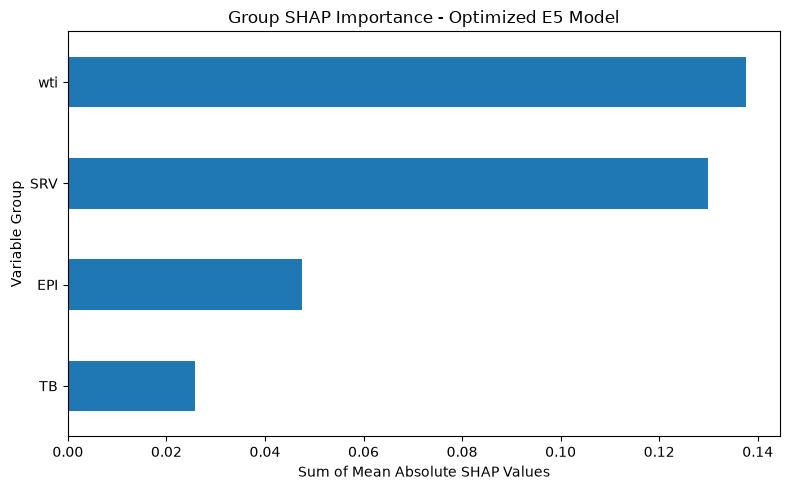

In [80]:
plt.figure(figsize=(8, 5))

group_importance.sort_values().plot(
    kind="barh"
)

plt.title("Group SHAP Importance - Optimized E5 Model")
plt.xlabel("Sum of Mean Absolute SHAP Values")
plt.ylabel("Variable Group")
plt.tight_layout()
plt.show()

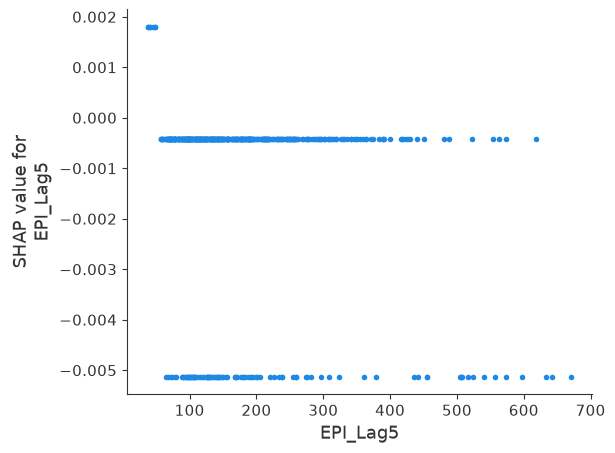

In [81]:
shap.dependence_plot(
    "EPI_Lag5",
    shap_values_e5,
    X_test_sample,
    interaction_index=None
)

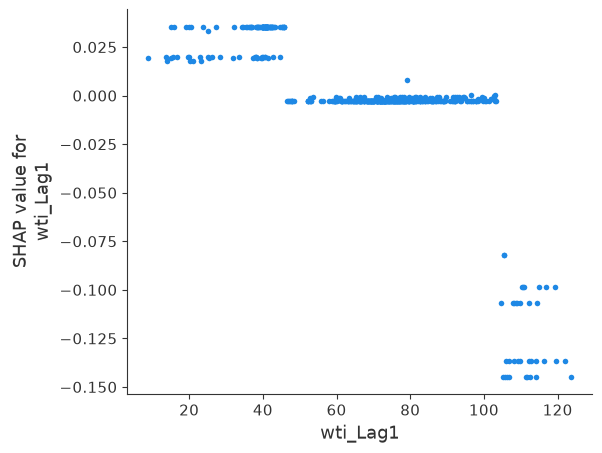

In [82]:
shap.dependence_plot(
    "wti_Lag1",
    shap_values_e5,
    X_test_sample,
    interaction_index=None
)

In [83]:
# Tính SHAP Interaction Values
interaction_values = explainer_e5.shap_interaction_values(
    X_test_sample
)

print("Interaction shape:", interaction_values.shape)

Interaction shape: (500, 23, 23)


In [84]:
# Tính mức độ tương tác trung bình tuyệt đối
mean_interaction = np.abs(interaction_values).mean(axis=0)

# Chỉ lấy nửa trên của ma trận, không lấy đường chéo
upper_indices = np.triu_indices_from(
    mean_interaction, k=1
)

interaction_df = pd.DataFrame({
    "Feature 1": X_test_sample.columns[upper_indices[0]],
    "Feature 2": X_test_sample.columns[upper_indices[1]],
    "Interaction Importance": mean_interaction[upper_indices]
})

# Sắp xếp giảm dần
interaction_df = interaction_df.sort_values(
    by="Interaction Importance",
    ascending=False
)

print("Top 10 feature interactions:")
print(interaction_df.head(10).to_string(index=False))

Top 10 feature interactions:
Feature 1 Feature 2  Interaction Importance
 wti_Lag2  SRV_Lag5                0.014631
 wti_Lag2 wti_Lag20                0.012489
 SRV_Lag1 SRV_Lag10                0.010716
wti_Lag10  EPI_Lag1                0.010487
 EPI_Lag1 SRV_Lag20                0.006602
wti_Lag10  EPI_Lag2                0.005538
 EPI_Lag2  SRV_Lag1                0.003876
 wti_Lag1  SRV_Lag1                0.002969
wti_Lag10  SRV_Lag3                0.002410
  TB_Lag2 SRV_Lag20                0.002354


In [85]:
pair = interaction_df[
    (
        (interaction_df["Feature 1"] == "EPI_Lag5") &
        (interaction_df["Feature 2"] == "wti_Lag1")
    ) |
    (
        (interaction_df["Feature 1"] == "wti_Lag1") &
        (interaction_df["Feature 2"] == "EPI_Lag5")
    )
]

print(pair)

   Feature 1 Feature 2  Interaction Importance
13  wti_Lag1  EPI_Lag5                     0.0


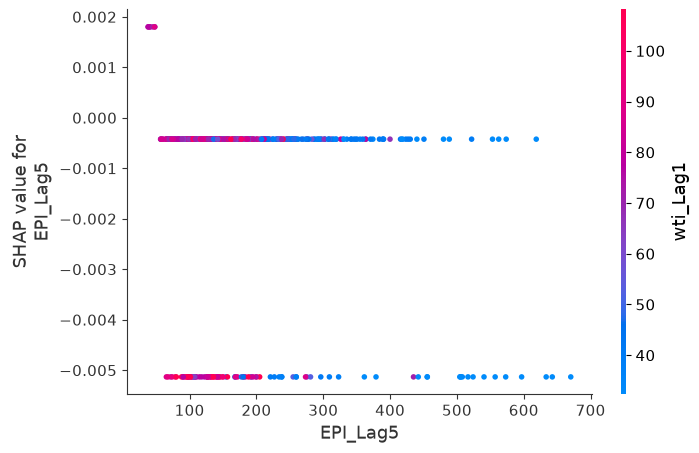

In [86]:
shap.dependence_plot(
    "EPI_Lag5",
    shap_values_e5,
    X_test_sample,
    interaction_index="wti_Lag1"
)

In [87]:
# Lấy vị trí của hai đặc trưng
idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

# Lấy SHAP interaction của cặp biến
pair_interaction = interaction_values[:, idx_epi, idx_wti]

print("Mean interaction:", np.mean(pair_interaction))
print("Mean absolute interaction:", np.mean(np.abs(pair_interaction)))
print("Min interaction:", np.min(pair_interaction))
print("Max interaction:", np.max(pair_interaction))

Mean interaction: 0.0
Mean absolute interaction: 0.0
Min interaction: 0.0
Max interaction: 0.0


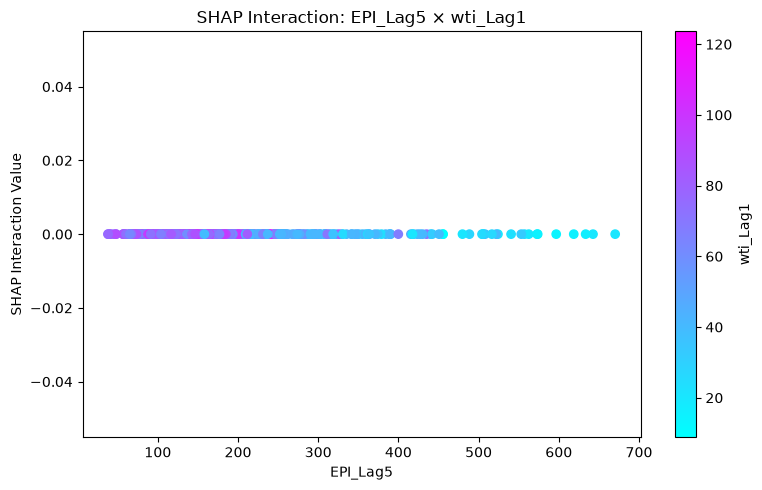

In [88]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_sample["EPI_Lag5"],
    pair_interaction,
    c=X_test_sample["wti_Lag1"],
    cmap="cool"
)

plt.colorbar(label="wti_Lag1")
plt.xlabel("EPI_Lag5")
plt.ylabel("SHAP Interaction Value")
plt.title("SHAP Interaction: EPI_Lag5 × wti_Lag1")
plt.tight_layout()
plt.show()

In [89]:
# Tạo bảng dữ liệu tương tác của cặp EPI_Lag5 và wti_Lag1
interaction_check = pd.DataFrame({
    "EPI_Lag5": X_test_sample["EPI_Lag5"].values,
    "wti_Lag1": X_test_sample["wti_Lag1"].values,
    "Interaction": pair_interaction
})

# Sắp xếp các quan sát có tương tác âm mạnh nhất
extreme_interactions = interaction_check.sort_values(
    by="Interaction",
    ascending=True
)

print("10 observations with strongest negative interactions:")
print(extreme_interactions.head(10).to_string(index=False))

10 observations with strongest negative interactions:
 EPI_Lag5  wti_Lag1  Interaction
   157.94     53.00          0.0
   127.96     69.71          0.0
   389.20     40.56          0.0
   322.96     37.91          0.0
   163.06     71.07          0.0
   129.06     78.57          0.0
   642.66     19.72          0.0
    78.70     65.49          0.0
   167.78     65.36          0.0
   190.98     73.40          0.0


In [90]:
seeds = [42, 100, 2026]

stability_results = []

idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

for seed in seeds:

    sample = X_test_multi[features_e5].sample(
        n=500,
        random_state=seed
    )

    interactions = explainer_e5.shap_interaction_values(sample)

    pair_values = interactions[:, idx_epi, idx_wti]

    stability_results.append({
        "Random State": seed,
        "Mean Interaction": np.mean(pair_values),
        "Mean Absolute Interaction": np.mean(np.abs(pair_values)),
        "Minimum": np.min(pair_values),
        "Maximum": np.max(pair_values),
        "Negative Percentage": np.mean(pair_values < 0) * 100
    })

stability_df = pd.DataFrame(stability_results)

print(stability_df.round(6).to_string(index=False))

 Random State  Mean Interaction  Mean Absolute Interaction  Minimum  Maximum  Negative Percentage
           42               0.0                        0.0      0.0      0.0                  0.0
          100               0.0                        0.0      0.0      0.0                  0.0
         2026               0.0                        0.0      0.0      0.0                  0.0


In [91]:
# Tính SHAP Interaction trên toàn bộ Test set
interaction_all = explainer_e5.shap_interaction_values(
    X_test_multi[features_e5]
)

# Vị trí hai đặc trưng
idx_epi = X_test_sample.columns.get_loc("EPI_Lag5")
idx_wti = X_test_sample.columns.get_loc("wti_Lag1")

# Trích xuất tương tác
pair_all = interaction_all[:, idx_epi, idx_wti]

# Tổng hợp kết quả
print("Number of observations:", len(pair_all))
print("Mean Interaction:", np.mean(pair_all))
print("Mean Absolute Interaction:", np.mean(np.abs(pair_all)))
print("Minimum:", np.min(pair_all))
print("Maximum:", np.max(pair_all))
print("Negative Percentage:", np.mean(pair_all < 0) * 100)

Number of observations: 839
Mean Interaction: 0.0
Mean Absolute Interaction: 0.0
Minimum: 0.0
Maximum: 0.0
Negative Percentage: 0.0


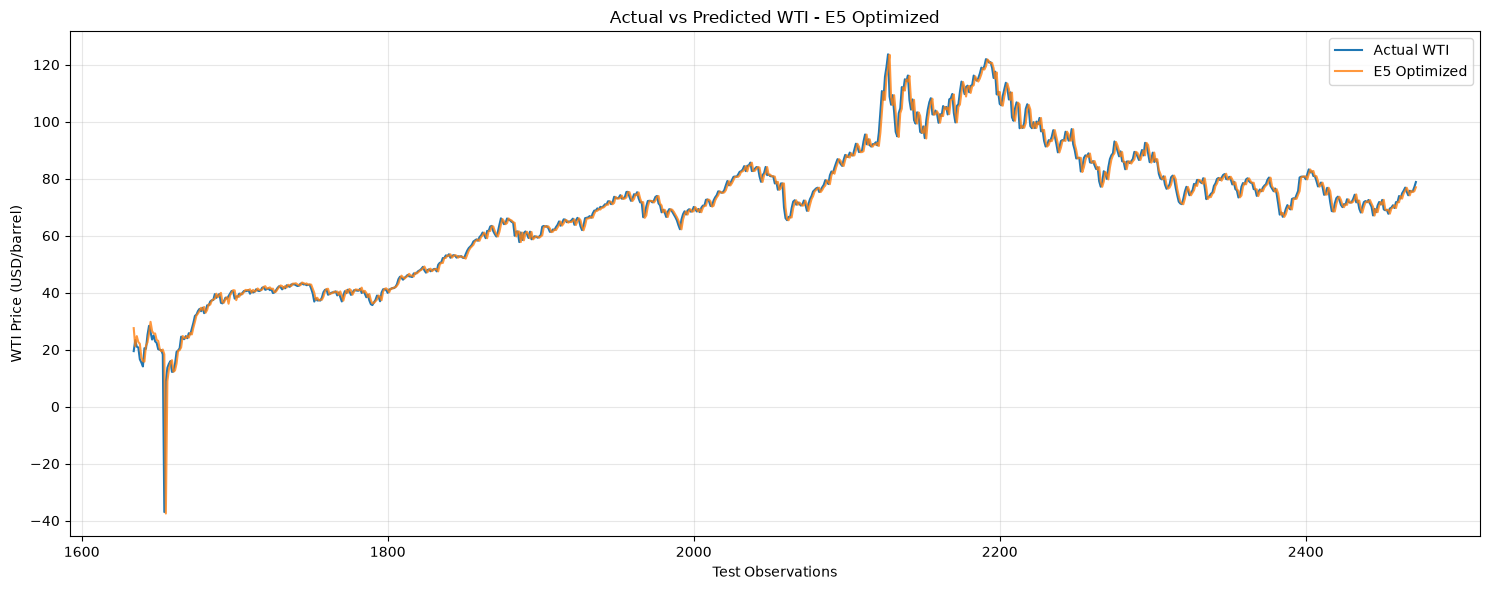

In [92]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_change_multi.index,
    y_test_change_multi.values + previous_price,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    y_test_change_multi.index,
    y_pred_price,
    label="E5 Optimized",
    alpha=0.8
)

plt.title("Actual vs Predicted WTI - E5 Optimized")
plt.xlabel("Test Observations")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

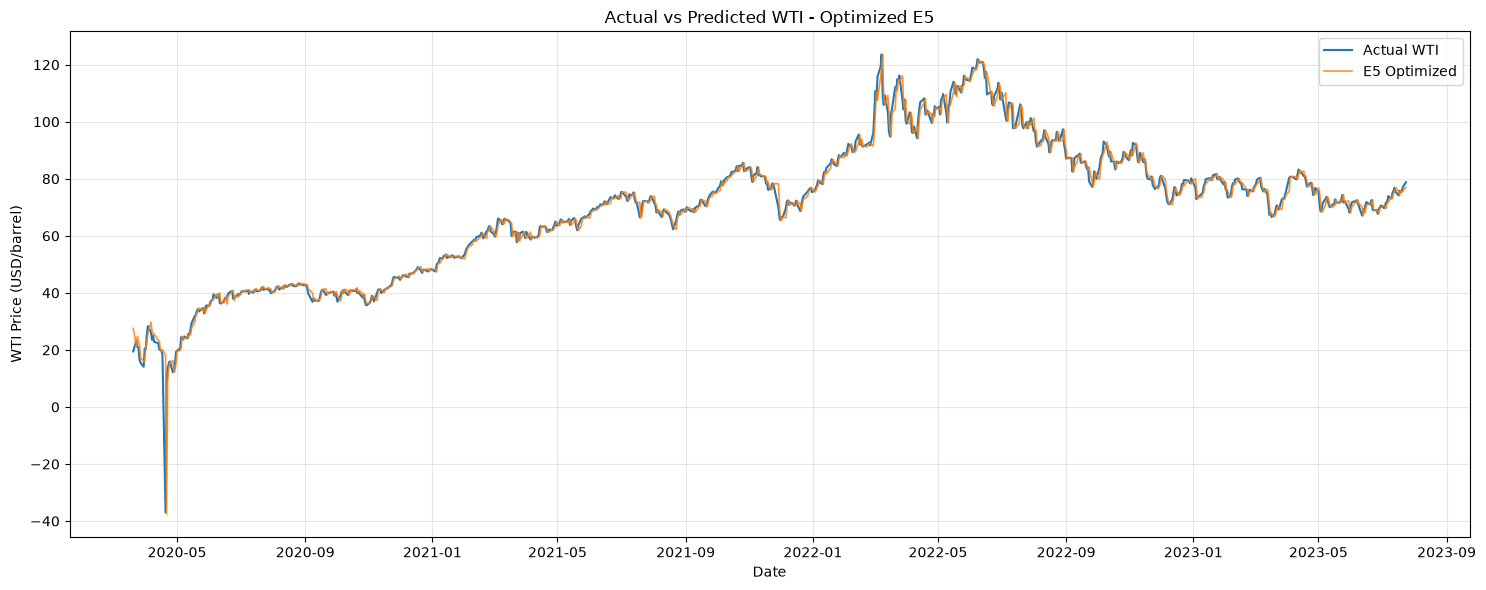

In [93]:
# Lấy ngày tháng của tập Test
test_dates = data_multi_model["Date"].iloc[len(X_train_multi):]

# Lấy giá WTI thực tế
actual_wti = data_multi_model["wti"].iloc[len(X_train_multi):]

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    actual_wti,
    label="Actual WTI",
    linewidth=1.5
)

plt.plot(
    test_dates,
    y_pred_price,
    label="E5 Optimized",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Actual vs Predicted WTI - Optimized E5")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
# Kiểm tra các biến liên quan đến mô hình và dữ liệu dự đoán
for name in sorted(globals()):
    if any(key in name.lower() for key in [
        "model_change",
        "x_test_uni",
        "y_pred",
        "features_uni"
    ]):
        print(name)

X_test_uni
features_uni
model_change_multi
model_change_uni
y_pred_change
y_pred_multi
y_pred_price
y_pred_uni


In [95]:
# Dự đoán mức thay đổi giá WTI bằng E3 Univariate
y_pred_change_uni = model_change_uni.predict(
    X_test_uni[features_uni]
)

# Lấy giá WTI phiên trước
previous_price_uni = data_uni_model["WTI_Lag1"].iloc[
    -len(X_test_uni):
].values

# Khôi phục giá WTI dự đoán
y_pred_price_uni = previous_price_uni + y_pred_change_uni

print("E3 prediction shape:", y_pred_price_uni.shape)
print("E5 prediction shape:", y_pred_price.shape)

E3 prediction shape: (839,)
E5 prediction shape: (839,)


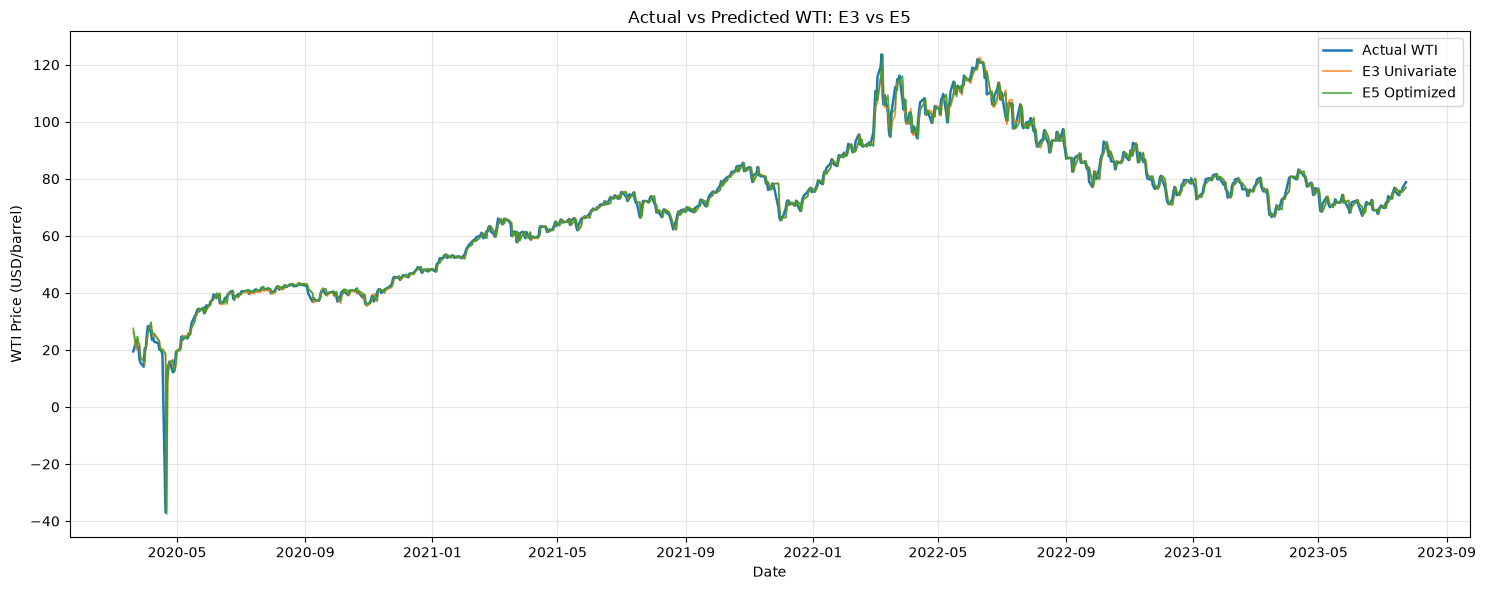

In [96]:
import matplotlib.pyplot as plt

# Ngày tháng và giá WTI thực tế
test_dates = data_uni_model["Date"].iloc[-len(X_test_uni):]
actual_wti = data_uni_model["wti"].iloc[-len(X_test_uni):]

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    actual_wti.values,
    label="Actual WTI",
    linewidth=1.8
)

plt.plot(
    test_dates,
    y_pred_price_uni,
    label="E3 Univariate",
    linewidth=1.2,
    alpha=0.85
)

plt.plot(
    test_dates,
    y_pred_price,
    label="E5 Optimized",
    linewidth=1.2,
    alpha=0.85
)

plt.title("Actual vs Predicted WTI: E3 vs E5")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [97]:
# Đánh giá E3 Univariate
results_e3 = evaluate_model(
    actual_wti.values,
    y_pred_price_uni,
    previous_price_uni
)

# Đánh giá E5 Optimized
results_e5 = evaluate_model(
    actual_wti.values,
    y_pred_price,
    previous_price_uni
)

comparison = pd.DataFrame({
    "E3 Univariate": results_e3,
    "E5 Optimized": results_e5
})

print(comparison.round(4))

        E3 Univariate  E5 Optimized
MAE            1.5856        1.5927
RMSE           3.2267        3.2566
R2             0.9811        0.9808
DA (%)        48.8677       46.8415


In [98]:
# Tạo bảng sai số của hai mô hình
error_comparison = pd.DataFrame({
    "Date": test_dates.values,
    "Actual": actual_wti.values,
    "E3_Predicted": y_pred_price_uni,
    "E5_Predicted": y_pred_price
})

# Tính sai số
error_comparison["E3_Error"] = (
    error_comparison["Actual"] -
    error_comparison["E3_Predicted"]
)

error_comparison["E5_Error"] = (
    error_comparison["Actual"] -
    error_comparison["E5_Predicted"]
)

# Sai số tuyệt đối
error_comparison["E3_Abs_Error"] = abs(
    error_comparison["E3_Error"]
)

error_comparison["E5_Abs_Error"] = abs(
    error_comparison["E5_Error"]
)

print(error_comparison.head())

        Date  Actual  E3_Predicted  E5_Predicted  E3_Error  E5_Error  \
0 2020-03-20   19.48     26.269162     27.551480 -6.789162 -8.071480   
1 2020-03-23   23.33     19.870182     21.169659  3.459818  2.160341   
2 2020-03-24   21.03     24.111445     24.754177 -3.081445 -3.724177   
3 2020-03-25   20.75     21.573004     22.683878 -0.823004 -1.933878   
4 2020-03-26   16.60     21.382472     22.050445 -4.782472 -5.450445   

   E3_Abs_Error  E5_Abs_Error  
0      6.789162      8.071480  
1      3.459818      2.160341  
2      3.081445      3.724177  
3      0.823004      1.933878  
4      4.782472      5.450445  


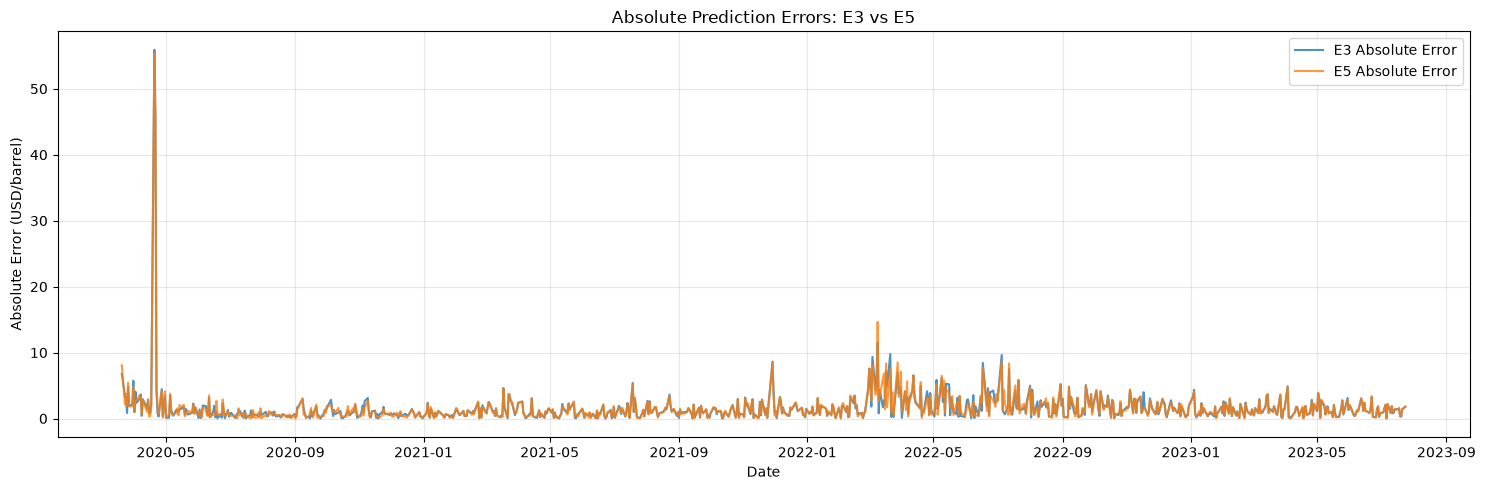

In [99]:
plt.figure(figsize=(15, 5))

plt.plot(
    error_comparison["Date"],
    error_comparison["E3_Abs_Error"],
    label="E3 Absolute Error",
    alpha=0.8
)

plt.plot(
    error_comparison["Date"],
    error_comparison["E5_Abs_Error"],
    label="E5 Absolute Error",
    alpha=0.8
)

plt.title("Absolute Prediction Errors: E3 vs E5")
plt.xlabel("Date")
plt.ylabel("Absolute Error (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [100]:
# So sánh sai số tuyệt đối tại từng quan sát
e3_better = (
    error_comparison["E3_Abs_Error"] <
    error_comparison["E5_Abs_Error"]
).sum()

e5_better = (
    error_comparison["E5_Abs_Error"] <
    error_comparison["E3_Abs_Error"]
).sum()

equal = (
    error_comparison["E3_Abs_Error"] ==
    error_comparison["E5_Abs_Error"]
).sum()

print("E3 has lower error:", e3_better)
print("E5 has lower error:", e5_better)
print("Equal error:", equal)

print("\nPercentage:")
print("E3:", e3_better / len(error_comparison) * 100)
print("E5:", e5_better / len(error_comparison) * 100)

E3 has lower error: 415
E5 has lower error: 424
Equal error: 0

Percentage:
E3: 49.463647199046484
E5: 50.53635280095352


In [101]:
# Sai số lớn nhất của E3
print("Top 10 E3 errors:")
print(
    error_comparison.nlargest(
        10, "E3_Abs_Error"
    )[
        ["Date", "Actual", "E3_Predicted", "E3_Abs_Error"]
    ].to_string(index=False)
)

# Sai số lớn nhất của E5
print("\nTop 10 E5 errors:")
print(
    error_comparison.nlargest(
        10, "E5_Abs_Error"
    )[
        ["Date", "Actual", "E5_Predicted", "E5_Abs_Error"]
    ].to_string(index=False)
)

Top 10 E3 errors:
      Date  Actual  E3_Predicted  E3_Abs_Error
2020-04-20  -36.98     18.938732     55.918732
2020-04-21    8.91    -36.351268     45.261268
2022-03-09  108.81    120.299539     11.489539
2022-03-21  112.14    102.364658      9.775342
2022-07-05  101.55    111.180319      9.630319
2022-03-04  115.77    106.419386      9.350614
2021-11-29   69.88     78.518342      8.638342
2022-06-17  109.56    118.005244      8.445244
2022-03-01  103.66     96.075953      7.584047
2022-07-12   97.69    105.205399      7.515399

Top 10 E5 errors:
      Date  Actual  E5_Predicted  E5_Abs_Error
2020-04-20  -36.98     18.388577     55.368577
2020-04-21    8.91    -37.509183     46.419183
2022-03-09  108.81    123.483292     14.673292
2022-07-05  101.55    110.190488      8.640488
2022-03-28  107.55    116.068175      8.518175
2021-11-29   69.88     78.315249      8.435249
2022-07-12   97.69    106.057098      8.367098
2022-03-17  102.97     94.615230      8.354770
2022-03-04  115.77    1

In [102]:
# Tạo tập dữ liệu loại riêng hai ngày cực đoan
# Chỉ dùng cho phân tích độ nhạy, không thay thế kết quả chính

normal_period = error_comparison[
    ~error_comparison["Date"].isin(
        pd.to_datetime(["2020-04-20", "2020-04-21"])
    )
]

print("Original observations:", len(error_comparison))
print("After excluding two extreme dates:", len(normal_period))

print("\nMAE comparison excluding extreme dates:")

print("E3 MAE:",
      normal_period["E3_Abs_Error"].mean())

print("E5 MAE:",
      normal_period["E5_Abs_Error"].mean())

print("\nRMSE comparison excluding extreme dates:")

print("E3 RMSE:",
      np.sqrt(np.mean(normal_period["E3_Error"] ** 2)))

print("E5 RMSE:",
      np.sqrt(np.mean(normal_period["E5_Error"] ** 2)))

Original observations: 839
After excluding two extreme dates: 837

MAE comparison excluding extreme dates:
E3 MAE: 1.4684550596628643
E5 MAE: 1.4749431717622548

RMSE comparison excluding extreme dates:
E3 RMSE: 2.0623271568937778
E5 RMSE: 2.0961660813090814


In [103]:
from scipy.stats import t

# Sai số dự báo của hai mô hình
e3_error = error_comparison["E3_Error"].values
e5_error = error_comparison["E5_Error"].values

# Chênh lệch bình phương sai số
loss_diff = e3_error**2 - e5_error**2

n = len(loss_diff)

# DM statistic với giả định đơn giản: không có tự tương quan
dm_stat = loss_diff.mean() / (
    loss_diff.std(ddof=1) / np.sqrt(n)
)

# P-value hai phía
p_value = 2 * t.sf(abs(dm_stat), df=n-1)

print("DM statistic:", dm_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("No statistically significant difference.")

DM statistic: -0.8794064594111856
P-value: 0.3794330304069784
No statistically significant difference.


In [104]:
import statsmodels.api as sm
import numpy as np

# Chênh lệch bình phương sai số: E3 - E5
loss_diff = (
    error_comparison["E3_Error"].values**2
    - error_comparison["E5_Error"].values**2
)

X_constant = np.ones((len(loss_diff), 1))

for lag in [1, 5, 10, 20]:
    model_hac = sm.OLS(
        loss_diff,
        X_constant
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    print(
        f"Lag {lag}: "
        f"Statistic = {model_hac.tvalues[0]:.4f}, "
        f"P-value = {model_hac.pvalues[0]:.4f}"
    )

Lag 1: Statistic = -0.9703, P-value = 0.3319
Lag 5: Statistic = -1.0938, P-value = 0.2741
Lag 10: Statistic = -1.1424, P-value = 0.2533
Lag 20: Statistic = -1.0911, P-value = 0.2752


In [105]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [106]:
import statsmodels.api as sm

print("statsmodels version:", sm.__version__)

statsmodels version: 0.15.0


In [107]:
import statsmodels.api as sm
import numpy as np

# Chênh lệch bình phương sai số: E3 - E5
loss_diff = (
    error_comparison["E3_Error"].values**2
    - error_comparison["E5_Error"].values**2
)

X_constant = np.ones((len(loss_diff), 1))

for lag in [1, 5, 10, 20]:
    model_hac = sm.OLS(
        loss_diff,
        X_constant
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    print(
        f"Lag {lag}: "
        f"Statistic = {model_hac.tvalues[0]:.4f}, "
        f"P-value = {model_hac.pvalues[0]:.4f}"
    )

Lag 1: Statistic = -0.9703, P-value = 0.3319
Lag 5: Statistic = -1.0938, P-value = 0.2741
Lag 10: Statistic = -1.1424, P-value = 0.2533
Lag 20: Statistic = -1.0911, P-value = 0.2752


In [108]:
# Thống kê mô tả giá dầu WTI
wti_stats = data_multi_model["wti"].describe()

print("WTI Descriptive Statistics:")
print(wti_stats)

print("\nSkewness:", data_multi_model["wti"].skew())
print("Kurtosis:", data_multi_model["wti"].kurtosis())

WTI Descriptive Statistics:
count    2473.000000
mean       64.054367
std        21.315708
min       -36.980000
25%        48.340000
50%        59.300000
75%        76.830000
max       123.640000
Name: wti, dtype: float64

Skewness: 0.4906695052272569
Kurtosis: -0.2570102100693043


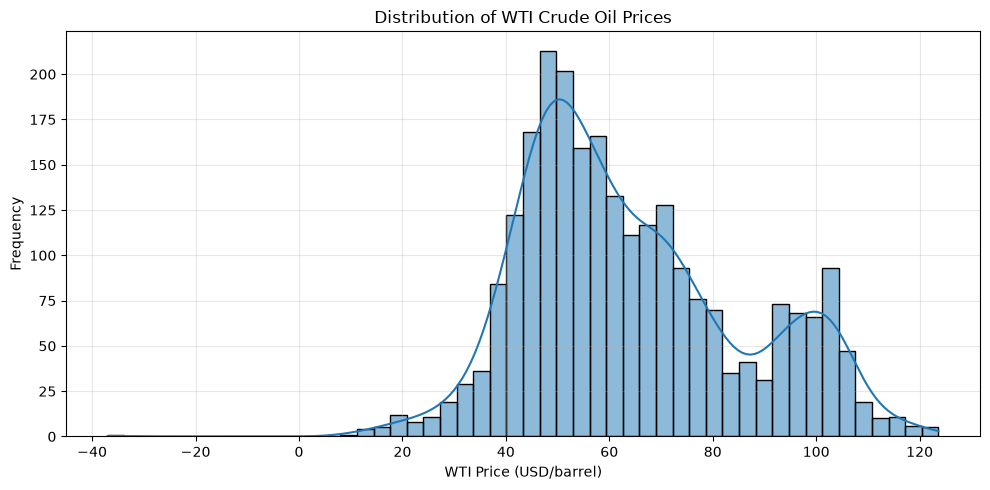

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data_multi_model["wti"],
    bins=50,
    kde=True
)

plt.title("Distribution of WTI Crude Oil Prices")
plt.xlabel("WTI Price (USD/barrel)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

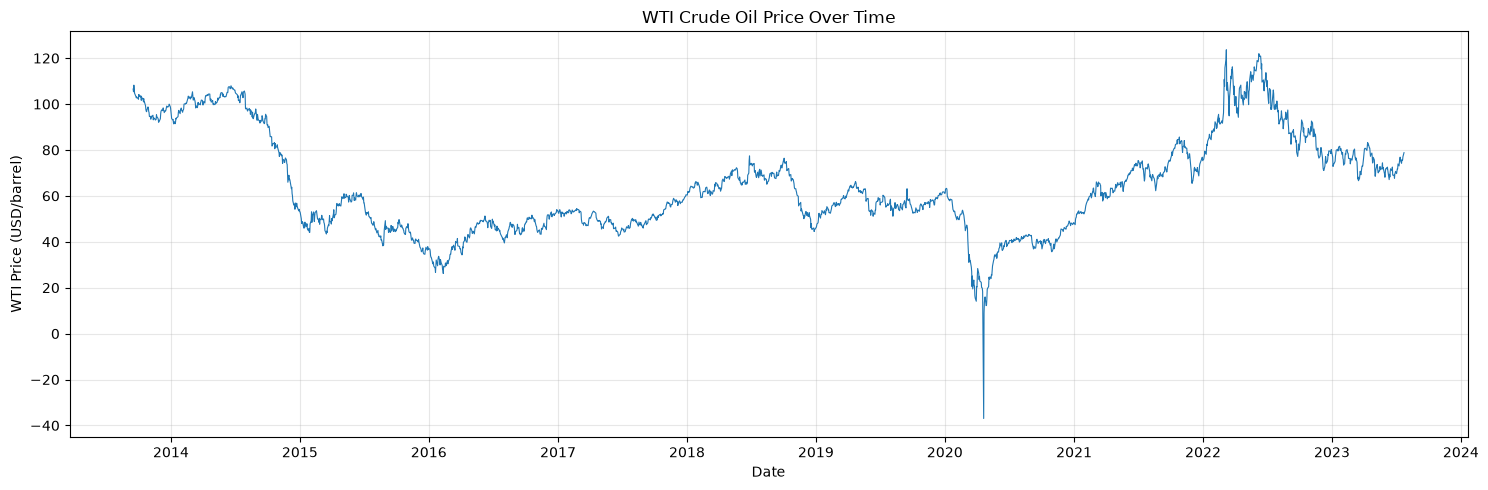

In [110]:
plt.figure(figsize=(15, 5))

plt.plot(
    data_multi_model["Date"],
    data_multi_model["wti"],
    linewidth=0.8
)

plt.title("WTI Crude Oil Price Over Time")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [111]:
# Sắp xếp dữ liệu theo thời gian
eda_data = data_multi_model.sort_values("Date").copy()

# Sử dụng đúng cách tính WTI_Change như XGBoost
eda_data["WTI_Change"] = (
    eda_data["wti"] - eda_data["wti_Lag1"]
)

# Phần trăm thay đổi (chỉ dùng tham khảo)
eda_data["WTI_Pct_Change"] = (
    (eda_data["wti"] / eda_data["wti_Lag1"] - 1) * 100
)

print(eda_data[[
    "Date", "wti", "WTI_Change", "WTI_Pct_Change"
]].head(10))

        Date     wti  WTI_Change  WTI_Pct_Change
0 2013-09-16  106.54       -1.77       -1.634198
1 2013-09-17  105.36       -1.18       -1.107565
2 2013-09-18  108.23        2.87        2.723994
3 2013-09-19  106.26       -1.97       -1.820198
4 2013-09-20  104.70       -1.56       -1.468097
5 2013-09-23  103.62       -1.08       -1.031519
6 2013-09-24  103.22       -0.40       -0.386026
7 2013-09-25  102.68       -0.54       -0.523154
8 2013-09-26  103.10        0.42        0.409038
9 2013-09-27  102.86       -0.24       -0.232784


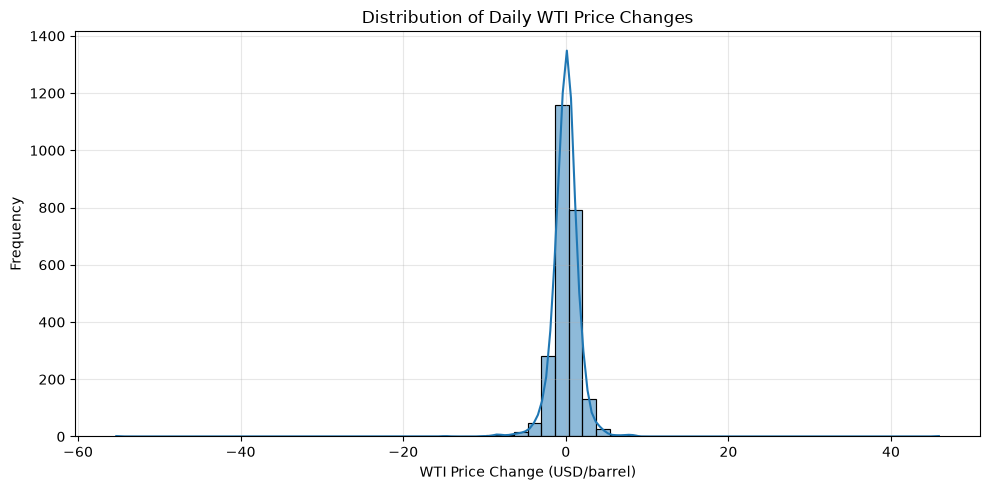

In [112]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_data["WTI_Change"].dropna(),
    bins=60,
    kde=True
)

plt.title("Distribution of Daily WTI Price Changes")
plt.xlabel("WTI Price Change (USD/barrel)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

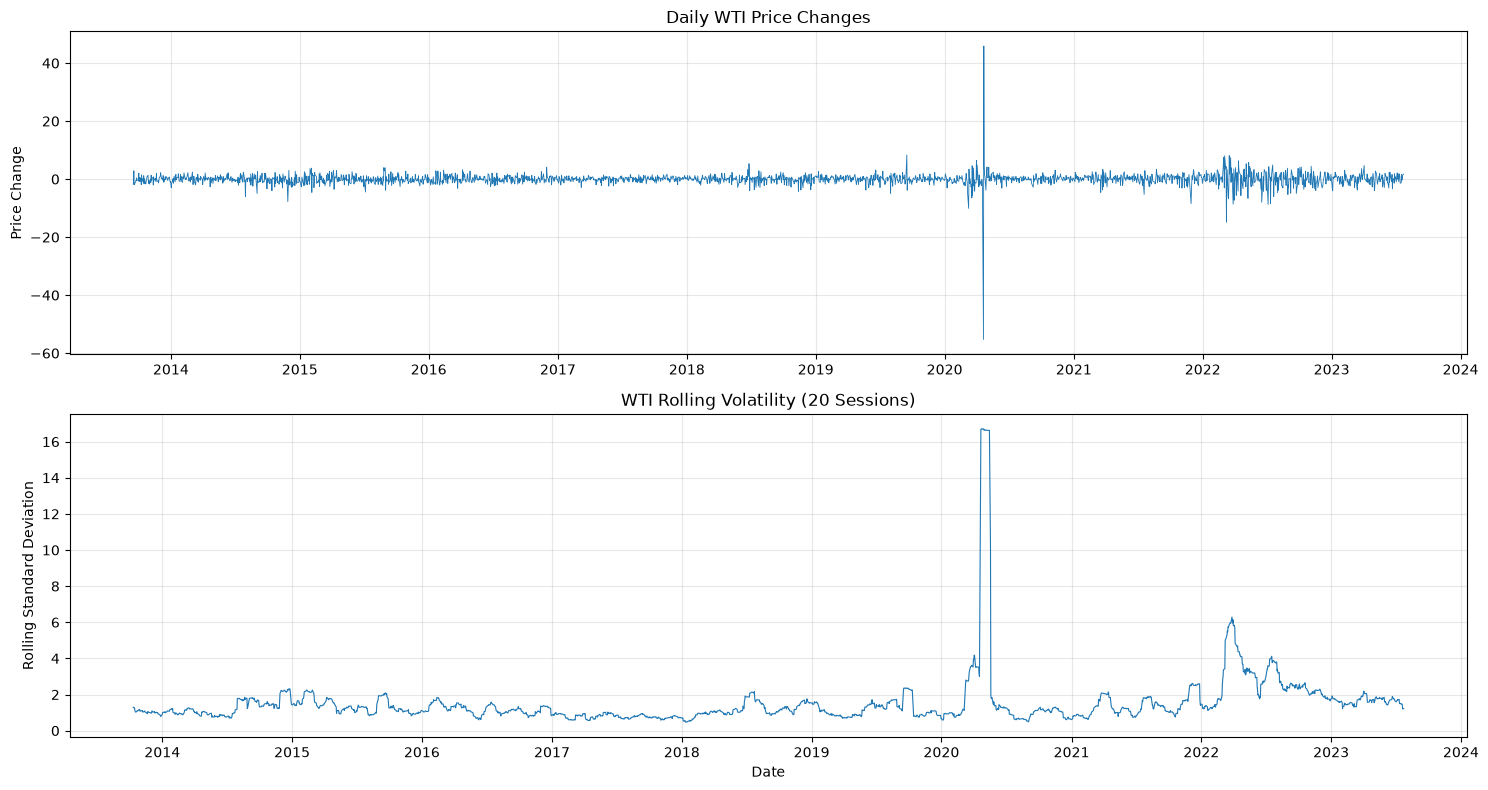

In [113]:
# Độ lệch chuẩn cuốn chiếu 20 phiên
eda_data["Rolling_Volatility_20"] = (
    eda_data["WTI_Change"].rolling(20).std()
)

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    eda_data["Date"],
    eda_data["WTI_Change"],
    linewidth=0.6
)
axes[0].set_title("Daily WTI Price Changes")
axes[0].set_ylabel("Price Change")
axes[0].grid(alpha=0.3)

axes[1].plot(
    eda_data["Date"],
    eda_data["Rolling_Volatility_20"],
    linewidth=0.8
)
axes[1].set_title("WTI Rolling Volatility (20 Sessions)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Rolling Standard Deviation")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [114]:
from statsmodels.tsa.stattools import adfuller, kpss

# Lấy chuỗi giá WTI và mức thay đổi giá
wti_price = eda_data["wti"].dropna()
wti_change = eda_data["WTI_Change"].dropna()

def stationarity_test(series, name):
    print(f"\n===== {name} =====")

    # ADF Test
    adf_result = adfuller(series, autolag="AIC")

    print("ADF Statistic:", round(adf_result[0], 4))
    print("ADF P-value:", round(adf_result[1], 6))

    # KPSS Test
    kpss_result = kpss(
        series,
        regression="c",
        nlags="auto"
    )

    print("KPSS Statistic:", round(kpss_result[0], 4))
    print("KPSS P-value:", round(kpss_result[1], 6))


# Kiểm tra chuỗi giá
stationarity_test(wti_price, "WTI Price")

# Kiểm tra chuỗi thay đổi giá
stationarity_test(wti_change, "WTI Price Change")


===== WTI Price =====
ADF Statistic: -2.3457
ADF P-value: 0.157645
KPSS Statistic: 1.0438
KPSS P-value: 0.01

===== WTI Price Change =====


C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever i

ADF Statistic: -11.2045
ADF P-value: 0.0
KPSS Statistic: 0.2313
KPSS P-value: 0.1


C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series, autolag="AIC")
C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\admin\AppData\Local\Temp\ipykernel_24828\1993000085.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever i

In [115]:
from statsmodels.stats.diagnostic import het_arch

# Lấy chuỗi thay đổi giá WTI
wti_change_clean = eda_data["WTI_Change"].dropna()

# ARCH-LM Test
arch_result = het_arch(
    wti_change_clean,
    nlags=10
)

lm_stat, lm_pvalue, f_stat, f_pvalue = arch_result

print("ARCH-LM Statistic:", lm_stat)
print("ARCH-LM P-value:", lm_pvalue)
print("F Statistic:", f_stat)
print("F P-value:", f_pvalue)

ARCH-LM Statistic: 766.6436950373279
ARCH-LM P-value: 3.0480605131504794e-158
F Statistic: 110.81459329812745
F P-value: 2.5439672946665294e-190


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


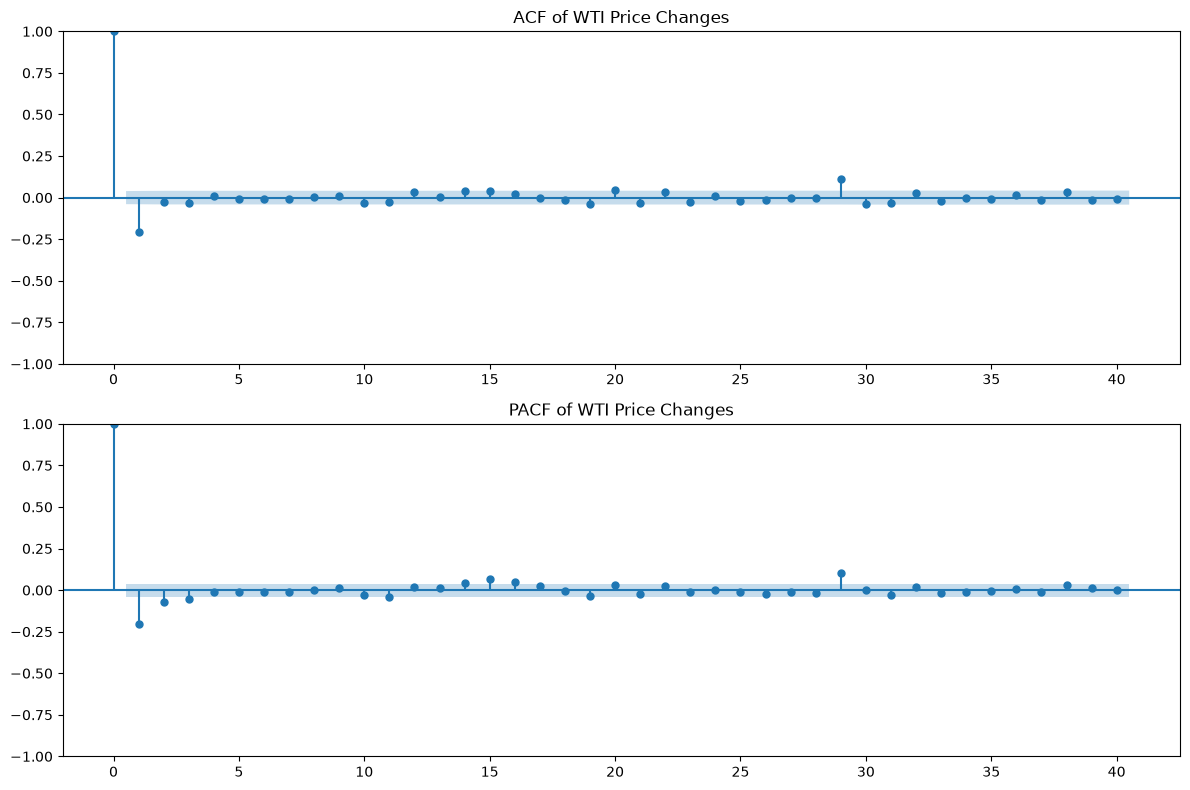

In [116]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# ACF của mức thay đổi giá
plot_acf(
    wti_change_clean,
    lags=40,
    ax=axes[0]
)

axes[0].set_title("ACF of WTI Price Changes")

# PACF của mức thay đổi giá
plot_pacf(
    wti_change_clean,
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF of WTI Price Changes")

plt.tight_layout()
plt.show()

<Figure size 1200x400 with 0 Axes>

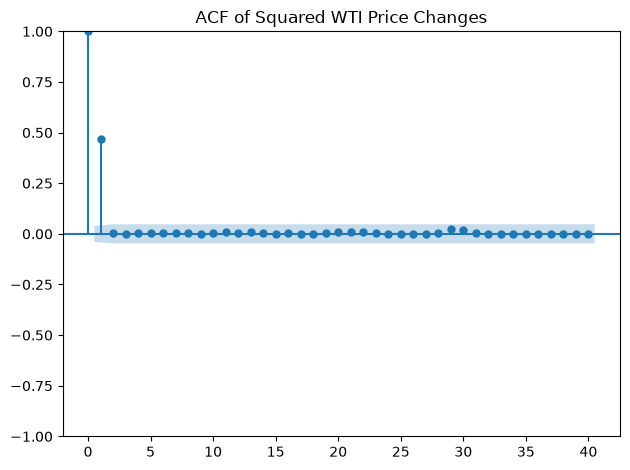

In [117]:
# Bình phương mức thay đổi giá
wti_change_squared = wti_change_clean ** 2

plt.figure(figsize=(12, 4))

plot_acf(
    wti_change_squared,
    lags=40
)

plt.title("ACF of Squared WTI Price Changes")
plt.tight_layout()
plt.show()

In [118]:
%pip install arch

Note: you may need to restart the kernel to use updated packages.


In [119]:
from arch import arch_model

# Sử dụng mức thay đổi giá WTI
# Nhân 100 để đưa dữ liệu về thang đo thuận tiện hơn
wti_returns = wti_change_clean * 100

# GARCH(1,1), giả định phân phối Student-t
garch_model = arch_model(
    wti_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_result = garch_model.fit(
    update_freq=0,
    disp="off"
)

print(garch_result.summary())

                              AR - GARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.006
Mean Model:                              AR   Adj. R-squared:                  0.006
Vol Model:                            GARCH   Log-Likelihood:               -15630.8
Distribution:      Standardized Student's t   AIC:                           31273.6
Method:                  Maximum Likelihood   BIC:                           31308.5
                                              No. Observations:                 2472
Date:                      Sun, Nov 22 2026   Df Residuals:                     2470
Time:                              19:14:13   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\arch\univariate\base.py:1134: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 4.419e+04. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [120]:
from arch import arch_model

# Điều chỉnh thang đo
wti_returns_scaled = wti_change_clean * 10

# Xây dựng AR(1)-GARCH(1,1)
garch_model_scaled = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

# Huấn luyện mô hình
garch_result_scaled = garch_model_scaled.fit(
    update_freq=0,
    disp="off"
)

print(garch_result_scaled.summary())

                              AR - GARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.006
Mean Model:                              AR   Adj. R-squared:                  0.006
Vol Model:                            GARCH   Log-Likelihood:               -9938.79
Distribution:      Standardized Student's t   AIC:                           19889.6
Method:                  Maximum Likelihood   BIC:                           19924.5
                                              No. Observations:                 2472
Date:                      Sun, Nov 22 2026   Df Residuals:                     2470
Time:                              19:14:13   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [121]:
# Lấy phần dư chuẩn hóa
standardized_resid = garch_result_scaled.std_resid.dropna()

# Kiểm tra ARCH-LM trên phần dư chuẩn hóa
arch_resid_test = het_arch(
    standardized_resid,
    nlags=10
)

print("ARCH-LM Statistic:", arch_resid_test[0])
print("ARCH-LM P-value:", arch_resid_test[1])

ARCH-LM Statistic: 0.21823357654096798
ARCH-LM P-value: 0.9999998822834419


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


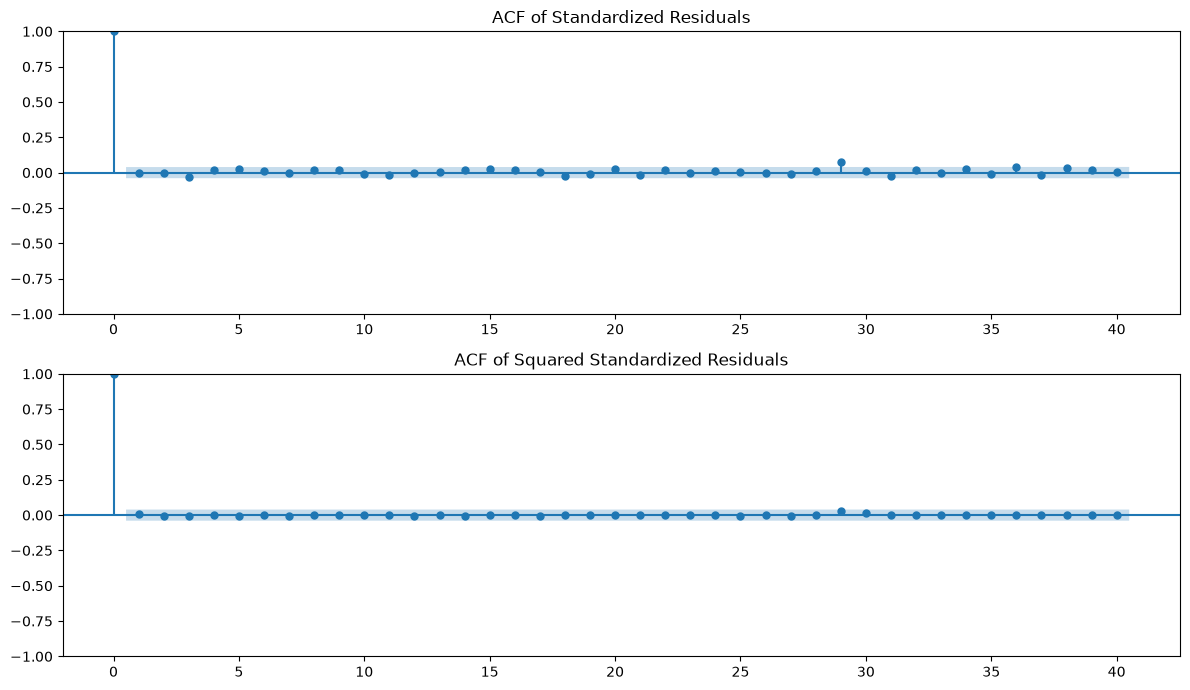

In [122]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(
    standardized_resid,
    lags=40,
    ax=axes[0]
)
axes[0].set_title("ACF of Standardized Residuals")

plot_acf(
    standardized_resid ** 2,
    lags=40,
    ax=axes[1]
)
axes[1].set_title("ACF of Squared Standardized Residuals")

plt.tight_layout()
plt.show()

In [123]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Kiểm tra tự tương quan phần dư chuẩn hóa
lb_residual = acorr_ljungbox(
    standardized_resid,
    lags=[10, 20],
    return_df=True
)

# Kiểm tra tự tương quan bình phương phần dư
lb_squared = acorr_ljungbox(
    standardized_resid ** 2,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box Test - Standardized Residuals")
print(lb_residual)

print("\nLjung-Box Test - Squared Standardized Residuals")
print(lb_squared)

Ljung-Box Test - Standardized Residuals
      lb_stat  lb_pvalue
10   7.161202   0.710144
20  15.147994   0.767878

Ljung-Box Test - Squared Standardized Residuals
     lb_stat  lb_pvalue
10  0.220047        1.0
20  0.354839        1.0


In [124]:
# GJR-GARCH(1,1) với phân phối Student-t
gjr_model = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

gjr_result = gjr_model.fit(
    update_freq=0,
    disp="off"
)

print(gjr_result.summary())

                            AR - GJR-GARCH Model Results                            
Dep. Variable:                   WTI_Change   R-squared:                       0.006
Mean Model:                              AR   Adj. R-squared:                  0.005
Vol Model:                        GJR-GARCH   Log-Likelihood:               -9937.95
Distribution:      Standardized Student's t   AIC:                           19889.9
Method:                  Maximum Likelihood   BIC:                           19930.6
                                              No. Observations:                 2472
Date:                      Sun, Nov 22 2026   Df Residuals:                     2470
Time:                              19:14:14   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

In [125]:
# EGARCH(1,1) với phân phối Student-t
egarch_model = arch_model(
    wti_returns_scaled,
    mean="AR",
    lags=1,
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_result = egarch_model.fit(
    update_freq=0,
    disp="off"
)

print(egarch_result.summary())

                             AR - EGARCH Model Results                              
Dep. Variable:                   WTI_Change   R-squared:                       0.003
Mean Model:                              AR   Adj. R-squared:                  0.003
Vol Model:                           EGARCH   Log-Likelihood:               -9925.58
Distribution:      Standardized Student's t   AIC:                           19865.2
Method:                  Maximum Likelihood   BIC:                           19905.8
                                              No. Observations:                 2472
Date:                      Sun, Nov 22 2026   Df Residuals:                     2470
Time:                              19:14:14   Df Model:                            2
                                    Mean Model                                   
                     coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------

In [126]:
# Lấy phần dư chuẩn hóa của EGARCH
egarch_resid = egarch_result.std_resid.dropna()

# ARCH-LM Test
egarch_arch_test = het_arch(
    egarch_resid,
    nlags=10
)

print("EGARCH ARCH-LM Statistic:", egarch_arch_test[0])
print("EGARCH ARCH-LM P-value:", egarch_arch_test[1])

# Ljung-Box Test
egarch_lb = acorr_ljungbox(
    egarch_resid,
    lags=[10, 20],
    return_df=True
)

egarch_lb_squared = acorr_ljungbox(
    egarch_resid ** 2,
    lags=[10, 20],
    return_df=True
)

print("\nLjung-Box - Standardized Residuals")
print(egarch_lb)

print("\nLjung-Box - Squared Standardized Residuals")
print(egarch_lb_squared)

EGARCH ARCH-LM Statistic: 0.30216437120040984
EGARCH ARCH-LM P-value: 0.9999994214968124

Ljung-Box - Standardized Residuals
      lb_stat  lb_pvalue
10   8.086902   0.620349
20  17.233190   0.637784

Ljung-Box - Squared Standardized Residuals
     lb_stat  lb_pvalue
10  0.306099   0.999999
20  0.504763   1.000000


C:\Users\admin\Energy_Forecasting_XAI\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [127]:
# Chuẩn bị chuỗi thay đổi giá theo thời gian
garch_data = eda_data[
    ["Date", "WTI_Change"]
].dropna().copy()

garch_data["Date"] = pd.to_datetime(garch_data["Date"])

garch_data = (
    garch_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Chia theo cùng ngày Test với XGBoost
garch_split_date = pd.Timestamp("2020-03-20")

split_idx = garch_data["Date"].searchsorted(
    garch_split_date
)

# Tách Train và Test
garch_train = garch_data.iloc[:split_idx].copy()
garch_test = garch_data.iloc[split_idx:].copy()

# Nhân 10 để điều chỉnh thang đo
train_returns = garch_train["WTI_Change"] * 10
test_returns = garch_test["WTI_Change"] * 10

# Kiểm tra kết quả
print("Train observations:", len(train_returns))
print("Test observations:", len(test_returns))

print("\nTrain period:")
print(garch_train["Date"].min(), "to", garch_train["Date"].max())

print("\nTest period:")
print(garch_test["Date"].min(), "to", garch_test["Date"].max())

assert garch_test["Date"].min() == garch_split_date

Train observations: 1634
Test observations: 839

Train period:
2013-09-16 00:00:00 to 2020-03-19 00:00:00

Test period:
2020-03-20 00:00:00 to 2023-07-24 00:00:00


In [128]:
# Kiểm tra ngày Test giữa XGBoost và GARCH
split_date = pd.Timestamp("2020-03-20")

xgb_test_dates = (
    data_multi_model.loc[
        data_multi_model["Date"] >= split_date, "Date"
    ]
    .reset_index(drop=True)
)

garch_test_dates = (
    garch_data.loc[
        garch_data["Date"] >= split_date, "Date"
    ]
    .reset_index(drop=True)
)

print("Số ngày Test XGBoost:", len(xgb_test_dates))
print("Số ngày Test GARCH:", len(garch_test_dates))
print("Ngày Test khớp hoàn toàn:",
      xgb_test_dates.equals(garch_test_dates))

Số ngày Test XGBoost: 839
Số ngày Test GARCH: 839
Ngày Test khớp hoàn toàn: True


In [129]:
from arch import arch_model
import pandas as pd
import numpy as np

# Ghép chuỗi Train và Test, giữ đúng thứ tự thời gian
all_returns = garch_data["WTI_Change"].reset_index(drop=True) * 10

# Xây dựng EGARCH trên toàn bộ chuỗi,
# nhưng chỉ ước lượng tham số đến hết Train
egarch_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

egarch_oos_result = egarch_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

# Dự báo phương sai một bước trước trên Test
egarch_forecast = egarch_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

# Lấy phương sai dự báo tại 839 ngày Test
egarch_test_variance = (
    egarch_forecast.variance["h.1"]
    .iloc[split_idx:]
)

# Chuyển từ thang đo nhân 10 về đơn vị gốc
egarch_test_variance = egarch_test_variance / 100

# Độ lệch chuẩn có điều kiện
egarch_test_volatility = np.sqrt(
    egarch_test_variance
)

print("Number of forecasts:", egarch_test_volatility.notna().sum())
print("\nFirst 5 forecasts:")
print(egarch_test_volatility.dropna().head())

Number of forecasts: 839

First 5 forecasts:
1634    2.556397
1635    2.787696
1636    2.720548
1637    2.741136
1638    2.655782
Name: h.1, dtype: float64


In [130]:
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Lấy 839 giá trị thực tế và 839 giá trị dự báo

# Bình phương biến động thực tế
realized_var = (
    garch_test["WTI_Change"]
    .reset_index(drop=True) ** 2
)

# Phương sai dự báo (đã chuyển về thang đo ban đầu)
forecast_var = (
    egarch_test_variance
    .reset_index(drop=True)
)

# Ghép hai chuỗi theo ngày, loại bỏ giá trị thiếu
evaluation = pd.DataFrame({
    "Realized_Variance": realized_var,
    "Forecast_Variance": forecast_var
}).dropna()

# RMSE
rmse_var = np.sqrt(mean_squared_error(
    evaluation["Realized_Variance"],
    evaluation["Forecast_Variance"]
))

# QLIKE
epsilon = 1e-10

qlike = np.mean(
    np.log(evaluation["Forecast_Variance"] + epsilon)
    + evaluation["Realized_Variance"]
    / (evaluation["Forecast_Variance"] + epsilon)
)

print("Số quan sát đánh giá:", len(evaluation))
print("RMSE (Variance):", rmse_var)
print("QLIKE:", qlike)

Số quan sát đánh giá: 839
RMSE (Variance): 127.08626549611702
QLIKE: 3.0194125226677055


In [131]:
from arch import arch_model

all_returns = (
    garch_data["WTI_Change"]
    .reset_index(drop=True) * 10
)

# GARCH(1,1)
garch_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_oos_result = garch_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

# GJR-GARCH(1,1)
gjr_oos_model = arch_model(
    all_returns,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

gjr_oos_result = gjr_oos_model.fit(
    last_obs=split_idx,
    update_freq=0,
    disp="off"
)

print("Đã huấn luyện xong GARCH và GJR-GARCH!")

Đã huấn luyện xong GARCH và GJR-GARCH!


In [132]:
# GARCH forecast
garch_forecast = garch_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

garch_test_variance = (
    garch_forecast.variance["h.1"].iloc[split_idx:] / 100
)

# GJR-GARCH forecast
gjr_forecast = gjr_oos_result.forecast(
    start=split_idx - 1,
    horizon=1,
    align="target",
    reindex=True
)

gjr_test_variance = (
    gjr_forecast.variance["h.1"].iloc[split_idx:] / 100
)

print("GARCH:", garch_test_variance.notna().sum())
print("GJR-GARCH:", gjr_test_variance.notna().sum())

GARCH: 839
GJR-GARCH: 839


In [133]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# Phương sai thực tế
realized_var = (
    garch_test["WTI_Change"]
    .reset_index(drop=True) ** 2
)

# Ghép các dự báo theo thứ tự quan sát
evaluation = pd.DataFrame({
    "Realized_Variance": realized_var,
    "GARCH": garch_test_variance.reset_index(drop=True),
    "GJR-GARCH": gjr_test_variance.reset_index(drop=True),
    "EGARCH": egarch_test_variance.reset_index(drop=True)
}).dropna()

# Hàm tính chỉ số
def evaluate_volatility(actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    epsilon = 1e-10
    qlike = np.mean(
        np.log(predicted + epsilon)
        + actual / (predicted + epsilon)
    )

    return rmse, qlike

# Đánh giá từng mô hình
results = []

for model in ["GARCH", "GJR-GARCH", "EGARCH"]:
    rmse, qlike = evaluate_volatility(
        evaluation["Realized_Variance"],
        evaluation[model]
    )

    results.append({
        "Model": model,
        "RMSE": rmse,
        "QLIKE": qlike
    })

results_df = pd.DataFrame(results)

print("Số quan sát:", len(evaluation))
print(results_df.to_string(index=False))

Số quan sát: 839
    Model       RMSE    QLIKE
    GARCH 127.739016 2.888771
GJR-GARCH 127.158170 2.991107
   EGARCH 127.086265 3.019413


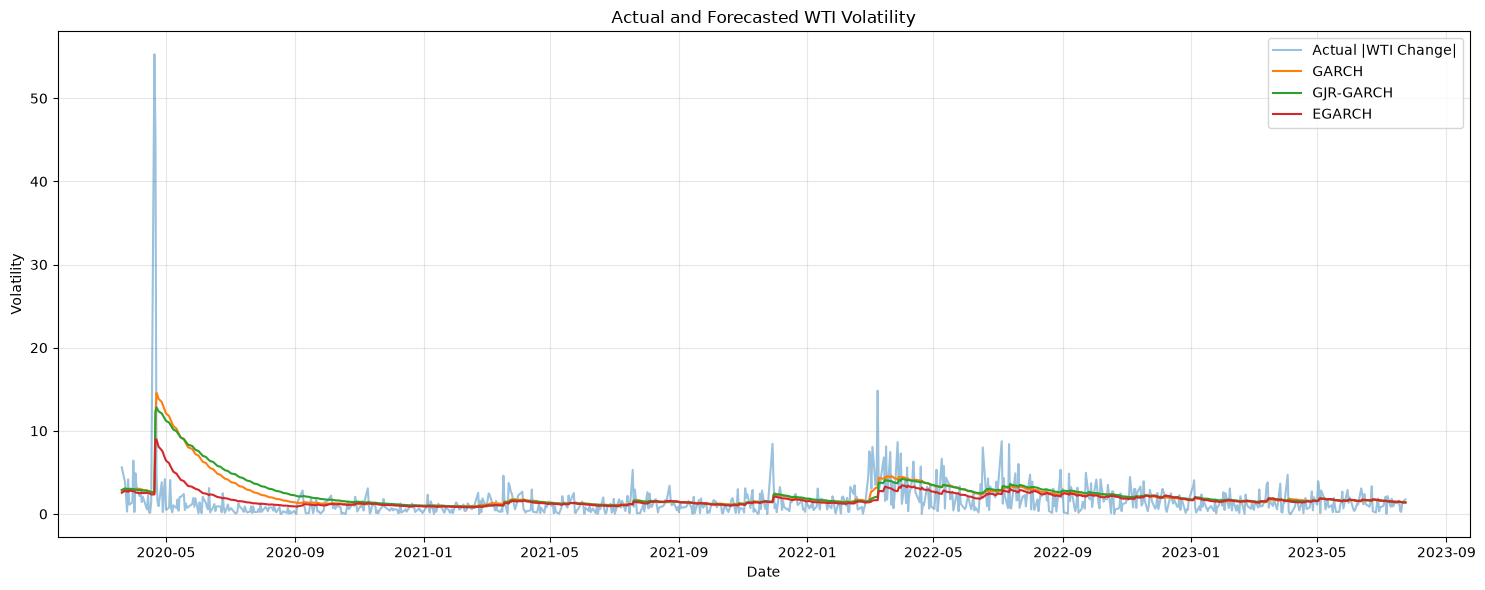

In [134]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_data = pd.DataFrame({
    "Date": garch_test["Date"].reset_index(drop=True),
    "Actual_Volatility": (
        garch_test["WTI_Change"].reset_index(drop=True).abs()
    ),
    "GARCH": np.sqrt(
        garch_test_variance.reset_index(drop=True)
    ),
    "GJR-GARCH": np.sqrt(
        gjr_test_variance.reset_index(drop=True)
    ),
    "EGARCH": np.sqrt(
        egarch_test_variance.reset_index(drop=True)
    )
})

plt.figure(figsize=(15, 6))

plt.plot(
    plot_data["Date"],
    plot_data["Actual_Volatility"],
    label="Actual |WTI Change|",
    alpha=0.45
)

plt.plot(
    plot_data["Date"],
    plot_data["GARCH"],
    label="GARCH"
)

plt.plot(
    plot_data["Date"],
    plot_data["GJR-GARCH"],
    label="GJR-GARCH"
)

plt.plot(
    plot_data["Date"],
    plot_data["EGARCH"],
    label="EGARCH"
)

plt.title("Actual and Forecasted WTI Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [135]:
import numpy as np
import pandas as pd

epsilon = 1e-10

actual_var = evaluation["Realized_Variance"]

# Tính QLIKE loss từng ngày cho từng mô hình
qlike_losses = pd.DataFrame(index=evaluation.index)

for model in ["GARCH", "GJR-GARCH", "EGARCH"]:
    predicted_var = evaluation[model].clip(lower=epsilon)

    qlike_losses[model] = (
        np.log(predicted_var)
        + actual_var / predicted_var
    )

print("QLIKE loss trung bình:")
print(qlike_losses.mean())

QLIKE loss trung bình:
GARCH        2.888771
GJR-GARCH    2.991107
EGARCH       3.019413
dtype: float64


In [136]:
import statsmodels.api as sm
from itertools import combinations

pairs = [
    ("GARCH", "EGARCH"),
    ("GJR-GARCH", "EGARCH"),
    ("GARCH", "GJR-GARCH")
]

dm_results = []

for model_a, model_b in pairs:

    # Chênh lệch QLIKE loss
    loss_diff = (
        qlike_losses[model_a] - qlike_losses[model_b]
    )

    # Kiểm định trung bình bằng OLS + Newey-West HAC
    X = np.ones((len(loss_diff), 1))

    dm_model = sm.OLS(loss_diff.values, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 10}
    )

    dm_results.append({
        "Comparison": f"{model_a} vs {model_b}",
        "Mean_Loss_Diff": loss_diff.mean(),
        "DM_Statistic": dm_model.tvalues[0],
        "P_Value": dm_model.pvalues[0]
    })

dm_results_df = pd.DataFrame(dm_results)

print(dm_results_df.to_string(index=False))

         Comparison  Mean_Loss_Diff  DM_Statistic  P_Value
    GARCH vs EGARCH       -0.130641     -0.800643 0.423338
GJR-GARCH vs EGARCH       -0.028305     -0.180891 0.856453
 GARCH vs GJR-GARCH       -0.102336     -1.538870 0.123836


In [137]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.


In [138]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

In [139]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_multi[features_e5].values,
    feature_names=features_e5,
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

print("Đã khởi tạo LIME Explainer!")

Đã khởi tạo LIME Explainer!


In [140]:
X_test_e5 = X_test_multi[features_e5].copy()

sample_index = 0

sample = X_test_e5.iloc[sample_index].values

def predict_fn(data):
    data_df = pd.DataFrame(
        data,
        columns=features_e5
    )

    return best_model_e5.predict(data_df)

lime_exp = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=predict_fn,
    num_features=10
)

print("Giải thích LIME cho quan sát:", sample_index)
print("Các đặc trưng ảnh hưởng:")
print(lime_exp.as_list())

Giải thích LIME cho quan sát: 0
Các đặc trưng ảnh hưởng:
[('wti_Lag10 <= 48.29', 0.13814501956311379), ('SRV_Lag3 > 0.00', 0.06770878177476458), ('0.00 < SRV_Lag1 <= 0.00', 0.0671059218063544), ('SRV_Lag20 > 0.00', 0.06639781527704267), ('wti_Lag1 <= 48.12', 0.035099220930866745), ('0.43 < TB_Lag20 <= 1.64', 0.03135656697112472), ('EPI_Lag2 > 103.69', 0.024301945389734056), ('0.04 < TB_Lag5 <= 0.48', 0.015991780858739355), ('SRV_Lag5 > 0.00', -0.012203472417151884), ('EPI_Lag20 > 103.04', 0.011602366585960564)]


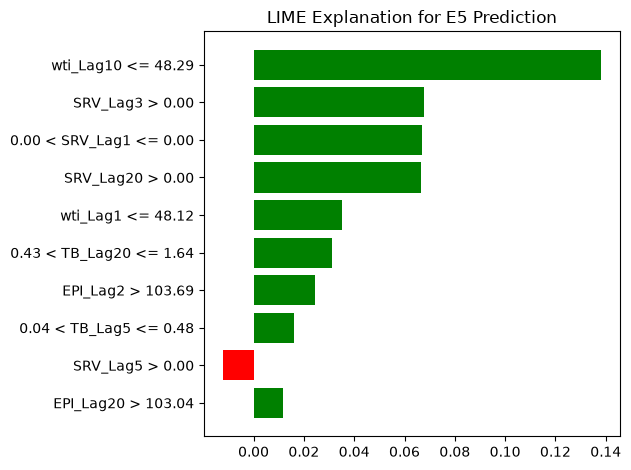

In [141]:
import matplotlib.pyplot as plt

lime_exp.as_pyplot_figure()

plt.title("LIME Explanation for E5 Prediction")
plt.tight_layout()
plt.show()

In [142]:
print("LIME local fidelity score:", lime_exp.score)

print("\nLIME local prediction:")
print(lime_exp.local_pred)

print("\nLIME intercept:")
print(lime_exp.intercept)

print("\nXGBoost prediction:")
print(best_model_e5.predict(
    X_test_e5.iloc[[sample_index]]
))

LIME local fidelity score: 0.1894765637519763

LIME local prediction:
[0.26482449]

LIME intercept:
{0: np.float64(-0.1806814603655265), 1: np.float64(-0.1806814603655265)}

XGBoost prediction:
[2.46148]


In [143]:
lime_exp_2 = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=predict_fn,
    num_features=10,
    num_samples=10000
)

print("Fidelity score:", lime_exp_2.score)
print("LIME prediction:", lime_exp_2.local_pred)

print("XGBoost prediction:",
      best_model_e5.predict(
          X_test_e5.iloc[[sample_index]]
      ))

print("\nCác đặc trưng quan trọng:")
print(lime_exp_2.as_list())

Fidelity score: 0.22765454059347534
LIME prediction: [0.26750297]
XGBoost prediction: [2.46148]

Các đặc trưng quan trọng:
[('wti_Lag10 <= 48.29', 0.14421783059245175), ('0.00 < SRV_Lag1 <= 0.00', 0.07646328889440324), ('SRV_Lag20 > 0.00', 0.06795451015060919), ('SRV_Lag3 > 0.00', 0.06497369230859253), ('EPI_Lag2 > 103.69', 0.03359023876996784), ('wti_Lag1 <= 48.12', 0.030997116965305202), ('0.43 < TB_Lag20 <= 1.64', 0.02217581045138269), ('SRV_Lag5 > 0.00', -0.018908128419728727), ('48.38 < wti_Lag20 <= 55.88', 0.01430668513873635), ('EPI_Lag1 > 103.81', 0.013177473198344919)]


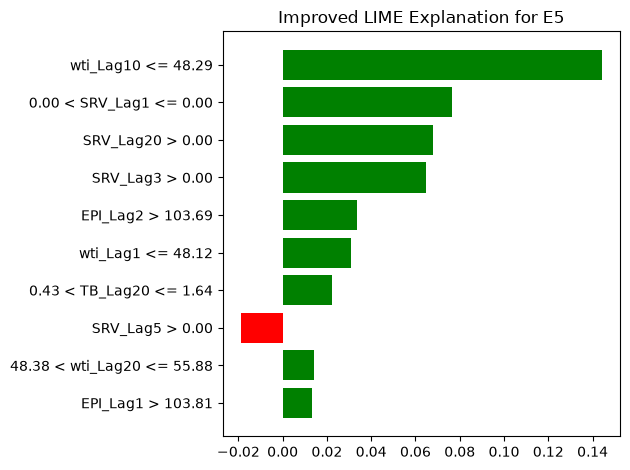

In [144]:
lime_exp_2.as_pyplot_figure()

plt.title("Improved LIME Explanation for E5")
plt.tight_layout()
plt.show()

In [145]:
print("Fidelity score:", lime_exp_2.score)

print("LIME local prediction:",
      lime_exp_2.local_pred)

print("XGBoost prediction:",
      best_model_e5.predict(
          X_test_e5.iloc[[sample_index]]
      ))

Fidelity score: 0.22765454059347534
LIME local prediction: [0.26750297]
XGBoost prediction: [2.46148]


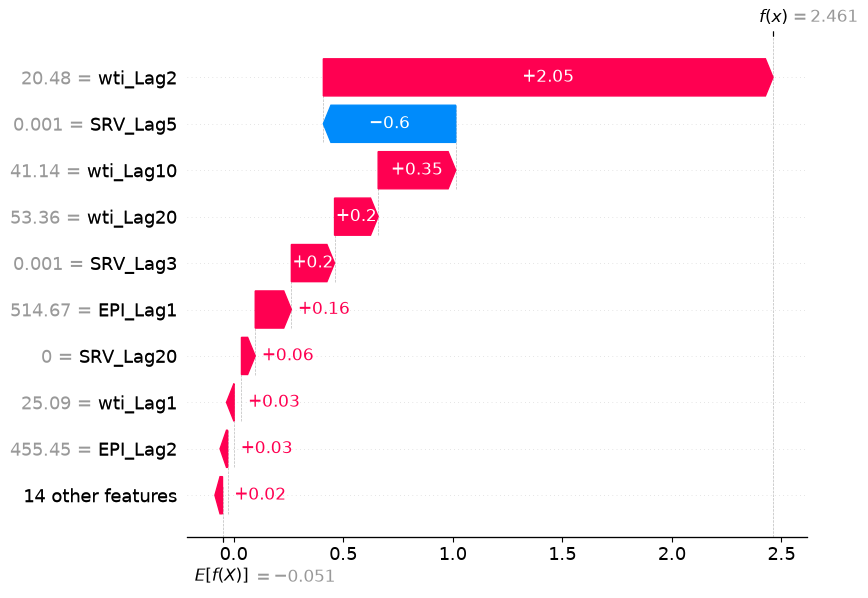

In [146]:
import shap

# Tạo SHAP TreeExplainer cho E5
shap_explainer_e5 = shap.TreeExplainer(best_model_e5)

# Chọn đúng quan sát đã giải thích bằng LIME
sample_df = X_test_e5.iloc[[sample_index]]

# Tính SHAP value
shap_values_local = shap_explainer_e5(
    sample_df
)

# Vẽ Waterfall Plot
shap.plots.waterfall(
    shap_values_local[0],
    max_display=10
)

Đang giải thích quan sát: 0


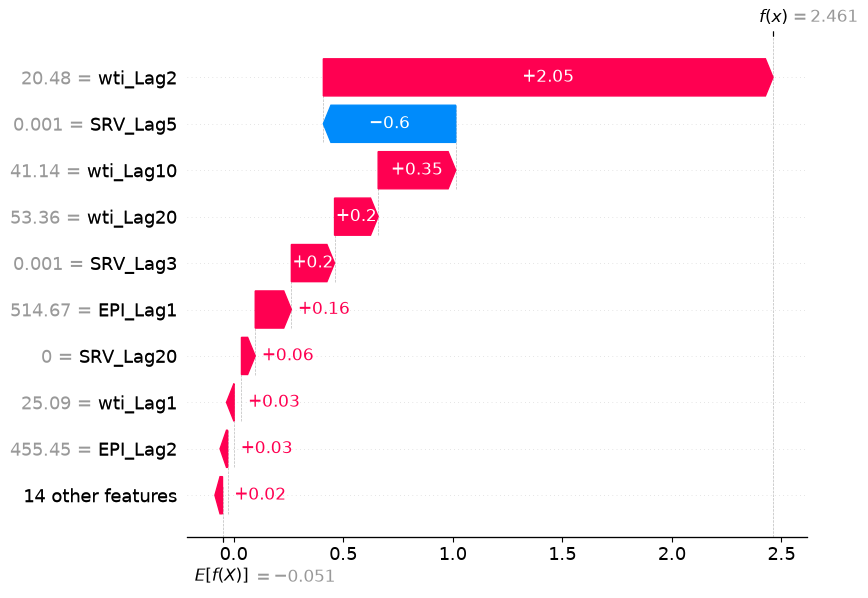

Đang giải thích quan sát: 419


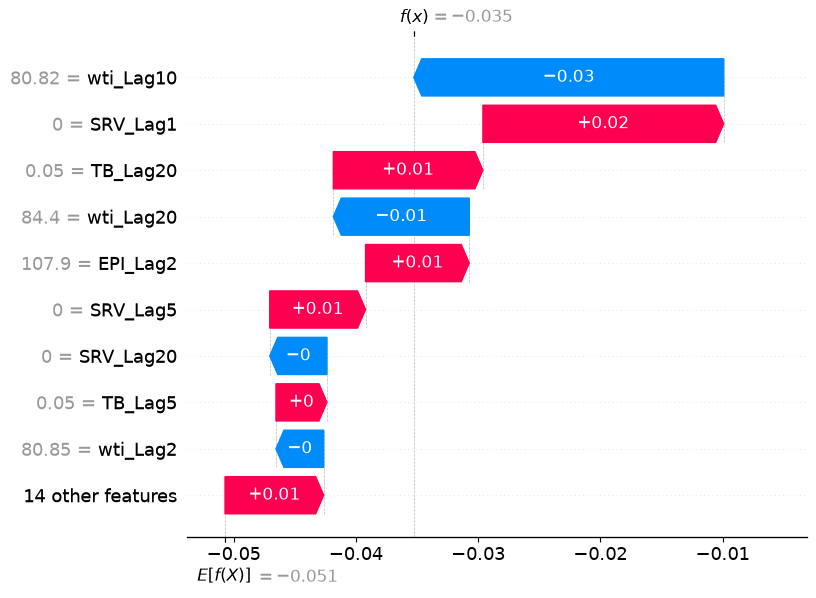

Đang giải thích quan sát: 20


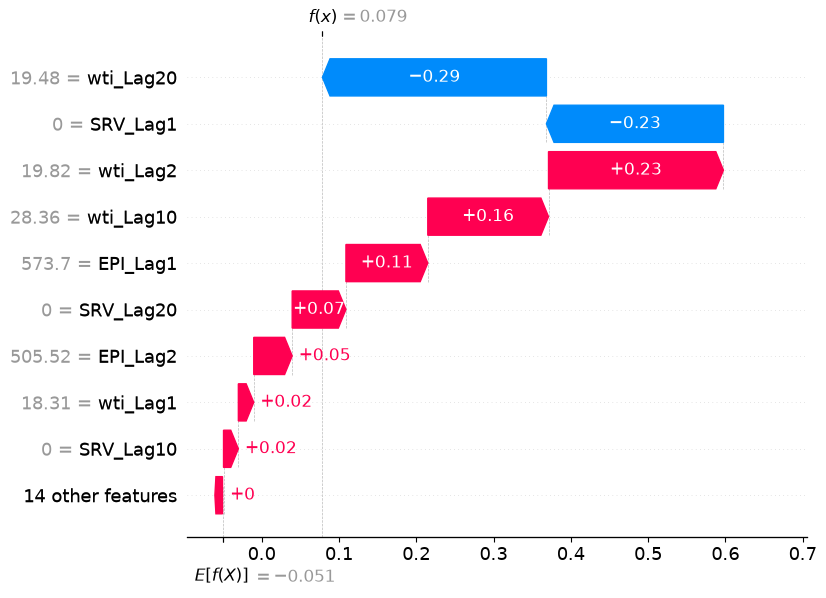

In [147]:
# Chọn 3 thời điểm đại diện
sample_indices = [
    0,
    len(X_test_e5) // 2,
    y_test_change_multi.loc[X_test_e5.index].abs().to_numpy().argmax()
]

for idx in sample_indices:
    print(f"Đang giải thích quan sát: {idx}")

    sample_df = X_test_e5.iloc[[idx]]

    shap_local = shap_explainer_e5(sample_df)

    shap.plots.waterfall(
        shap_local[0],
        max_display=10,
        show=True
    )

In [148]:
actual_changes_e5 = (
    y_test_change_multi.loc[X_test_e5.index].to_numpy()
)

test_dates_e5 = (
    data_multi_model.loc[X_test_e5.index, "Date"]
    .reset_index(drop=True)
)

sample_indices = [
    0,
    len(X_test_e5) // 2,
    int(np.abs(actual_changes_e5).argmax())
]

for idx in sample_indices:

    actual_change = actual_changes_e5[idx]

    predicted_change = best_model_e5.predict(
        X_test_e5.iloc[[idx]]
    )[0]

    previous_price = X_test_e5["wti_Lag1"].iloc[idx]

    actual_price = previous_price + actual_change
    predicted_price = previous_price + predicted_change

    print(f"\n--- Quan sát {idx} ---")
    print("Ngày:", test_dates_e5.iloc[idx])
    print("WTI Change thực tế:", actual_change)
    print("WTI Change dự báo:", predicted_change)
    print("Giá WTI thực tế:", actual_price)
    print("Giá WTI dự báo:", predicted_price)
    print("Sai số tuyệt đối:", abs(actual_price - predicted_price))


--- Quan sát 0 ---
Ngày: 2020-03-20 00:00:00
WTI Change thực tế: -5.609999999999999
WTI Change dự báo: 2.46148
Giá WTI thực tế: 19.48
Giá WTI dự báo: 27.551479902267456
Sai số tuyệt đối: 8.071479902267455

--- Quan sát 419 ---
Ngày: 2021-11-17 00:00:00
WTI Change thực tế: -2.440000000000012
WTI Change dự báo: -0.035265833
Giá WTI thực tế: 78.32
Giá WTI dự báo: 80.72473416686059
Sai số tuyệt đối: 2.4047341668605924

--- Quan sát 20 ---
Ngày: 2020-04-20 00:00:00
WTI Change thực tế: -55.28999999999999
WTI Change dự báo: 0.07857722
Giá WTI thực tế: -36.97999999999999
Giá WTI dự báo: 18.38857722043991
Sai số tuyệt đối: 55.3685772204399


In [149]:
# Dự báo WTI Change trên toàn bộ tập Test E5

# 1. Dự báo
X_test_e5 = X_test_multi[features_e5].copy()

all_predictions = best_model_e5.predict(X_test_e5)

# 2. Lấy WTI Change thực tế đúng theo index của XGBoost Test
actual_changes = (
    y_test_change_multi
    .loc[X_test_e5.index]
    .to_numpy()
)

# 3. Lấy giá WTI phiên trước
previous_prices = (
    X_test_e5["wti_Lag1"].to_numpy()
)

# 4. Lấy giá WTI thực tế
actual_prices = (
    y_test_multi
    .loc[X_test_e5.index]
    .to_numpy()
)

# 5. Khôi phục giá WTI dự báo
predicted_prices = previous_prices + all_predictions

# 6. Lấy ngày tương ứng
test_dates = (
    data_multi_model
    .loc[X_test_e5.index, "Date"]
    .reset_index(drop=True)
)

# 7. Kiểm tra kích thước
assert len(actual_changes) == len(all_predictions)
assert len(actual_prices) == len(predicted_prices)
assert len(test_dates) == len(all_predictions)

print("Số quan sát thực tế:", len(actual_changes))
print("Số quan sát dự báo:", len(all_predictions))

# 8. Tính sai số tuyệt đối
absolute_errors = np.abs(
    actual_prices - predicted_prices
)

# 9. Tìm vị trí dự báo tốt nhất và tệ nhất
best_idx = np.argmin(absolute_errors)
worst_idx = np.argmax(absolute_errors)

# 10. Hiển thị kết quả
for idx in [best_idx, worst_idx]:

    print(f"\n--- Quan sát {idx} ---")
    print("Ngày:", test_dates.iloc[idx])
    print("WTI Change thực tế:", actual_changes[idx])
    print("WTI Change dự báo:", all_predictions[idx])
    print("WTI thực tế:", actual_prices[idx])
    print("WTI dự báo:", predicted_prices[idx])
    print("Sai số tuyệt đối:", absolute_errors[idx])

Số quan sát thực tế: 839
Số quan sát dự báo: 839

--- Quan sát 83 ---
Ngày: 2020-07-20 00:00:00
WTI Change thực tế: 0.28000000000000114
WTI Change dự báo: 0.28013813
WTI thực tế: 40.83
WTI dự báo: 40.83013813495636
Sai số tuyệt đối: 0.0001381349563587264

--- Quan sát 20 ---
Ngày: 2020-04-20 00:00:00
WTI Change thực tế: -55.28999999999999
WTI Change dự báo: 0.07857722
WTI thực tế: -36.98
WTI dự báo: 18.38857722043991
Sai số tuyệt đối: 55.3685772204399



Best Prediction - Observation 232


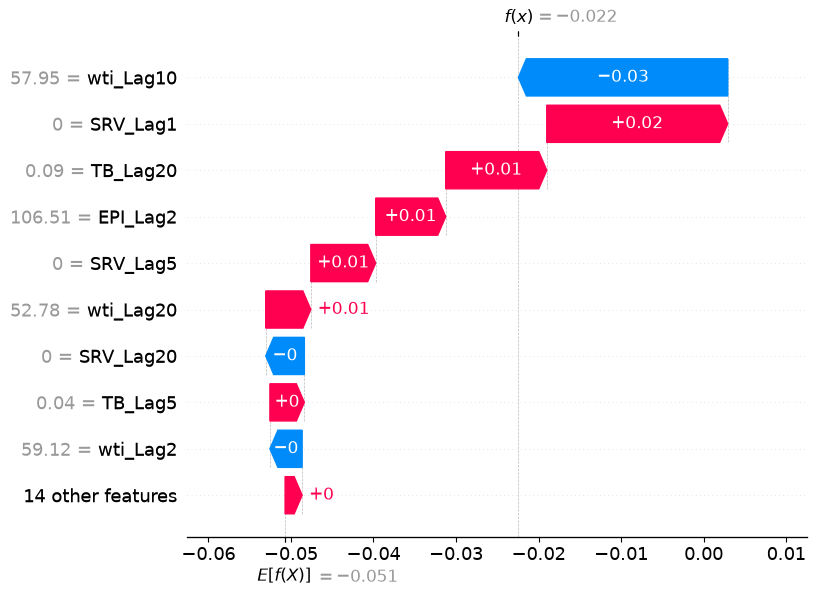


Worst Prediction - Observation 20


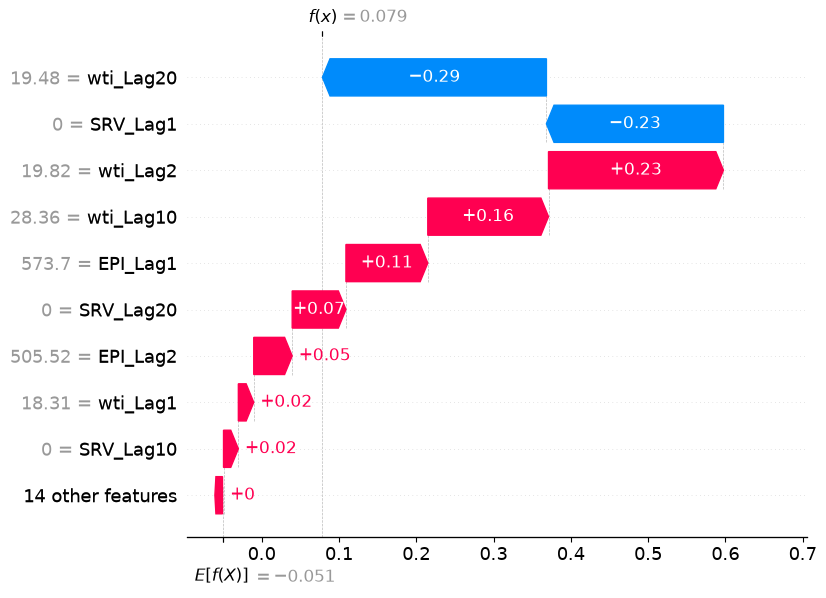

In [150]:
# Hai quan sát cần giải thích
selected_indices = {
    "Best Prediction": 232,
    "Worst Prediction": 20
}

for label, idx in selected_indices.items():

    sample_df = X_test_e5.iloc[[idx]]

    shap_local = shap_explainer_e5(sample_df)

    print(f"\n{label} - Observation {idx}")

    shap.plots.waterfall(
        shap_local[0],
        max_display=10
    )

In [151]:
# Độ lớn biến động thực tế của XGBoost Test
volatility = (
    y_test_change_multi
    .loc[X_test_e5.index]
    .abs()
)

# Ngưỡng phân vị
low_threshold = volatility.quantile(0.25)
high_threshold = volatility.quantile(0.75)

# Xác định hai nhóm
low_mask = volatility <= low_threshold
high_mask = volatility >= high_threshold

print("Ngưỡng biến động thấp:", low_threshold)
print("Ngưỡng biến động cao:", high_threshold)

print("Số quan sát biến động thấp:", low_mask.sum())
print("Số quan sát biến động cao:", high_mask.sum())

Ngưỡng biến động thấp: 0.48999999999999666
Ngưỡng biến động cao: 1.9100000000000037
Số quan sát biến động thấp: 210
Số quan sát biến động cao: 210


In [152]:
# Tính SHAP values cho 839 quan sát
shap_values_test = shap_explainer_e5(X_test_e5)

# Chuyển SHAP thành DataFrame, giữ nguyên index XGBoost Test
shap_values_df = pd.DataFrame(
    shap_values_test.values,
    index=X_test_e5.index,
    columns=X_test_e5.columns
)

print("Kích thước SHAP:", shap_values_df.shape)

Kích thước SHAP: (839, 23)


In [153]:
print("Số dòng SHAP:", len(shap_values_df))
print("Số dòng volatility:", len(volatility))
print("Số dòng low_mask:", len(low_mask))
print("Số dòng high_mask:", len(high_mask))

print(
    "Index SHAP và volatility khớp:",
    shap_values_df.index.equals(volatility.index)
)

assert shap_values_df.index.equals(volatility.index)

Số dòng SHAP: 839
Số dòng volatility: 839
Số dòng low_mask: 839
Số dòng high_mask: 839
Index SHAP và volatility khớp: True


In [154]:
# Tách SHAP theo hai nhóm
shap_low = shap_values_df.loc[low_mask]
shap_high = shap_values_df.loc[high_mask]

# Mean Absolute SHAP
importance_low = shap_low.abs().mean()
importance_high = shap_high.abs().mean()

# Bảng so sánh
comparison = pd.DataFrame({
    "Low_Volatility": importance_low,
    "High_Volatility": importance_high
})

comparison["Difference"] = (
    comparison["High_Volatility"]
    - comparison["Low_Volatility"]
)

comparison = comparison.sort_values(
    "High_Volatility",
    ascending=False
)

print(comparison.to_string())

           Low_Volatility  High_Volatility  Difference
wti_Lag2         0.022992         0.093548    0.070556
SRV_Lag1         0.047572         0.084707    0.037135
wti_Lag10        0.066826         0.050166   -0.016659
wti_Lag20        0.017652         0.034552    0.016899
SRV_Lag5         0.009263         0.033496    0.024233
SRV_Lag20        0.025682         0.031693    0.006011
wti_Lag1         0.015511         0.031443    0.015932
EPI_Lag1         0.027327         0.022108   -0.005218
SRV_Lag10        0.007759         0.019237    0.011478
EPI_Lag2         0.016782         0.016583   -0.000199
SRV_Lag3         0.004554         0.011651    0.007097
TB_Lag20         0.015461         0.011046   -0.004415
TB_Lag10         0.004682         0.004498   -0.000184
TB_Lag5          0.005822         0.004277   -0.001546
TB_Lag2          0.002373         0.003966    0.001593
EPI_Lag10        0.001807         0.002268    0.000462
EPI_Lag20        0.002089         0.002078   -0.000011
EPI_Lag5  

In [155]:
feature_groups = {
    "WTI": [f for f in features_e5 if f.startswith("wti_")],
    "EPI": [f for f in features_e5 if f.startswith("EPI_")],
    "SRV": [f for f in features_e5 if f.startswith("SRV_")],
    "TB": [f for f in features_e5 if f.startswith("TB_")]
}

group_comparison = pd.DataFrame({
    "Low_Volatility": {
        group: shap_values_df.loc[low_mask, cols].abs().values.mean()
        for group, cols in feature_groups.items()
    },
    "High_Volatility": {
        group: shap_values_df.loc[high_mask, cols].abs().values.mean()
        for group, cols in feature_groups.items()
    }
})

group_comparison["Difference"] = (
    group_comparison["High_Volatility"]
    - group_comparison["Low_Volatility"]
)

print(group_comparison)

     Low_Volatility  High_Volatility  Difference
WTI        0.020497         0.034952    0.014455
EPI        0.008178         0.007479   -0.000698
SRV        0.015894         0.030339    0.014445
TB         0.005668         0.004757   -0.000910


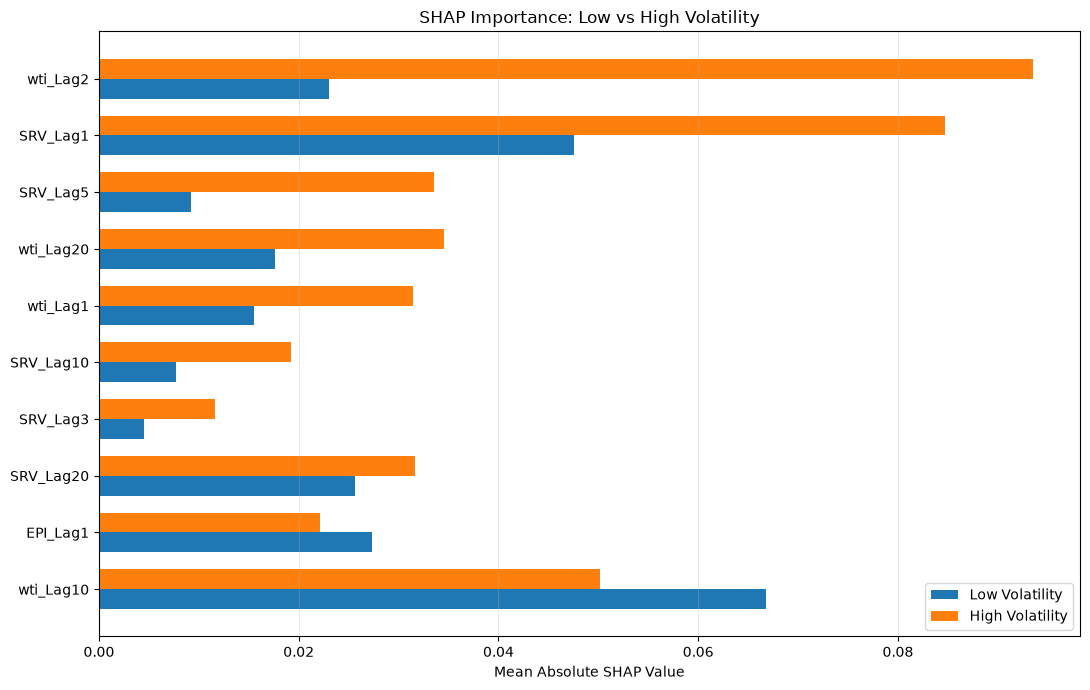

In [156]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 10 đặc trưng có chênh lệch SHAP tuyệt đối lớn nhất
top_features = (
    comparison["Difference"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

plot_comparison = comparison.loc[top_features].sort_values(
    "Difference"
)

y = np.arange(len(plot_comparison))
height = 0.35

plt.figure(figsize=(11, 7))

plt.barh(
    y - height/2,
    plot_comparison["Low_Volatility"],
    height,
    label="Low Volatility"
)

plt.barh(
    y + height/2,
    plot_comparison["High_Volatility"],
    height,
    label="High Volatility"
)

plt.yticks(y, plot_comparison.index)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("SHAP Importance: Low vs High Volatility")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [157]:
import numpy as np
import pandas as pd

# Lấy giá trị SHAP tuyệt đối
abs_shap = np.abs(shap_values_df.values)

# Chuyển mask sang numpy
low_labels = low_mask.values
high_labels = high_mask.values

# Nhãn trạng thái thị trường
regime_labels = low_labels.astype(int) - high_labels.astype(int)

# Kiểm tra
print("Tổng số quan sát:", len(abs_shap))
print("Biến động thấp:", low_labels.sum())
print("Biến động cao:", high_labels.sum())
print("Số đặc trưng:", abs_shap.shape[1])

Tổng số quan sát: 839
Biến động thấp: 210
Biến động cao: 210
Số đặc trưng: 23


In [158]:
# Cấu hình Bootstrap
B = 1000
block_length = 10
n = len(abs_shap)

rng = np.random.default_rng(42)

# Lưu kết quả
bootstrap_results = {
    group: []
    for group in feature_groups
}

for b in range(B):

    sampled_indices = []

    # Lấy các block liên tiếp
    while len(sampled_indices) < n:
        start = rng.integers(0, n)

        block = [
            (start + j) % n
            for j in range(block_length)
        ]

        sampled_indices.extend(block)

    sampled_indices = np.array(sampled_indices[:n])

    # Dữ liệu Bootstrap
    sampled_shap = abs_shap[sampled_indices]
    sampled_regime = regime_labels[sampled_indices]

    for group, cols in feature_groups.items():

        feature_indices = [
            features_e5.index(col)
            for col in cols
        ]

        group_values = sampled_shap[:, feature_indices].mean(axis=1)

        low_values = group_values[sampled_regime == 1]
        high_values = group_values[sampled_regime == -1]

        difference = high_values.mean() - low_values.mean()

        bootstrap_results[group].append(difference)

print("Hoàn thành", B, "lần Bootstrap!")

Hoàn thành 1000 lần Bootstrap!


In [159]:
bootstrap_summary = []

for group, values in bootstrap_results.items():

    values = np.array(values)

    observed_diff = (
        group_comparison.loc[group, "High_Volatility"]
        - group_comparison.loc[group, "Low_Volatility"]
    )

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    bootstrap_summary.append({
        "Group": group,
        "Observed_Difference": observed_diff,
        "CI_Lower_95%": lower,
        "CI_Upper_95%": upper,
        "Bootstrap_Mean": values.mean()
    })

bootstrap_df = pd.DataFrame(bootstrap_summary)

print(bootstrap_df.to_string(index=False))

Group  Observed_Difference  CI_Lower_95%  CI_Upper_95%  Bootstrap_Mean
  WTI             0.014455     -0.000230      0.033863        0.014357
  EPI            -0.000698     -0.002802      0.001565       -0.000691
  SRV             0.014445      0.006723      0.024899        0.014356
   TB            -0.000910     -0.002327      0.000285       -0.000907


In [160]:
block_lengths = [5, 10, 20]
B = 1000

sensitivity_results = []

for L in block_lengths:

    rng = np.random.default_rng(42)

    for group, cols in feature_groups.items():

        feature_indices = [
            features_e5.index(col) for col in cols
        ]

        group_values = abs_shap[:, feature_indices].mean(axis=1)

        boot_diffs = []

        for b in range(B):
            sampled_indices = []

            while len(sampled_indices) < n:
                start = rng.integers(0, n)
                block = [(start + j) % n for j in range(L)]
                sampled_indices.extend(block)

            idx = np.array(sampled_indices[:n])
            labels = regime_labels[idx]
            values = group_values[idx]

            diff = (
                values[labels == -1].mean()
                - values[labels == 1].mean()
            )

            boot_diffs.append(diff)

        sensitivity_results.append({
            "Block_Length": L,
            "Group": group,
            "CI_Lower": np.percentile(boot_diffs, 2.5),
            "CI_Upper": np.percentile(boot_diffs, 97.5)
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print(sensitivity_df.to_string(index=False))

 Block_Length Group  CI_Lower  CI_Upper
            5   WTI  0.002209  0.028439
            5   EPI -0.002519  0.001111
            5   SRV  0.007228  0.022542
            5    TB -0.002076  0.000065
           10   WTI -0.000230  0.033863
           10   EPI -0.002721  0.001355
           10   SRV  0.006833  0.025186
           10    TB -0.002342  0.000275
           20   WTI -0.002139  0.038054
           20   EPI -0.003498  0.001932
           20   SRV  0.005890  0.025883
           20    TB -0.002706  0.000473


In [161]:
print("Dữ liệu đã sắp xếp:",
      df_multi["Date"].is_monotonic_increasing)

print("Ngày bị trùng:",
      df_multi["Date"].duplicated().sum())

Dữ liệu đã sắp xếp: True
Ngày bị trùng: 0


In [162]:

# ==========================================
# KIỂM TRA DATA LEAKAGE VÀ DATA ALIGNMENT
# ==========================================

# 1. Kiểm tra thứ tự thời gian
print("===== KIỂM TRA THỜI GIAN =====")

print(
    "Dữ liệu đã sắp xếp:",
    data_multi_model["Date"].is_monotonic_increasing
)

print(
    "Số ngày bị trùng:",
    data_multi_model["Date"].duplicated().sum()
)

# 2. Kiểm tra Features E5
print("\n===== KIỂM TRA FEATURES E5 =====")

print("Số Features E5:", len(features_e5))

print(
    "Có chứa WTI hiện tại:",
    "wti" in features_e5
)

print(
    "Có chứa WTI_Change:",
    "WTI_Change" in features_e5
)

print(
    "Số giá trị thiếu trong E5 Train:",
    X_train_multi[features_e5].isnull().sum().sum()
)

print(
    "Số giá trị thiếu trong E5 Test:",
    X_test_multi[features_e5].isnull().sum().sum()
)

# 3. Kiểm tra công thức WTI Change
print("\n===== KIỂM TRA MỤC TIÊU =====")

actual_change_check = (
    y_test_multi.values
    - X_test_multi["wti_Lag1"].values
)

print(
    "WTI Change khớp:",
    np.allclose(
        actual_change_check,
        y_test_change_multi.values
    )
)

# 4. Kiểm tra khôi phục giá WTI
reconstructed_price = (
    X_test_multi["wti_Lag1"].values
    + y_test_change_multi.values
)

print(
    "Khôi phục giá WTI khớp:",
    np.allclose(
        reconstructed_price,
        y_test_multi.values
    )
)

# 5. Kiểm tra ngày giữa XGBoost và GARCH
print("\n===== KIỂM TRA XGBOOST VÀ GARCH =====")

xgb_test_dates = (
    data_multi_model["Date"]
    .iloc[split_multi:]
    .reset_index(drop=True)
)

garch_test_dates = (
    garch_test["Date"]
    .reset_index(drop=True)
)

print(
    "Ngày Test XGBoost và GARCH khớp:",
    xgb_test_dates.equals(garch_test_dates)
)

print("\nNgày bắt đầu Test:", xgb_test_dates.min())
print("Ngày kết thúc Test:", xgb_test_dates.max())


===== KIỂM TRA THỜI GIAN =====
Dữ liệu đã sắp xếp: True
Số ngày bị trùng: 0

===== KIỂM TRA FEATURES E5 =====
Số Features E5: 23
Có chứa WTI hiện tại: False
Có chứa WTI_Change: False
Số giá trị thiếu trong E5 Train: 0
Số giá trị thiếu trong E5 Test: 0

===== KIỂM TRA MỤC TIÊU =====
WTI Change khớp: True
Khôi phục giá WTI khớp: True

===== KIỂM TRA XGBOOST VÀ GARCH =====
Ngày Test XGBoost và GARCH khớp: True

Ngày bắt đầu Test: 2020-03-20 00:00:00
Ngày kết thúc Test: 2023-07-24 00:00:00


In [163]:

# ==========================================
# KIỂM TRA ĐẶC ĐIỂM CÁC BIẾN THEO BÀI BÁO
# ==========================================

check_columns = ["GP", "EPI", "TB", "SRV"]

# 1. Thống kê mô tả
print("===== THỐNG KÊ MÔ TẢ =====")

display(
    data_multi_model[check_columns].describe().round(4)
)

# 2. Kiểm tra số ngày có thay đổi giá trị
print("\n===== KIỂM TRA TẦN SUẤT THAY ĐỔI =====")

for col in check_columns:

    changes = (
        data_multi_model[col]
        .ne(data_multi_model[col].shift())
    )

    print(
        f"{col}: {changes.sum()} lần thay đổi "
        f"trên {len(data_multi_model)} dòng"
    )

# 3. Kiểm tra số giá trị khác nhau trong mỗi tháng
print("\n===== SỐ GIÁ TRỊ KHÁC NHAU TRONG MỖI THÁNG =====")

monthly_unique = (
    data_multi_model
    .groupby(data_multi_model["Date"].dt.to_period("M"))[
        check_columns
    ]
    .nunique()
)

display(monthly_unique.describe().round(2))

# 4. Xem những ngày EPI thay đổi
print("\n===== CÁC NGÀY EPI THAY ĐỔI =====")

epi_changes = data_multi_model[
    data_multi_model["EPI"].ne(
        data_multi_model["EPI"].shift()
    )
][["Date", "EPI"]]

display(epi_changes.head(20))

# 5. Xem những ngày GP thay đổi
print("\n===== CÁC NGÀY GP THAY ĐỔI =====")

gp_changes = data_multi_model[
    data_multi_model["GP"].ne(
        data_multi_model["GP"].shift()
    )
][["Date", "GP"]]

display(gp_changes.head(20))


===== THỐNG KÊ MÔ TẢ =====


,GP,EPI,TB,SRV
count,2469.0000,2473.0000,2473.0000,2473.0000
mean,3.3561,117.3273,1.0629,0.0000
std,1.5213,90.2818,1.3547,0.0001
min,1.3300,3.3200,-0.0500,0.0000
25%,2.5000,62.3600,0.0500,0.0000
50%,2.8900,91.6500,0.3300,0.0000
75%,3.8200,138.6600,1.8100,0.0000
max,23.8600,807.6600,5.2800,0.0031



===== KIỂM TRA TẦN SUẤT THAY ĐỔI =====
GP: 2114 lần thay đổi trên 2473 dòng
EPI: 2473 lần thay đổi trên 2473 dòng
TB: 1679 lần thay đổi trên 2473 dòng
SRV: 2385 lần thay đổi trên 2473 dòng

===== SỐ GIÁ TRỊ KHÁC NHAU TRONG MỖI THÁNG =====


,GP,EPI,TB,SRV
count,119.00,119.00,119.00,119.00
mean,15.60,20.77,8.37,20.17
std,2.82,1.60,4.53,1.84
min,10.00,11.00,2.00,11.00
25%,14.00,20.00,4.00,19.00
50%,16.00,21.00,7.00,20.00
75%,18.00,22.00,12.00,21.00
max,23.00,23.00,21.00,23.00



===== CÁC NGÀY EPI THAY ĐỔI =====


,Date,EPI
0,2013-09-16,149.94
1,2013-09-17,127.79
2,2013-09-18,84.39
3,2013-09-19,87.37
4,2013-09-20,160.51
5,2013-09-23,105.52
6,2013-09-24,127.69
7,2013-09-25,134.20
8,2013-09-26,83.62
9,2013-09-27,91.83



===== CÁC NGÀY GP THAY ĐỔI =====


,Date,GP
0,2013-09-16,3.64
1,2013-09-17,3.77
2,2013-09-18,3.72
3,2013-09-19,3.73
4,2013-09-20,3.68
5,2013-09-23,3.66
6,2013-09-24,3.59
7,2013-09-25,3.52
8,2013-09-26,3.49
9,2013-09-27,3.51


In [164]:
# ==========================================
# SAVE ALL IMPORTANT RESEARCH RESULTS
# ==========================================

from pathlib import Path
import pandas as pd
import joblib

# 1. Tạo thư mục lưu kết quả
RESULTS_DIR = Path("../results")

TABLES_DIR = RESULTS_DIR / "tables"
MODELS_DIR = RESULTS_DIR / "models"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Tổng hợp kết quả E3 và E5
e3_e5_metrics = pd.DataFrame({
    "E3 Univariate": results_e3,
    "E5 Optimized": results_e5
})

# 3. Các bảng kết quả
tables_to_save = {
    "CV_Fold_Results": cv_results_df,
    "CV_Summary": cv_summary,
    "E4_E5_Test_Results": test_results_df,
    "E3_E5_Metrics": e3_e5_metrics.T.reset_index(),
    "E5_Optimized_Metrics": pd.DataFrame([results_best_e5]),
    "E5_Best_Parameters": pd.DataFrame([best_params]),
    "GARCH_QLIKE_Results": results_df,
    "GARCH_DME_Test": dm_results_df,
    "E3_E5_Prediction_Errors": error_comparison,
    "SHAP_Feature_Comparison": comparison,
    "SHAP_Group_Comparison": group_comparison,
    "SHAP_Bootstrap": bootstrap_df,
    "SHAP_Sensitivity": sensitivity_df,
    "Conformal_Final": final_conformal_table,
    "Conformal_MBB": mbb_results_df,
    "Conformal_Regimes": regime_results_df,
    "Rolling_Coverage": rolling_coverage_summary_df,
    "Coverage_Stability": coverage_stability_df
}

# 4. Lưu từng bảng CSV
for name, df in tables_to_save.items():

    df.to_csv(
        TABLES_DIR / f"{name}.csv",
        index=True,
        encoding="utf-8-sig"
    )

# 5. Lưu kết quả dự báo theo ngày
prediction_tables = {
    "Split_CP_Predictions": cp_predictions,
    "Rolling_CP_Predictions": rolling_predictions,
    "Volatility_Adaptive_Predictions": vol_adaptive_predictions,
    "GARCH_Adaptive_Predictions": garch_adaptive_predictions,
    "GARCH_Volatility_Forecasts": plot_data
}

for name, df in prediction_tables.items():

    df.to_csv(
        TABLES_DIR / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )

# 6. Ghi tất cả các bảng vào một file Excel
with pd.ExcelWriter(
    TABLES_DIR / "Research_Results.xlsx",
    engine="openpyxl"
) as writer:

    for name, df in tables_to_save.items():

        df.to_excel(
            writer,
            sheet_name=name[:31]
        )

# 7. Lưu tham số EGARCH của Conformal
egarch_params = (
    egarch_cp_result.params
    .rename("Estimate")
    .rename_axis("Parameter")
    .reset_index()
)

egarch_params.to_csv(
    TABLES_DIR / "EGARCH_CP_Parameters.csv",
    index=False,
    encoding="utf-8-sig"
)

# 8. Lưu mô hình XGBoost đã huấn luyện
joblib.dump(
    best_model_e5,
    MODELS_DIR / "Best_XGBoost_E5.joblib"
)

joblib.dump(
    cp_model,
    MODELS_DIR / "XGBoost_CP_Model.joblib"
)

print("===== SAVE RESULTS COMPLETED =====")
print("Project results folder:", RESULTS_DIR.resolve())
print("Number of result tables:", len(tables_to_save))
print("Number of prediction files:", len(prediction_tables))
print("Excel workbook:", TABLES_DIR / "Research_Results.xlsx")
print("Models saved:", MODELS_DIR.resolve())

===== SAVE RESULTS COMPLETED =====
Project results folder: C:\Users\admin\Energy_Forecasting_XAI\results
Number of result tables: 18
Number of prediction files: 5
Excel workbook: ..\results\tables\Research_Results.xlsx
Models saved: C:\Users\admin\Energy_Forecasting_XAI\results\models


In [165]:
# ==========================================
# SAVE IMPORTANT RESEARCH FIGURES
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
import shap

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------
# 1. E3 vs E5 Forecast
# ------------------------------------------

dates = pd.to_datetime(
    data_multi_model.loc[X_test_e5.index, "Date"]
)

assert len(dates) == len(y_pred_price_uni) == len(predicted_prices)

plt.figure(figsize=(15, 6))

plt.plot(
    dates,
    actual_prices,
    label="Actual WTI"
)

plt.plot(
    dates,
    y_pred_price_uni,
    label="E3 Univariate"
)

plt.plot(
    dates,
    predicted_prices,
    label="E5 Optimized"
)

plt.title("Actual vs Predicted WTI: E3 vs E5")
plt.xlabel("Date")
plt.ylabel("WTI Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "01_E3_vs_E5_Forecast.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# 2. Four Conformal Prediction Methods
# ------------------------------------------

cp_frames = [
    ("Split Conformal", cp_predictions),
    ("Rolling Conformal", rolling_predictions),
    ("Volatility-Adaptive", vol_adaptive_predictions),
    ("GARCH-Adaptive", garch_adaptive_predictions)
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

for ax, (name, df) in zip(axes.flat, cp_frames):

    ax.plot(
        df["Date"],
        df["Actual"],
        label="Actual",
        linewidth=0.8
    )

    ax.plot(
        df["Date"],
        df["Prediction"],
        label="Prediction",
        linewidth=0.8
    )

    ax.fill_between(
        df["Date"],
        df["Lower"],
        df["Upper"],
        alpha=0.2,
        label="90% Interval"
    )

    ax.set_title(name)
    ax.set_ylabel("WTI Price")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_Four_Conformal_Methods.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# 3. GARCH Volatility Forecast
# ------------------------------------------

plt.figure(figsize=(15, 6))

for col in [
    "Actual_Volatility",
    "GARCH",
    "GJR-GARCH",
    "EGARCH"
]:

    plt.plot(
        plot_data["Date"],
        plot_data[col],
        label=col,
        linewidth=0.8
    )

plt.title("Actual and Forecasted WTI Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_GARCH_Volatility.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# 4. SHAP Summary Plot
# ------------------------------------------

shap.summary_plot(
    shap_values_test.values,
    X_test_e5,
    max_display=20,
    show=False
)

plt.title("SHAP Summary - Optimized E5")

plt.savefig(
    FIGURES_DIR / "04_SHAP_Summary_E5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# 5. SHAP Low vs High Volatility
# ------------------------------------------

groups = group_comparison.index.tolist()

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    x - width/2,
    group_comparison["Low_Volatility"],
    width,
    label="Low Volatility"
)

ax.bar(
    x + width/2,
    group_comparison["High_Volatility"],
    width,
    label="High Volatility"
)

ax.set_xticks(x)
ax.set_xticklabels(groups)

ax.set_ylabel("Mean Absolute SHAP Value")
ax.set_title("SHAP Importance: Low vs High Volatility")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_SHAP_Low_vs_High.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


print("===== FIGURE EXPORT COMPLETED =====")
print("Saved figures:", FIGURES_DIR.resolve())

for file in sorted(FIGURES_DIR.glob("*.png")):
    print(file.name)

===== FIGURE EXPORT COMPLETED =====
Saved figures: C:\Users\admin\Energy_Forecasting_XAI\results\figures
01_E3_vs_E5_Forecast.png
02_Four_Conformal_Methods.png
03_GARCH_Volatility.png
04_SHAP_Summary_E5.png
05_SHAP_Low_vs_High.png


In [166]:
# Kiểm tra các file đã lưu
print("===== RESULTS DIRECTORY =====")

for folder in [TABLES_DIR, FIGURES_DIR, MODELS_DIR]:

    files = list(folder.iterdir())

    print(f"\n{folder}:")
    print("Number of files:", len(files))

    for file in files:
        print(" -", file.name)

===== RESULTS DIRECTORY =====

..\results\tables:
Number of files: 25
 - Conformal_Final.csv
 - Conformal_MBB.csv
 - Conformal_Regimes.csv
 - Coverage_Stability.csv
 - CV_Fold_Results.csv
 - CV_Summary.csv
 - E3_E5_Metrics.csv
 - E3_E5_Prediction_Errors.csv
 - E4_E5_Test_Results.csv
 - E5_Best_Parameters.csv
 - E5_Optimized_Metrics.csv
 - EGARCH_CP_Parameters.csv
 - GARCH_Adaptive_Predictions.csv
 - GARCH_DME_Test.csv
 - GARCH_QLIKE_Results.csv
 - GARCH_Volatility_Forecasts.csv
 - Research_Results.xlsx
 - Rolling_Coverage.csv
 - Rolling_CP_Predictions.csv
 - SHAP_Bootstrap.csv
 - SHAP_Feature_Comparison.csv
 - SHAP_Group_Comparison.csv
 - SHAP_Sensitivity.csv
 - Split_CP_Predictions.csv
 - Volatility_Adaptive_Predictions.csv

..\results\figures:
Number of files: 5
 - 01_E3_vs_E5_Forecast.png
 - 02_Four_Conformal_Methods.png
 - 03_GARCH_Volatility.png
 - 04_SHAP_Summary_E5.png
 - 05_SHAP_Low_vs_High.png

..\results\models:
Number of files: 2
 - Best_XGBoost_E5.joblib
 - XGBoost_CP_Model

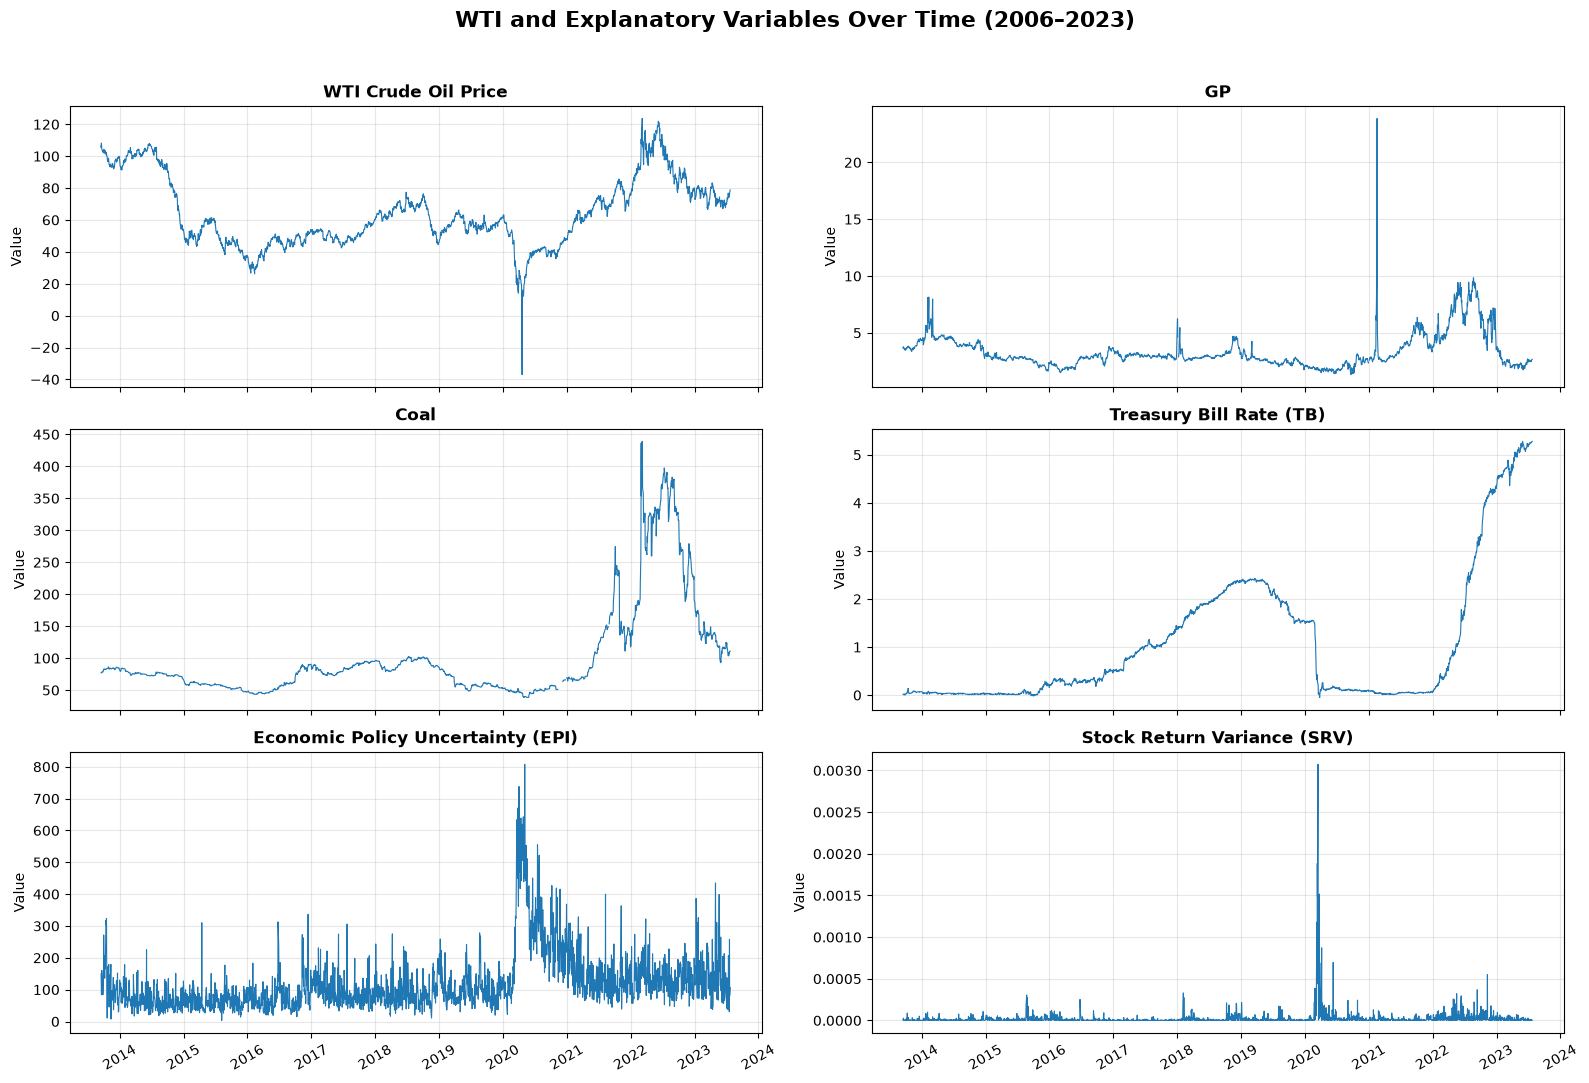

In [167]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Sử dụng dữ liệu đã làm sạch, trước bước tạo Lag
plot_df = df_clean.copy()

# Đảm bảo Date là cột dữ liệu
if "Date" in plot_df.columns:
    plot_df["Date"] = pd.to_datetime(plot_df["Date"])
    plot_df = plot_df.set_index("Date")
else:
    plot_df.index = pd.to_datetime(plot_df.index)

plot_df = plot_df.sort_index()

# Các biến cần biểu diễn
features = ["wti", "GP", "coal", "TB", "EPI", "SRV"]

# Kiểm tra cột
missing = [col for col in features if col not in plot_df.columns]
if missing:
    raise ValueError(f"Không tìm thấy các cột: {missing}")

# Chuyển về dạng số
for col in features:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

# Tạo 6 biểu đồ riêng biệt
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 11),
    sharex=True
)

axes = axes.flatten()

titles = {
    "wti": "WTI Crude Oil Price",
    "GP": "GP",
    "coal": "Coal",
    "TB": "Treasury Bill Rate (TB)",
    "EPI": "Economic Policy Uncertainty (EPI)",
    "SRV": "Stock Return Variance (SRV)"
}

for ax, col in zip(axes, features):
    ax.plot(
        plot_df.index,
        plot_df[col],
        linewidth=0.8
    )

    ax.set_title(titles[col], fontsize=12, fontweight="bold")
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "WTI and Explanatory Variables Over Time (2006–2023)",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

# Lưu ảnh
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_wti_macro_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


===== MISSING VALUES SUMMARY =====
GP       4
coal    24
TB       0
EPI      0
SRV      0
dtype: int64

Tổng số giá trị thiếu: 28


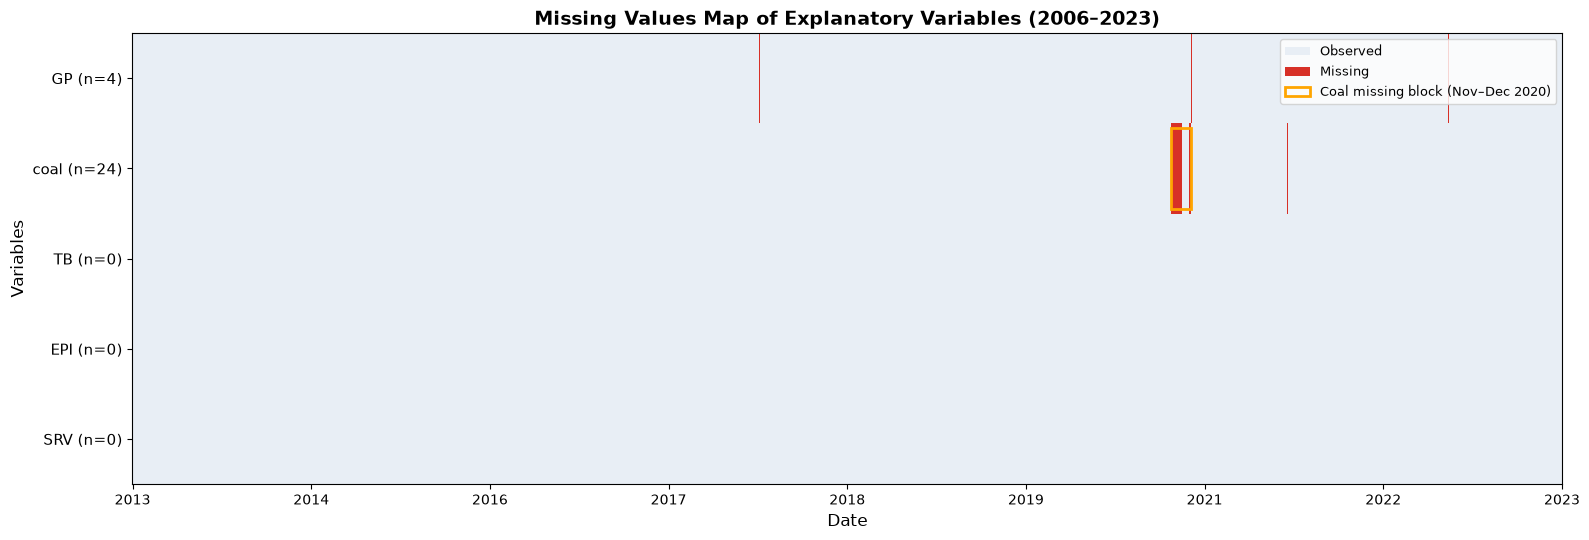

In [168]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from pathlib import Path

# Sử dụng dữ liệu cơ sở, chưa điền các giá trị thiếu
plot_df = data_multi.copy()

# Xử lý cột Date
if "Date" in plot_df.columns:
    plot_df["Date"] = pd.to_datetime(plot_df["Date"])
    plot_df = plot_df.set_index("Date")
else:
    plot_df.index = pd.to_datetime(plot_df.index)

plot_df = plot_df.sort_index()

# Các biến cần kiểm tra
features = ["GP", "coal", "TB", "EPI", "SRV"]

# Kiểm tra tên cột
missing_cols = [
    col for col in features
    if col not in plot_df.columns
]

if missing_cols:
    raise ValueError(
        f"Không tìm thấy các cột: {missing_cols}"
    )

# Ma trận giá trị thiếu: True = Missing, False = Observed
missing_matrix = plot_df[features].isna()

# Thống kê số lượng giá trị thiếu
missing_counts = missing_matrix.sum()

print("===== MISSING VALUES SUMMARY =====")
print(missing_counts)
print("\nTổng số giá trị thiếu:", missing_matrix.sum().sum())

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(16, 5.5))

cmap = ListedColormap(["#E8EEF5", "#D73027"])

ax.imshow(
    missing_matrix.T.astype(int),
    aspect="auto",
    interpolation="none",
    cmap=cmap,
    vmin=0,
    vmax=1
)

# Nhãn trục Y kèm số lượng missing
labels = [
    f"{col} (n={missing_counts[col]})"
    for col in features
]

ax.set_yticks(range(len(features)))
ax.set_yticklabels(labels, fontsize=11)

# Trục X: năm
n = len(plot_df)
tick_positions = np.linspace(0, n - 1, 9).astype(int)

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    [plot_df.index[i].strftime("%Y")
     for i in tick_positions]
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Variables", fontsize=12)
ax.set_title(
    "Missing Values Map of Explanatory Variables (2006–2023)",
    fontsize=14,
    fontweight="bold"
)

# Làm nổi bật khối thiếu Coal từ 11/2020 đến 12/2020
coal_row = features.index("coal")

coal_period = (
    missing_matrix["coal"]
    & (plot_df.index >= "2020-11-01")
    & (plot_df.index <= "2020-12-31")
)

coal_positions = np.where(coal_period.to_numpy())[0]

if len(coal_positions) > 0:
    left = coal_positions.min()
    right = coal_positions.max()

    highlight = Rectangle(
        (left - 0.5, coal_row - 0.45),
        right - left + 1,
        0.9,
        linewidth=2,
        edgecolor="orange",
        facecolor="none"
    )

    ax.add_patch(highlight)

# Chú giải
legend_items = [
    Patch(facecolor="#E8EEF5", label="Observed"),
    Patch(facecolor="#D73027", label="Missing"),
    Patch(
        facecolor="none",
        edgecolor="orange",
        linewidth=2,
        label="Coal missing block (Nov–Dec 2020)"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper right",
    fontsize=9
)

ax.grid(False)
fig.tight_layout()

# Lưu ảnh
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/missing_values_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


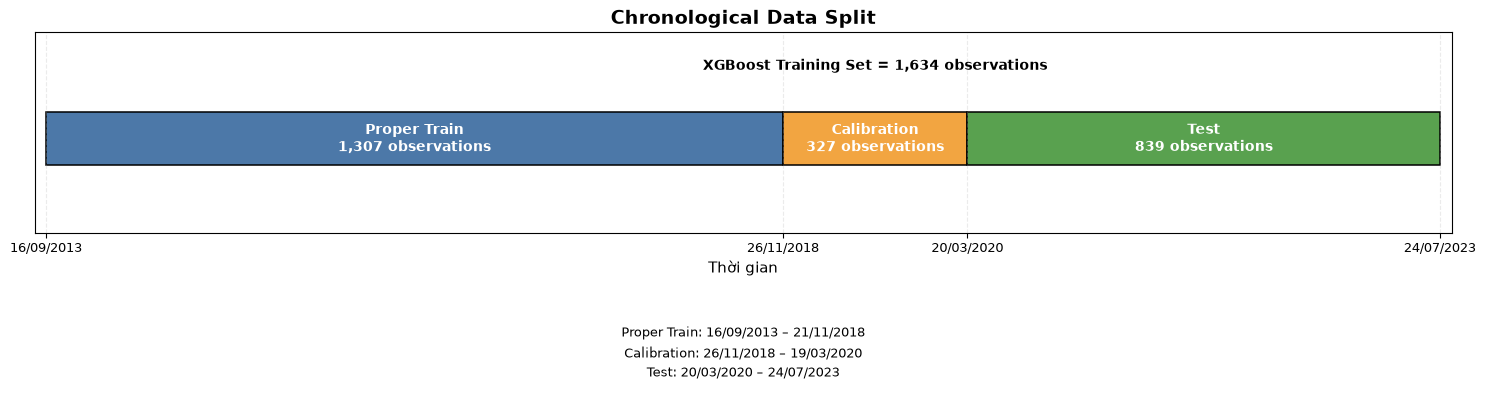

In [169]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Lấy ngày từ dữ liệu gốc đã tạo feature
if "Date" in data_multi.columns:
    dates_all = pd.to_datetime(
        data_multi["Date"]
    ).reset_index(drop=True)

elif isinstance(data_multi.index, pd.DatetimeIndex):
    dates_all = pd.Series(
        pd.to_datetime(data_multi.index)
    ).reset_index(drop=True)

else:
    raise ValueError(
        "Không tìm thấy cột Date hoặc DatetimeIndex. "
        "Hãy kiểm tra lại dữ liệu ngày."
    )

# Kích thước các tập
n_proper = 1307
n_cal = 327
n_test = 839

n_total = n_proper + n_cal + n_test

assert len(dates_all) == n_total, (
    f"Số ngày ({len(dates_all)}) không khớp "
    f"tổng số quan sát ({n_total})"
)

# Tạo các đoạn dữ liệu
segments = [
    {
        "name": "Proper Train",
        "start": 0,
        "end": n_proper,
        "color": "#4C78A8",
        "count": n_proper
    },
    {
        "name": "Calibration",
        "start": n_proper,
        "end": n_proper + n_cal,
        "color": "#F2A541",
        "count": n_cal
    },
    {
        "name": "Test",
        "start": n_proper + n_cal,
        "end": n_total,
        "color": "#59A14F",
        "count": n_test
    }
]

fig, ax = plt.subplots(figsize=(15, 4.8))

# Vẽ các đoạn trên cùng một trục
for item in segments:
    left = item["start"]
    width = item["end"] - item["start"]

    ax.barh(
        y=0,
        width=width,
        left=left,
        height=0.42,
        color=item["color"],
        edgecolor="black",
        linewidth=1.1
    )

    center = left + width / 2

    ax.text(
        center, 0,
        f'{item["name"]}\n{item["count"]:,} observations',
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="white"
    )

# Các mốc ngày quan trọng
milestones = [
    (0, "16/09/2013"),
    (n_proper, "26/11/2018"),
    (n_proper + n_cal, "20/03/2020"),
    (n_total - 1, "24/07/2023")
]

ax.set_xticks([x for x, _ in milestones])
ax.set_xticklabels(
    [label for _, label in milestones],
    fontsize=9
)

ax.set_xlim(-20, n_total + 20)
ax.set_yticks([])

ax.set_xlabel("Thời gian", fontsize=11)
ax.set_title(
    "Chronological Data Split",
    fontsize=14,
    fontweight="bold"
)

# Ghi chú về tập huấn luyện XGBoost
ax.text(
    n_proper + n_cal / 2,
    0.55,
    "XGBoost Training Set = 1,634 observations",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

# Các khoảng ngày chính xác
date_notes = (
    "Proper Train: 16/09/2013 – 21/11/2018\n"
    "Calibration: 26/11/2018 – 19/03/2020\n"
    "Test: 20/03/2020 – 24/07/2023"
)

ax.text(
    0.5, -0.45,
    date_notes,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=9,
    linespacing=1.6
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_ylim(-0.75, 0.85)

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/train_cal_test_timeline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


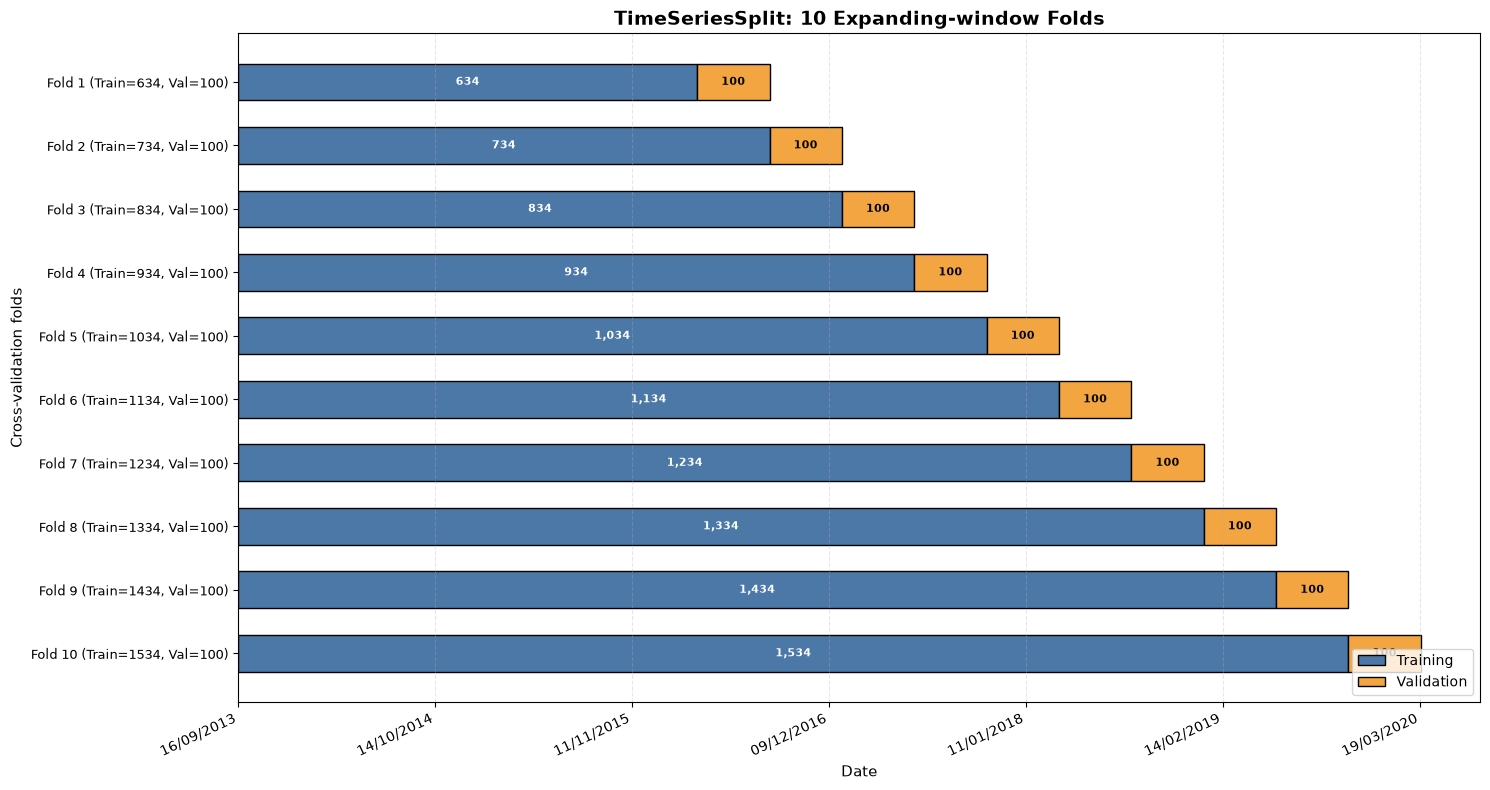

===== TIMESERIES SPLIT SUMMARY =====
Fold 1: Train = 634, Validation = 100, Validation end = 12/08/2016
Fold 2: Train = 734, Validation = 100, Validation end = 05/01/2017
Fold 3: Train = 834, Validation = 100, Validation end = 31/05/2017
Fold 4: Train = 934, Validation = 100, Validation end = 23/10/2017
Fold 5: Train = 1034, Validation = 100, Validation end = 19/03/2018
Fold 6: Train = 1134, Validation = 100, Validation end = 09/08/2018
Fold 7: Train = 1234, Validation = 100, Validation end = 07/01/2019
Fold 8: Train = 1334, Validation = 100, Validation end = 31/05/2019
Fold 9: Train = 1434, Validation = 100, Validation end = 23/10/2019
Fold 10: Train = 1534, Validation = 100, Validation end = 19/03/2020


In [170]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from pathlib import Path

# Cấu hình Cross-validation đúng như thí nghiệm
tscv_plot = TimeSeriesSplit(
    n_splits=10,
    test_size=100
)

# Lấy 10 folds thực tế
folds = list(tscv_plot.split(X_train_multi))

assert len(folds) == 10

# Lấy ngày của tập Train
dates_all = pd.to_datetime(
    data_multi["Date"]
    if "Date" in data_multi.columns
    else data_multi.index
)

dates_train = pd.Series(
    dates_all
).reset_index(drop=True).iloc[:len(X_train_multi)]

fig, ax = plt.subplots(figsize=(15, 8))

for i, (train_idx, val_idx) in enumerate(folds):

    # Đảo thứ tự để Fold 1 nằm dưới cùng
    y = 9 - i

    train_start = 0
    train_end = len(train_idx)

    val_start = val_idx[0]
    val_end = val_idx[-1] + 1

    # Vẽ phần Train
    ax.barh(
        y,
        train_end - train_start,
        left=train_start,
        height=0.58,
        color="#4C78A8",
        edgecolor="black",
        label="Training" if i == 0 else None
    )

    # Vẽ phần Validation
    ax.barh(
        y,
        val_end - val_start,
        left=val_start,
        height=0.58,
        color="#F2A541",
        edgecolor="black",
        label="Validation" if i == 0 else None
    )

    ax.text(
        train_end / 2,
        y,
        f'{len(train_idx):,}',
        ha="center",
        va="center",
        color="white",
        fontsize=8,
        fontweight="bold"
    )

    ax.text(
        val_start + 50,
        y,
        "100",
        ha="center",
        va="center",
        color="black",
        fontsize=8,
        fontweight="bold"
    )

# Nhãn từng Fold
fold_labels = [
    f"Fold {i+1} (Train={len(train_idx)}, Val={len(val_idx)})"
    for i, (train_idx, val_idx) in enumerate(folds)
]

ax.set_yticks(range(10))
ax.set_yticklabels(fold_labels[::-1], fontsize=9)

# Các mốc ngày trên trục ngang
tick_positions = np.linspace(
    0,
    len(X_train_multi) - 1,
    7
).astype(int)

ax.set_xticks(tick_positions)

ax.set_xticklabels(
    [
        dates_train.iloc[i].strftime("%d/%m/%Y")
        for i in tick_positions
    ],
    rotation=25,
    ha="right"
)

ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Cross-validation folds", fontsize=11)

ax.set_title(
    "TimeSeriesSplit: 10 Expanding-window Folds",
    fontsize=14,
    fontweight="bold"
)

ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/timeseries_cv_folds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Kiểm tra kích thước các Fold
print("===== TIMESERIES SPLIT SUMMARY =====")

for i, (train_idx, val_idx) in enumerate(folds, 1):
    print(
        f"Fold {i}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}, "
        f"Validation end = "
        f"{dates_train.iloc[val_idx[-1]].strftime('%d/%m/%Y')}"
    )


Các cột hiện có: ['Fold', 'Model', 'Features', 'MAE', 'RMSE', 'R2', 'DA (%)']
   Fold                     Model  Features       MAE      RMSE        R2  \
0     1         E4 - Without Coal        29  0.982044  1.252673  0.902459   
1     1  E5 - Without Coal and GP        23  1.013247  1.291382  0.896338   
2     2         E4 - Without Coal        29  0.897896  1.135301  0.859738   
3     2  E5 - Without Coal and GP        23  0.856834  1.086418  0.871556   
4     3         E4 - Without Coal        29  0.648899  0.877690  0.867337   

   DA (%)  
0    48.0  
1    48.0  
2    47.0  
3    49.0  
4    45.0  
E4 số folds: 10
E5 số folds: 10


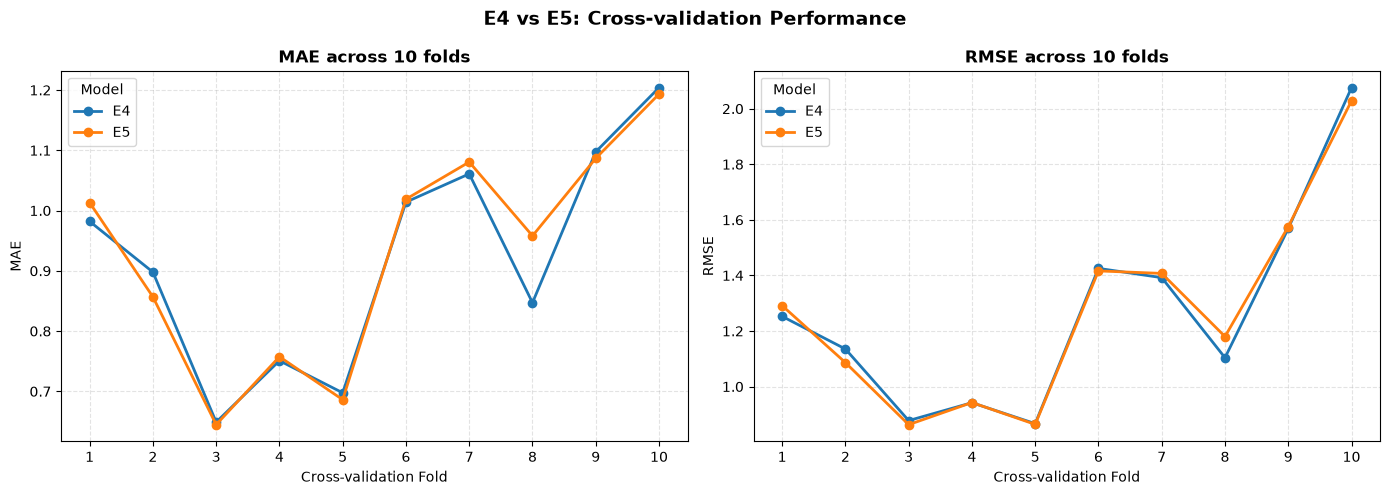

In [171]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Lấy kết quả 10-fold CV đã tính trong notebook
cv_plot = cv_results_df.copy()

# Kiểm tra tên cột
print("Các cột hiện có:", cv_plot.columns.tolist())
print(cv_plot.head())

# Chuẩn hóa tên cột nếu có khoảng trắng
cv_plot.columns = cv_plot.columns.str.strip()

# Các cột cần thiết
required = ["Model", "Fold", "MAE", "RMSE"]
missing = [c for c in required if c not in cv_plot.columns]

if missing:
    raise ValueError(
        f"Thiếu các cột {missing}. "
        "Hãy kiểm tra cấu trúc cv_results_df."
    )

# Chỉ lấy E4 và E5
cv_plot = cv_plot[
    cv_plot["Model"].astype(str).str.contains(
        r"E4|E5", case=False, regex=True
    )
].copy()

# Sắp xếp folds
cv_plot["Fold"] = pd.to_numeric(
    cv_plot["Fold"], errors="coerce"
)

cv_plot = cv_plot.sort_values(
    ["Model", "Fold"]
)

# Kiểm tra mỗi mô hình có đúng 10 folds
for model in ["E4", "E5"]:
    model_data = cv_plot[
        cv_plot["Model"].str.contains(
            model, case=False, regex=False
        )
    ]
    print(model, "số folds:", len(model_data))

# Vẽ hai biểu đồ cạnh nhau
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

metrics = [
    ("MAE", "MAE across 10 folds"),
    ("RMSE", "RMSE across 10 folds")
]

for ax, (metric, title) in zip(axes, metrics):

    for model in ["E4", "E5"]:
        model_data = cv_plot[
            cv_plot["Model"].str.contains(
                model, case=False, regex=False
            )
        ].sort_values("Fold")

        ax.plot(
            model_data["Fold"],
            model_data[metric],
            marker="o",
            linewidth=2,
            markersize=6,
            label=model
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Cross-validation Fold")
    ax.set_ylabel(metric)
    ax.set_xticks(range(1, 11))
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(title="Model")

fig.suptitle(
    "E4 vs E5: Cross-validation Performance",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/cv_fold_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


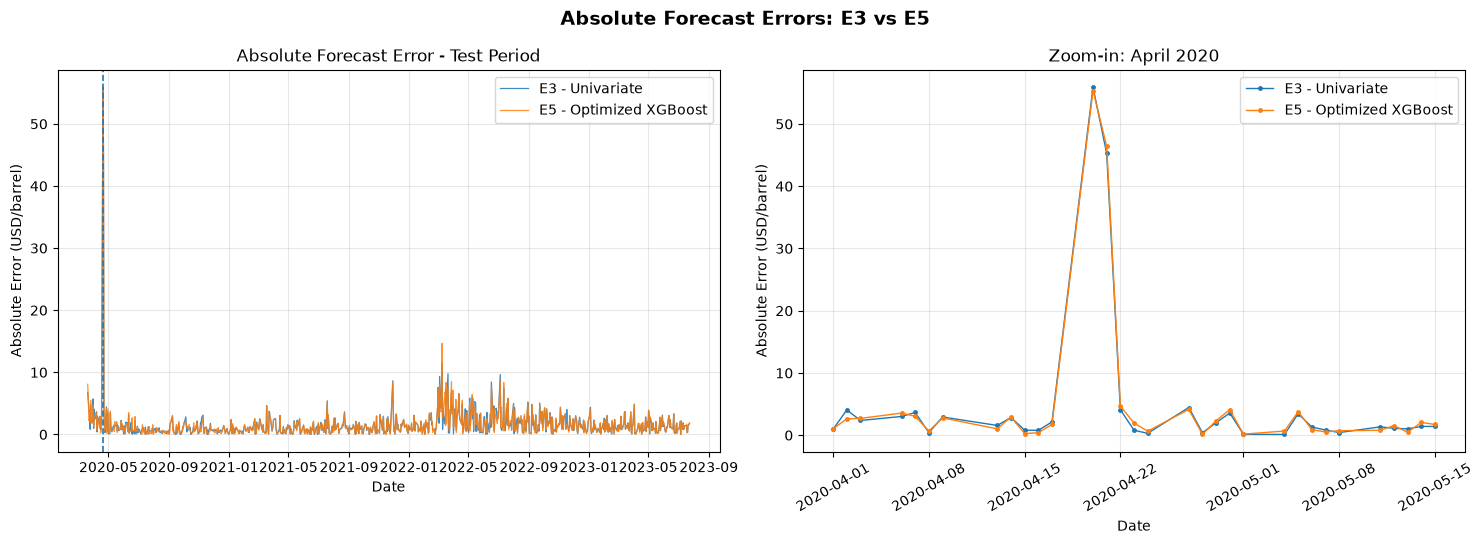

===== ABSOLUTE ERROR SUMMARY =====
E3 Mean Absolute Error: 1.5856
E5 Mean Absolute Error: 1.5927
Số quan sát: 839
Thời gian: 2020-03-20 00:00:00 đến 2023-07-24 00:00:00


In [172]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Lấy giá thực tế và giá dự báo
actual = np.asarray(actual_prices).reshape(-1)
pred_e3 = np.asarray(y_pred_price_uni).reshape(-1)
pred_e5 = np.asarray(predicted_prices).reshape(-1)

# Kiểm tra kích thước
assert len(actual) == len(pred_e3) == len(pred_e5), (
    "Số lượng giá thực tế và dự báo không bằng nhau!"
)

n = len(actual)

# 2. Lấy ngày của tập Test
if "Date" in data_multi_model.columns:
    dates = pd.to_datetime(
        data_multi_model["Date"].tail(n)
    ).reset_index(drop=True)

elif isinstance(data_multi_model.index, pd.DatetimeIndex):
    dates = pd.Series(
        pd.to_datetime(data_multi_model.index[-n:])
    ).reset_index(drop=True)

else:
    raise ValueError(
        "Không tìm thấy cột Date hoặc DatetimeIndex "
        "trong data_multi_model."
    )

assert len(dates) == n

# 3. Tính sai số tuyệt đối
error_e3 = np.abs(actual - pred_e3)
error_e5 = np.abs(actual - pred_e5)

error_df = pd.DataFrame({
    "Date": dates,
    "E3_Absolute_Error": error_e3,
    "E5_Absolute_Error": error_e5
})

# 4. Tạo hai biểu đồ:
#    - Toàn bộ giai đoạn Test
#    - Phóng to giai đoạn tháng 04/2020

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5)
)

# Biểu đồ toàn giai đoạn
axes[0].plot(
    error_df["Date"],
    error_df["E3_Absolute_Error"],
    label="E3 - Univariate",
    linewidth=0.9,
    alpha=0.85
)

axes[0].plot(
    error_df["Date"],
    error_df["E5_Absolute_Error"],
    label="E5 - Optimized XGBoost",
    linewidth=0.9,
    alpha=0.85
)

axes[0].set_title("Absolute Forecast Error - Test Period")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Absolute Error (USD/barrel)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Đánh dấu sự kiện tháng 04/2020
axes[0].axvline(
    pd.Timestamp("2020-04-20"),
    linestyle="--",
    linewidth=1.2,
    label="20 April 2020"
)

# Biểu đồ phóng to tháng 04/2020
zoom_start = pd.Timestamp("2020-04-01")
zoom_end = pd.Timestamp("2020-05-15")

zoom_df = error_df[
    (error_df["Date"] >= zoom_start) &
    (error_df["Date"] <= zoom_end)
]

axes[1].plot(
    zoom_df["Date"],
    zoom_df["E3_Absolute_Error"],
    marker="o",
    markersize=2.5,
    label="E3 - Univariate",
    linewidth=1
)

axes[1].plot(
    zoom_df["Date"],
    zoom_df["E5_Absolute_Error"],
    marker="o",
    markersize=2.5,
    label="E5 - Optimized XGBoost",
    linewidth=1
)

axes[1].set_title("Zoom-in: April 2020")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Absolute Error (USD/barrel)")
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle(
    "Absolute Forecast Errors: E3 vs E5",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()

# 5. Lưu hình
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/e3_e5_absolute_error_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. In kiểm tra sai số
print("===== ABSOLUTE ERROR SUMMARY =====")

print(
    "E3 Mean Absolute Error:",
    round(error_df["E3_Absolute_Error"].mean(), 4)
)

print(
    "E5 Mean Absolute Error:",
    round(error_df["E5_Absolute_Error"].mean(), 4)
)

print("Số quan sát:", len(error_df))
print("Thời gian:", dates.min(), "đến", dates.max())


In [174]:

from pathlib import Path

# Lưu biểu đồ Rolling Coverage
Path("figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "figures/rolling_coverage_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


<Figure size 640x480 with 0 Axes>

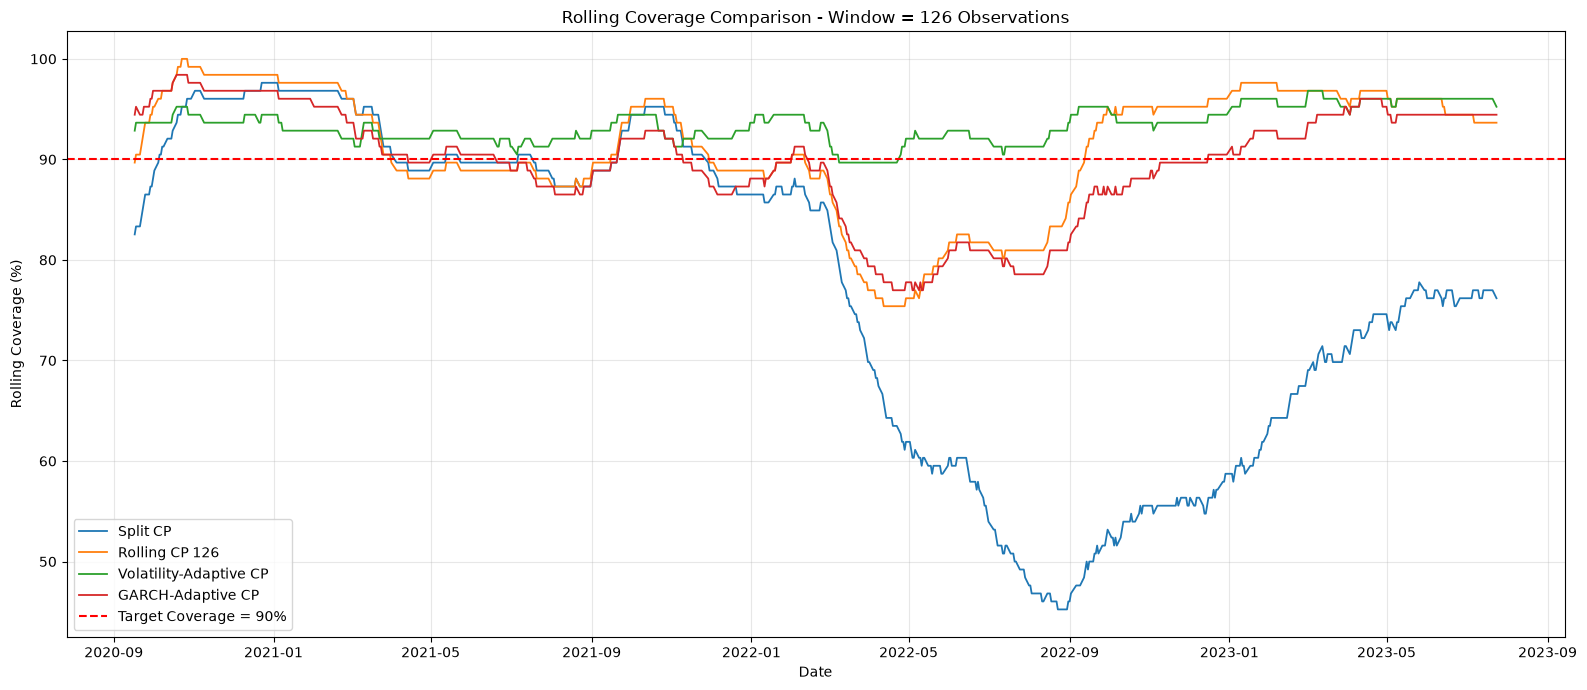

In [175]:

import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(16, 7))

for method, coverage in rolling_coverage_results.items():
    plt.plot(
        reference_dates,
        coverage,
        label=method,
        linewidth=1.3
    )

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Target Coverage = 90%"
)

plt.title(
    "Rolling Coverage Comparison - Window = 126 Observations"
)

plt.xlabel("Date")
plt.ylabel("Rolling Coverage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

Path("figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "figures/rolling_coverage_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


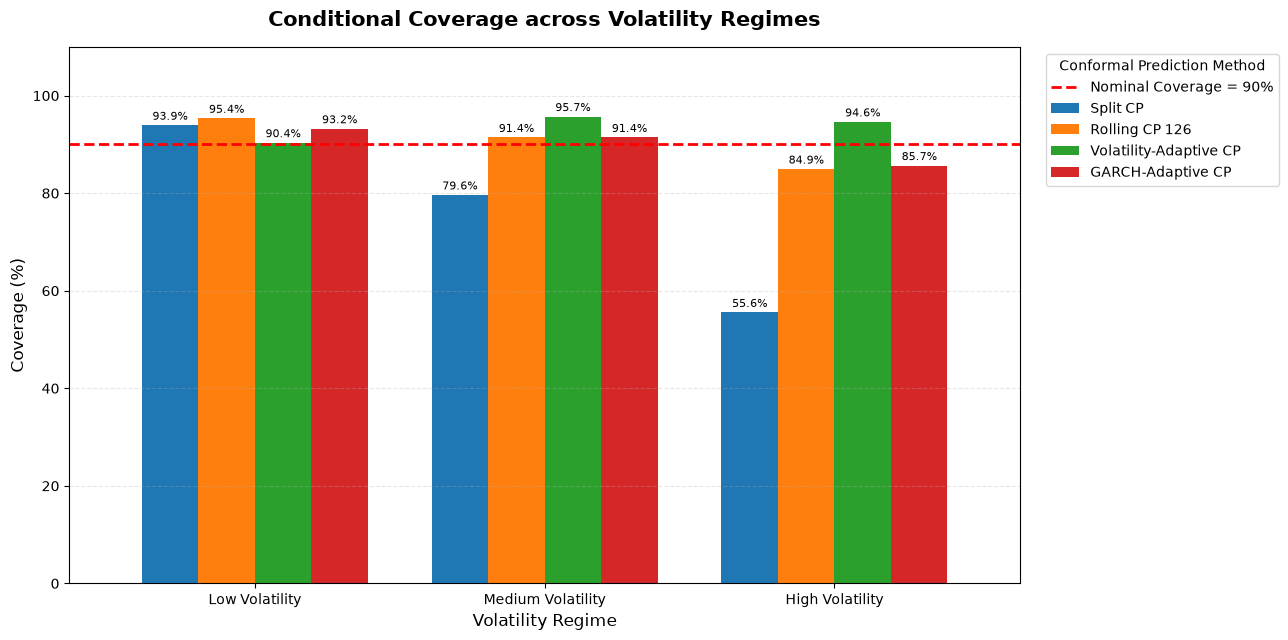

In [176]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Coverage theo ba chế độ biến động
coverage_data = {
    "Method": [
        "Split CP",
        "Rolling CP 126",
        "Volatility-Adaptive CP",
        "GARCH-Adaptive CP"
    ],
    "Low": [
        93.9286, 95.3571, 90.3571, 93.2143
    ],
    "Medium": [
        79.6429, 91.4286, 95.7143, 91.4286
    ],
    "High": [
        55.5556, 84.9462, 94.6237, 85.6631
    ]
}

coverage_df = pd.DataFrame(coverage_data)

# Chuyển dữ liệu sang dạng phù hợp với grouped bar chart
plot_df = coverage_df.set_index("Method")

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(13, 6.5))

plot_df.T.plot(
    kind="bar",
    ax=ax,
    width=0.78
)

# Đường Coverage mục tiêu 90%
ax.axhline(
    y=90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Nominal Coverage = 90%"
)

# Nhãn và tiêu đề
ax.set_title(
    "Conditional Coverage across Volatility Regimes",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Volatility Regime", fontsize=12)
ax.set_ylabel("Coverage (%)", fontsize=12)

ax.set_xticklabels(
    ["Low Volatility", "Medium Volatility", "High Volatility"],
    rotation=0
)

ax.set_ylim(0, 110)
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.legend(
    title="Conformal Prediction Method",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Ghi giá trị trên từng cột
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        fontsize=8,
        padding=2
    )

fig.tight_layout()

# Lưu ảnh
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/cp_coverage_by_regime.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
